<a href="https://www.kaggle.com/code/hardikrunwal/rsna-1?scriptVersionId=363110019" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
import os, random, copy, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support, accuracy_score
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
try:
    import pydicom
except ImportError:
    %pip -q install pydicom pylibjpeg pylibjpeg-libjpeg pylibjpeg-openjpeg
    import pydicom

SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
LABELS=['ACL','Medial Meniscus','Effusion']
MAX_STUDIES=200  # change to None for final training
SLICES=8; IMAGE_SIZE=224; BATCH_SIZE=2; EPOCHS=6; LR=1e-3
FREEZE_BACKBONE=True
PRETRAINED_WEIGHTS_PATH=None  # e.g. '/kaggle/input/resnet18-weights/resnet18.pth'
OUT=Path('/kaggle/working/knee_project'); OUT.mkdir(parents=True,exist_ok=True)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',DEVICE,'Torch:',torch.__version__)

Device: cuda Torch: 2.11.0+cu128


## 1. Locate data and inspect labels

In [2]:
candidates=list(Path('/kaggle/input').rglob('train_series.csv'))
assert candidates, 'train_series.csv not found. Attach the RSNA competition dataset using Add Input.'
ROOT=candidates[0].parent
assert (ROOT/'train.csv').exists(), 'train.csv missing beside train_series.csv'
SERIES_ROOT=ROOT/'train_series'
assert SERIES_ROOT.exists(), 'train_series/ DICOM folder not found'
train=pd.read_csv(ROOT/'train.csv'); series=pd.read_csv(ROOT/'train_series.csv')
print('Dataset root:',ROOT,'Studies:',len(train),'Series:',len(series))
print('Columns:',list(train.columns))
display(train[['StudyInstanceUID']+LABELS].head())
assert all(c in train for c in LABELS)
assert all(c in series for c in ['StudyInstanceUID','SeriesInstanceUID','Fluid_Sensitive','Anatomical_Plane'])

Dataset root: /kaggle/input/competitions/rsna-knee-abnormality-detection Studies: 4407 Series: 24371
Columns: ['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


,StudyInstanceUID,ACL,Medial Meniscus,Effusion
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,NaN,NaN,NaN
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,NaN,NaN,NaN
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,NaN,NaN,NaN


,labeled,positive,negative,positive_rate
ACL,58,24,34,0.413793
Medial Meniscus,58,26,32,0.448276
Effusion,58,35,23,0.603448


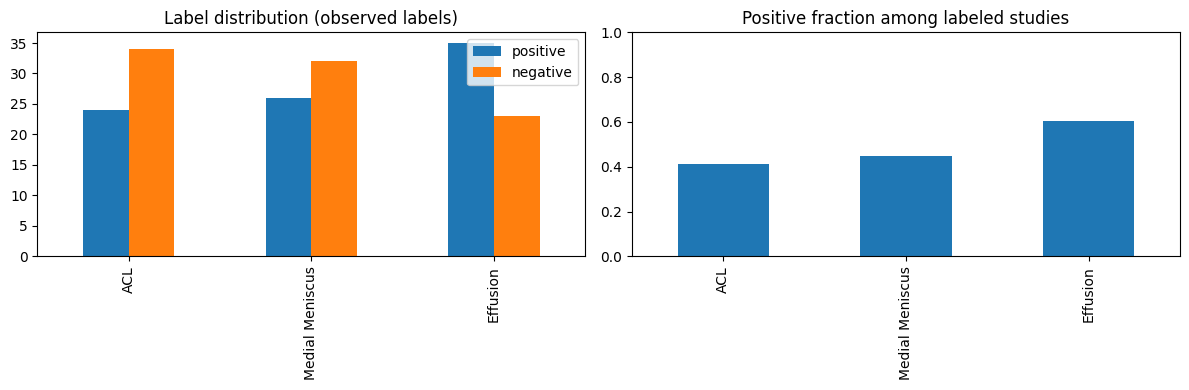

All three labeled: 58
Series per study:


count    4407.000000
mean        5.530066
std         1.393826
min         3.000000
25%         5.000000
50%         5.000000
75%         6.000000
max        14.000000
dtype: float64

Planes:


Anatomical_Plane
Sagittal    9864
Coronal     8609
Axial       5898
Name: count, dtype: int64

In [3]:
summary=pd.DataFrame({'labeled':train[LABELS].notna().sum(), 'positive':(train[LABELS]==1).sum(), 'negative':(train[LABELS]==0).sum()})
summary['positive_rate']=summary['positive']/summary['labeled'].replace(0,np.nan)
display(summary)
fig,ax=plt.subplots(1,2,figsize=(12,4))
summary[['positive','negative']].plot.bar(ax=ax[0],title='Label distribution (observed labels)')
summary['positive_rate'].plot.bar(ax=ax[1],title='Positive fraction among labeled studies',ylim=(0,1))
plt.tight_layout(); plt.savefig(OUT/'eda_labels.png',dpi=160); plt.show()
print('All three labeled:',train[LABELS].notna().all(axis=1).sum())
print('Series per study:'); display(series.groupby('StudyInstanceUID').size().describe())
print('Planes:'); display(series['Anatomical_Plane'].value_counts(dropna=False))

## 2. Select one MRI series per study
Preference: sagittal + fluid-sensitive + fat-suppressed, when available. This is a deliberate simplification and does **not** guarantee that all abnormalities are optimally visible. Selection uses only acquisition metadata, never target labels.

In [4]:
s=series.copy()
s['score']=(s['Anatomical_Plane'].astype(str).str.lower().eq('sagittal').astype(int)*4
            +pd.to_numeric(s['Fluid_Sensitive'],errors='coerce').fillna(0).eq(1).astype(int)*2
            +pd.to_numeric(s.get('Fat_Suppression',pd.Series(0,index=s.index)),errors='coerce').fillna(0).eq(1).astype(int))
s=s.sort_values(['StudyInstanceUID','score'],ascending=[True,False]).drop_duplicates('StudyInstanceUID')
selected=train.merge(s[['StudyInstanceUID','SeriesInstanceUID','Anatomical_Plane','score']],on='StudyInstanceUID',how='inner')
selected=selected[selected[LABELS].notna().all(axis=1)].copy()
selected=selected[selected[LABELS].isin([0,1]).all(axis=1)].copy()
# Restrict to sagittal only, so the input distribution is consistent.
selected=selected[selected['Anatomical_Plane'].astype(str).str.lower().eq('sagittal')].copy()
selected['series_path']=selected.apply(lambda r:str(SERIES_ROOT/str(r.StudyInstanceUID)/str(r.SeriesInstanceUID)),axis=1)
selected=selected[selected.series_path.map(lambda x:Path(x).is_dir() and any(Path(x).glob('*.dcm')))].copy()
print('Eligible studies:',len(selected)); assert len(selected)>=10, 'Too few fully labeled sagittal studies; inspect missingness and change selection policy.'
# Keep a reproducible random subset; stratification is attempted only when feasible.
if MAX_STUDIES is not None and len(selected)>MAX_STUDIES: selected=selected.sample(MAX_STUDIES,random_state=SEED)
selected=selected.reset_index(drop=True)
display(selected[['StudyInstanceUID','SeriesInstanceUID']+LABELS].head())

Eligible studies: 58


,StudyInstanceUID,SeriesInstanceUID,ACL,Medial Meniscus,Effusion
0,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.37372672584387115708...,0.0,0.0,1.0
1,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.55642842745139279565...,0.0,0.0,0.0
2,1.2.826.0.1.3680043.8.498.10306159113324811538...,1.2.826.0.1.3680043.8.498.10903465965639594231...,0.0,1.0,0.0
3,1.2.826.0.1.3680043.8.498.11287937729196958426...,1.2.826.0.1.3680043.8.498.10819304863029245505...,0.0,0.0,1.0
4,1.2.826.0.1.3680043.8.498.11382021393803389951...,1.2.826.0.1.3680043.8.498.91903627435354016135...,1.0,1.0,0.0


## 3. DICOM decoding and sample visualization
Compressed DICOMs may need JPEG decoding libraries. We sort by `ImagePositionPatient` along the slice direction where possible, falling back to `InstanceNumber`. Pixel values are converted to float and robustly normalized per slice. This is an approximation rather than a full clinical DICOM processing pipeline.

Example slices: 36


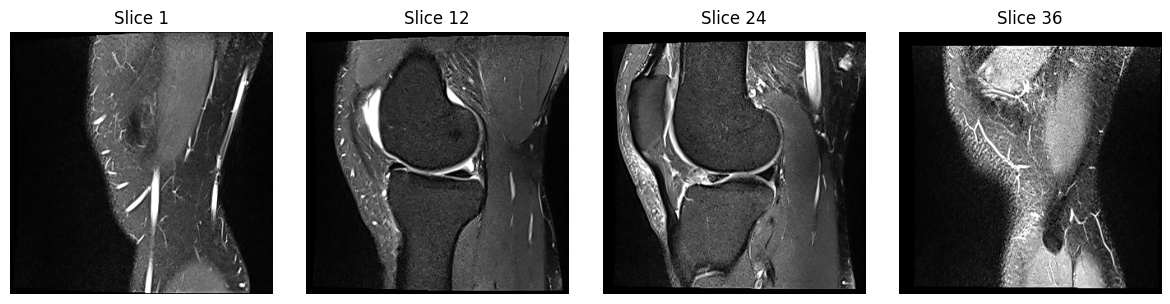

In [5]:
def sorted_dicoms(folder):
    items=[]
    for f in Path(folder).glob('*.dcm'):
        try:
            ds=pydicom.dcmread(str(f),stop_before_pixels=True)
            ipp=getattr(ds,'ImagePositionPatient',None)
            ori=getattr(ds,'ImageOrientationPatient',None)
            if ipp is not None and ori is not None:
                normal=np.cross(np.asarray(ori[:3],dtype=float),np.asarray(ori[3:],dtype=float))
                key=float(np.dot(np.asarray(ipp,dtype=float),normal))
            else: key=float(getattr(ds,'InstanceNumber',0))
            items.append((key,f))
        except Exception as e: warnings.warn(f'Metadata read failed: {f.name}: {e}')
    return [f for _,f in sorted(items,key=lambda x:x[0])]

def read_slice(f):
    ds=pydicom.dcmread(str(f))
    x=ds.pixel_array.astype(np.float32)
    if x.ndim==3: x=x[0]  # rare multi-frame: first frame only
    x=x*float(getattr(ds,'RescaleSlope',1))+float(getattr(ds,'RescaleIntercept',0))
    if getattr(ds,'PhotometricInterpretation','')=='MONOCHROME1': x=x.max()-x
    lo,hi=np.percentile(x,[1,99]); x=np.clip((x-lo)/(hi-lo+1e-6),0,1)
    return x

example=selected.iloc[0]; paths=sorted_dicoms(example.series_path)
print('Example slices:',len(paths))
fig,axes=plt.subplots(1,4,figsize=(12,3))
for ax,j in zip(axes,np.linspace(0,len(paths)-1,4).astype(int)):
    ax.imshow(read_slice(paths[j]),cmap='gray');ax.set_title(f'Slice {j+1}');ax.axis('off')
plt.tight_layout();plt.savefig(OUT/'example_mri.png',dpi=160);plt.show()

## 4. Train-validation split
All slices of a study stay in the same split. This is a study-level holdout; it does not guarantee patient-level or site-level independence because patient/site identifiers are not available here. For a publishable study, verify those groupings if metadata permits.

In [6]:
def safe_split(df):
    # Stratify on a joint label pattern only when every pattern has at least 2 members.
    pattern=df[LABELS].astype(int).astype(str).agg(''.join,axis=1)
    strat=pattern if pattern.value_counts().min()>=2 and pattern.nunique()<=int(np.ceil(len(df)*.2)) else None
    return train_test_split(df,test_size=.2,random_state=SEED,stratify=strat)
tr,va=safe_split(selected)
tr=tr.reset_index(drop=True);va=va.reset_index(drop=True)
assert set(tr.StudyInstanceUID).isdisjoint(set(va.StudyInstanceUID))
tr.to_csv(OUT/'train_split.csv',index=False);va.to_csv(OUT/'val_split.csv',index=False)
print('Train:',len(tr),'Validation:',len(va))
print('Train positive:',tr[LABELS].sum().to_dict());print('Validation positive:',va[LABELS].sum().to_dict())
for label in LABELS:
    if va[label].nunique()<2: warnings.warn(f'Validation has one class for {label}; ROC-AUC undefined. Increase sample size.')

Train: 46 Validation: 12
Train positive: {'ACL': 20.0, 'Medial Meniscus': 21.0, 'Effusion': 27.0}
Validation positive: {'ACL': 4.0, 'Medial Meniscus': 5.0, 'Effusion': 8.0}


## 5. PyTorch dataset and model
Each study produces `SLICES` grayscale slices resized to 224×224. A shared ResNet18 processes slices independently, then **mean-pools their feature vectors** to produce one prediction per study. This avoids incorrectly treating individual slices as independent labeled studies.

In [7]:
import torch.nn.functional as F
class KneeDataset(Dataset):
    def __init__(self,frame): self.frame=frame.reset_index(drop=True)
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]; fs=sorted_dicoms(r.series_path)
        if not fs: raise RuntimeError(f'Empty series {r.series_path}')
        idx=np.linspace(0,len(fs)-1,SLICES).round().astype(int)
        images=[]
        for j in idx:
            x=read_slice(fs[j]); x=torch.from_numpy(x).float()[None,None]
            x=F.interpolate(x,size=(IMAGE_SIZE,IMAGE_SIZE),mode='bilinear',align_corners=False)[0]
            images.append(x)
        x=torch.stack(images) # S,1,H,W
        y=torch.tensor(r[LABELS].astype(float).to_numpy(),dtype=torch.float32)
        return x,y

class KneeNet(nn.Module):
    def __init__(self,pretrained_path=None,freeze=True):
        super().__init__()
        backbone=models.resnet18(weights=None)
        if pretrained_path:
            state=torch.load(pretrained_path,map_location='cpu',weights_only=True)
            if isinstance(state,dict) and 'state_dict' in state:state=state['state_dict']
            state={k.replace('module.',''):v for k,v in state.items()}
            missing,unexpected=backbone.load_state_dict(state,strict=False)
            print('Pretrained loaded; missing:',missing,'unexpected:',unexpected)
        else:
            print('No pretrained weights: ResNet18 is randomly initialized. For transfer learning attach ImageNet weights.')
            freeze=False  # never freeze random features
        backbone.fc=nn.Identity()
        self.encoder=backbone
        self.head=nn.Linear(512,len(LABELS))
        if freeze:
            for param in self.encoder.parameters():param.requires_grad=False
        self.freeze=freeze
    def forward(self,x):
        b,s,c,h,w=x.shape
        x=x.reshape(b*s,c,h,w).repeat(1,3,1,1)
        # ImageNet normalization for pretrained models (also used consistently otherwise)
        mean=x.new_tensor([.485,.456,.406])[None,:,None,None]
        std=x.new_tensor([.229,.224,.225])[None,:,None,None]
        x=(x-mean)/std
        z=self.encoder(x).reshape(b,s,512).mean(1)
        return self.head(z)

model=KneeNet(PRETRAINED_WEIGHTS_PATH,FREEZE_BACKBONE).to(DEVICE)
print('Trainable parameters:',sum(p.numel() for p in model.parameters() if p.requires_grad))

No pretrained weights: ResNet18 is randomly initialized. For transfer learning attach ImageNet weights.
Trainable parameters: 11178051


## 6. Train and save best checkpoint
`BCEWithLogitsLoss` handles independent labels. `pos_weight` is estimated only from the training set. Use validation macro-AUC when defined; otherwise use validation loss for checkpoint selection. Do not report the best validation checkpoint as an unbiased final test estimate.

Epoch 1: train_loss=0.7752 val_loss=19.9350 val_macro_auc=0.5920
Epoch 2: train_loss=0.7346 val_loss=2.1640 val_macro_auc=0.4155
Epoch 3: train_loss=0.7029 val_loss=1.5559 val_macro_auc=0.4345
Epoch 4: train_loss=0.6952 val_loss=2.1156 val_macro_auc=0.4667
Epoch 5: train_loss=0.7362 val_loss=1.7676 val_macro_auc=0.4345
Epoch 6: train_loss=0.6935 val_loss=0.7266 val_macro_auc=0.4753


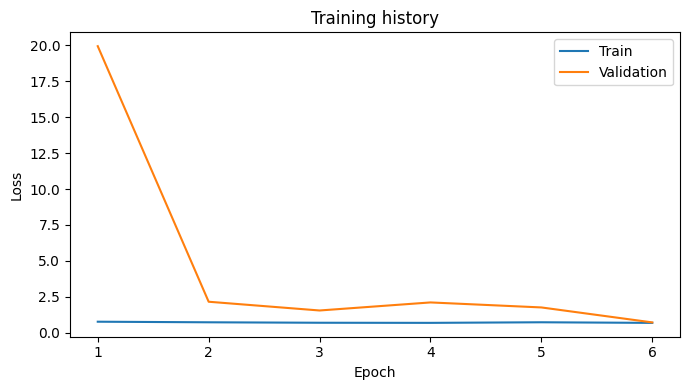

In [8]:
train_ds=KneeDataset(tr);val_ds=KneeDataset(va)
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=2,pin_memory=DEVICE.type=='cuda')
val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=DEVICE.type=='cuda')
pos=tr[LABELS].sum().to_numpy(dtype=float);neg=len(tr)-pos
weights=np.where(pos>0,neg/np.maximum(pos,1),1.0)
loss_fn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weights,dtype=torch.float32,device=DEVICE))
optimizer=torch.optim.AdamW(filter(lambda p:p.requires_grad,model.parameters()),lr=LR)
scaler=torch.amp.GradScaler('cuda',enabled=DEVICE.type=='cuda')

def run_epoch(loader,training):
    model.train(training); total=0; ys=[];ps=[]
    for x,y in loader:
        x=x.to(DEVICE);y=y.to(DEVICE)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=DEVICE.type,enabled=DEVICE.type=='cuda'):
                logits=model(x);loss=loss_fn(logits,y)
            if training:
                scaler.scale(loss).backward();scaler.step(optimizer);scaler.update()
        total+=float(loss.detach())*len(y)
        ys.append(y.detach().cpu().numpy());ps.append(torch.sigmoid(logits.detach()).cpu().numpy())
    y=np.concatenate(ys);pred=np.concatenate(ps)
    aucs=[roc_auc_score(y[:,j],pred[:,j]) if len(np.unique(y[:,j]))==2 else np.nan for j in range(len(LABELS))]
    macro=float(np.nanmean(aucs)) if np.isfinite(aucs).any() else float('nan')
    return total/len(loader.dataset),macro,y,pred

history=[];best=-float('inf')
for epoch in range(1,EPOCHS+1):
    start=time.time()
    tl,ta,_,_=run_epoch(train_loader,True)
    vl,auc,_,_=run_epoch(val_loader,False)
    quality=auc if np.isfinite(auc) else -vl
    history.append({'epoch':epoch,'train_loss':tl,'val_loss':vl,'train_auc':ta,'val_auc':auc,'seconds':time.time()-start})
    print(f'Epoch {epoch}: train_loss={tl:.4f} val_loss={vl:.4f} val_macro_auc={auc:.4f}')
    if quality>best:
        best=quality
        torch.save({'model':model.state_dict(),'labels':LABELS,'slices':SLICES,'image_size':IMAGE_SIZE,'freeze':model.freeze,'pretrained_path_used':bool(PRETRAINED_WEIGHTS_PATH)},OUT/'best.pt')
pd.DataFrame(history).to_csv(OUT/'history.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4));ax.plot([h['epoch'] for h in history],[h['train_loss'] for h in history],label='Train');ax.plot([h['epoch'] for h in history],[h['val_loss'] for h in history],label='Validation');ax.set(xlabel='Epoch',ylabel='Loss',title='Training history');ax.legend();plt.tight_layout();plt.savefig(OUT/'training_curve.png',dpi=160);plt.show()

## 7. Validation report
AUC evaluates ranking; threshold-based metrics use a **fixed 0.5 threshold**, which is not necessarily optimal. In a small dataset, confidence intervals may be wide. AUC is undefined for a label if validation has only one class.

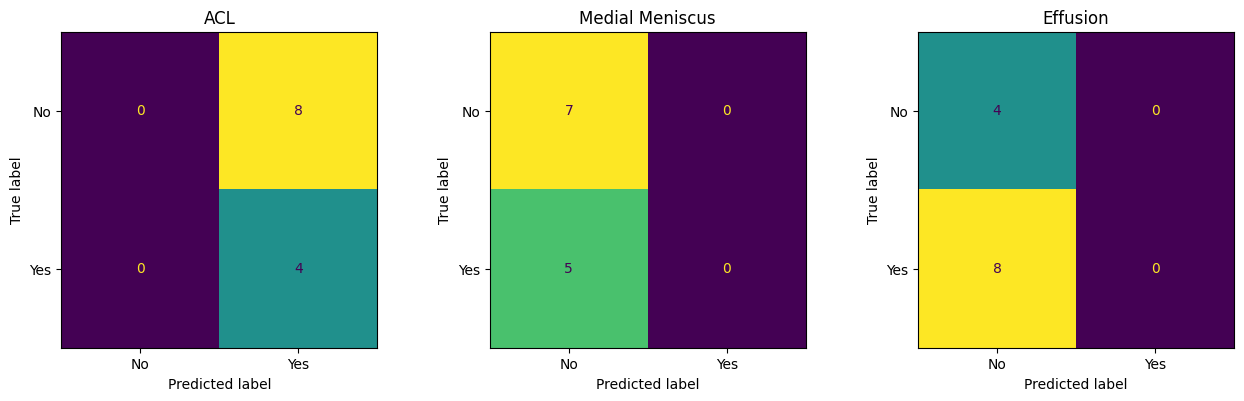

,label,n,positives,accuracy,precision,recall,f1,roc_auc
0,ACL,12,4,0.333333,0.333333,1.0,0.5,0.500000
1,Medial Meniscus,12,5,0.583333,0.000000,0.0,0.0,0.557143
2,Effusion,12,8,0.333333,0.000000,0.0,0.0,0.718750


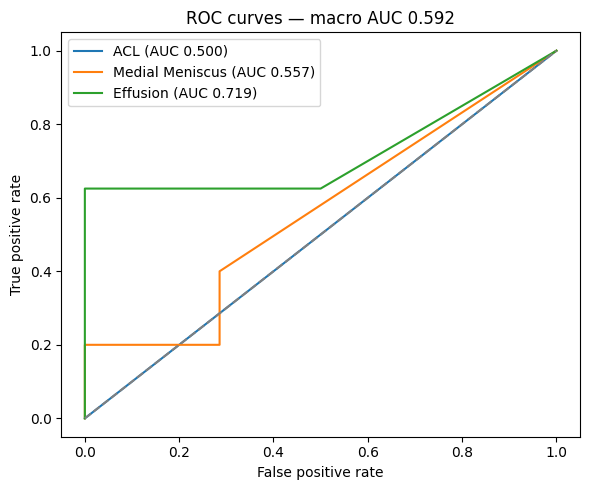

Validation macro ROC-AUC: 0.5919642857142857


In [9]:
ckpt=torch.load(OUT/'best.pt',map_location=DEVICE,weights_only=True)
model.load_state_dict(ckpt['model']);model.eval()
_,macro,y,prob=run_epoch(val_loader,False)
report=[]
fig,axes=plt.subplots(1,3,figsize=(13,4))
for j,label in enumerate(LABELS):
    truth=y[:,j].astype(int);pred=(prob[:,j]>=.5).astype(int)
    pr,rc,f1,_=precision_recall_fscore_support(truth,pred,average='binary',zero_division=0)
    auc=roc_auc_score(truth,prob[:,j]) if len(np.unique(truth))==2 else np.nan
    report.append({'label':label,'n':len(truth),'positives':int(truth.sum()),'accuracy':accuracy_score(truth,pred),'precision':pr,'recall':rc,'f1':f1,'roc_auc':auc})
    ConfusionMatrixDisplay(confusion_matrix(truth,pred,labels=[0,1]),display_labels=['No','Yes']).plot(ax=axes[j],colorbar=False)
    axes[j].set_title(label)
plt.tight_layout();plt.savefig(OUT/'confusion_matrices.png',dpi=160);plt.show()
metrics=pd.DataFrame(report);display(metrics);metrics.to_csv(OUT/'metrics.csv',index=False)
fig,ax=plt.subplots(figsize=(6,5))
for j,label in enumerate(LABELS):
    if len(np.unique(y[:,j]))==2:
        fpr,tpr,_=roc_curve(y[:,j],prob[:,j]);ax.plot(fpr,tpr,label=f'{label} (AUC {metrics.iloc[j].roc_auc:.3f})')
ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='False positive rate',ylabel='True positive rate',title=f'ROC curves — macro AUC {macro:.3f}');ax.legend();plt.tight_layout();plt.savefig(OUT/'roc_curves.png',dpi=160);plt.show()
preds=va[['StudyInstanceUID']+LABELS].copy()
for j,label in enumerate(LABELS):preds['pred_'+label]=prob[:,j]
preds.to_csv(OUT/'validation_predictions.csv',index=False)
print('Validation macro ROC-AUC:',macro)

## 8. Faculty demonstration: predict one validation study
Use an existing study, not an arbitrary single slice. The outputs are model scores and are **not calibrated clinical probabilities**.

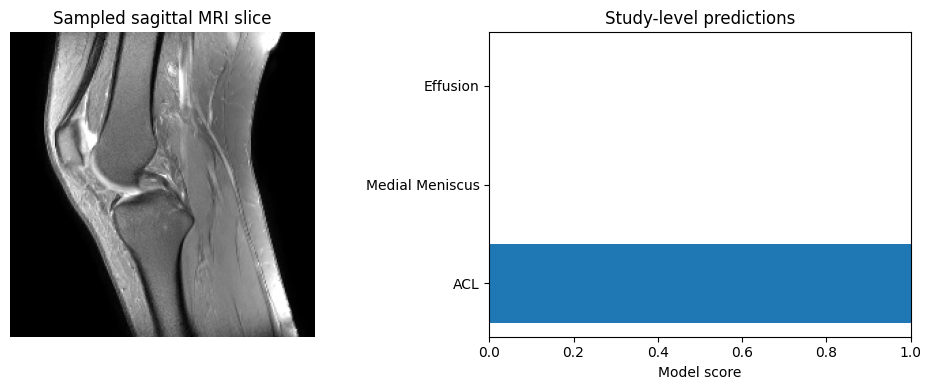

Study: 1.2.826.0.1.3680043.8.498.69392348385274125385290015404144639002
True labels: {'ACL': 0.0, 'Medial Meniscus': 0.0, 'Effusion': 0.0}
Scores: {'ACL': np.float16(1.0), 'Medial Meniscus': np.float16(0.0), 'Effusion': np.float16(0.0)}


In [10]:
demo_idx=0
row=va.iloc[demo_idx]
x,_=val_ds[demo_idx]
with torch.no_grad():
    with torch.autocast(device_type=DEVICE.type,enabled=DEVICE.type=='cuda'):
        scores=torch.sigmoid(model(x[None].to(DEVICE)))[0].cpu().numpy()
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].imshow(x[len(x)//2,0],cmap='gray');axes[0].axis('off');axes[0].set_title('Sampled sagittal MRI slice')
axes[1].barh(LABELS,scores);axes[1].set_xlim(0,1);axes[1].set_xlabel('Model score');axes[1].set_title('Study-level predictions')
plt.tight_layout();plt.savefig(OUT/'faculty_demo.png',dpi=160);plt.show()
print('Study:',row.StudyInstanceUID)
print('True labels:',row[LABELS].to_dict())
print('Scores:',dict(zip(LABELS,scores.round(3))))

## 9. Limitations and suggested experiments
- Only sagittal series and 8 slices: relevant findings may be missed. Study-level labels are weak supervision for individual slices.
- Complete-case filtering may introduce selection bias. Reports are **not** used; extracting labels from reports requires careful multilingual negation and uncertainty handling.
- Site/scanner differences can affect generalization; patient/site-disjoint evaluation would be preferable if identifiers exist.
- Transfer learning requires a separately attached pretrained checkpoint; without one this notebook trains from scratch.
- The same validation set is used for checkpoint selection and reporting. For stronger final claims, reserve a separate untouched test set.

**Experiments:** (A) scratch ResNet18 vs ImageNet-pretrained ResNet18; (B) frozen backbone vs fine-tuning; (C) 8 vs 16 slices. Keep the split and random seed fixed, and compare per-label AUC and runtime.

**Suggested presentation:** motivation → 12 available findings vs 3 chosen → EDA and missingness → sample DICOM → preprocessing → architecture → training curve → ROC and confusion matrices → demo → limitations.

**Clinical disclaimer:** Research/educational prototype; not intended for diagnosis or treatment.

DATASET INFORMATION
Studies: 4407
MRI series: 24371
Reports available: 4407
Unique study IDs: 4407


,Positive,Negative,Missing,Annotated,Positive_Rate
ACL,24,34,4349,58,0.413793
Medial Meniscus,26,32,4349,58,0.448276
Effusion,35,23,4349,58,0.603448



Number of observed labels per study:
0    4349
3      58
Name: count, dtype: int64

Verified studies: 58
Fully unlabeled studies: 4349
Rule development subset: 40
Rule audit subset: 18

EXTRACTION COMPLETED

INDEPENDENT AUDIT RESULTS


,Label,Audit_Studies,Covered,Coverage,Accuracy_On_Covered,Precision_On_Covered,Recall_On_Covered,F1_On_Covered,End_To_End_Positive_Recall
0,ACL,18,8,0.444,0.875,0.833,1.0,0.909,1.000
1,Medial Meniscus,18,4,0.222,1.000,1.000,1.0,1.000,0.286
2,Effusion,18,10,0.556,0.700,0.667,1.0,0.800,0.545



Incorrect covered predictions: 4

PSEUDO-LABEL COVERAGE


,Positive,Negative,Unknown,Available,Coverage
ACL,344,592,3413,936,0.215222
Medial Meniscus,721,354,3274,1075,0.247183
Effusion,963,398,2988,1361,0.312946


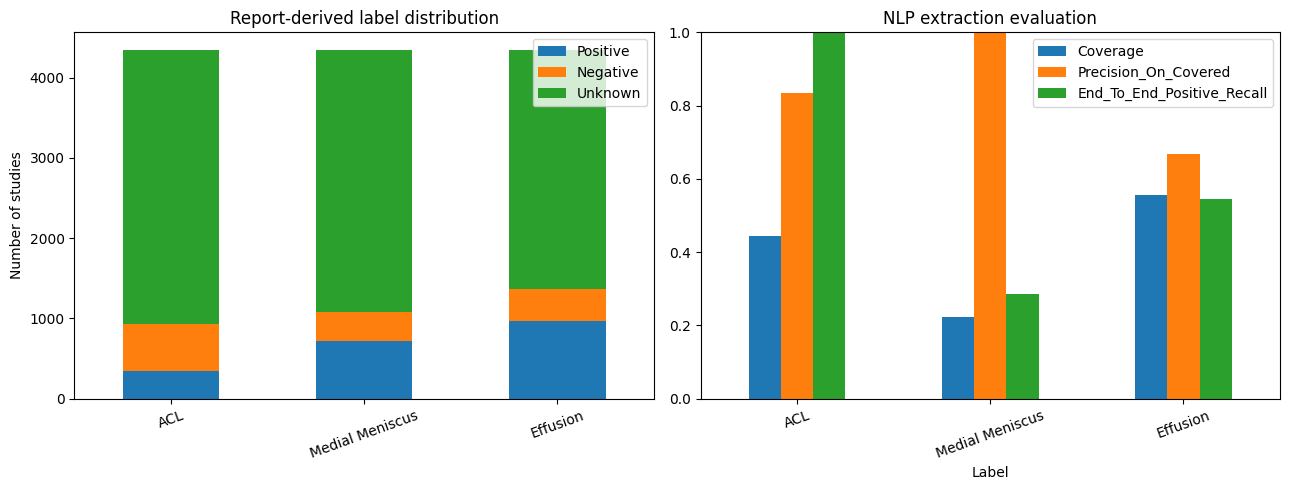


PHASE 3 SUMMARY
Total studies: 4407
Verified studies: 58
Unlabeled studies: 4349
Candidate pseudo-labeled studies: 1796
Studies with all 3 pseudo-labels: 500

Files saved to: /kaggle/working/knee_report_nlp
 - candidate_pseudo_labels.csv
 - label_audit.csv
 - nlp_errors.csv
 - nlp_evaluation.csv
 - pseudo_label_coverage.csv
 - report_extraction_results.png
 - rule_audit_verified.csv
 - rule_development_verified.csv
 - verified_labels.csv

IMPORTANT:
Review the audit metrics and error cases before
using candidate pseudo-labels for MRI model training.


In [6]:

# ============================================================
# RSNA KNEE MRI — PHASE 3
# RADIOLOGY REPORT ANALYSIS AND PSEUDO-LABEL GENERATION
#
# Platform: Kaggle Notebook
# Purpose:
#   1. Audit 4,407 MRI studies and radiology reports
#   2. Extract three findings from report text
#   3. Handle positive, negative and uncertain statements
#   4. Evaluate against verified labels
#   5. Export conservative pseudo-labels for future MRI training
#
# IMPORTANT:
#   - This is a rule-based NLP baseline, not a clinical NLP system.
#   - Reports are used for training-label generation only.
#   - The final MRI model will not require reports at inference.
#   - Unrecognized findings remain UNKNOWN, never negative.
# ============================================================

import re
import json
import random
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path(
    "/kaggle/input/competitions/rsna-knee-abnormality-detection"
)

OUT = Path("/kaggle/working/knee_report_nlp")
OUT.mkdir(parents=True, exist_ok=True)

LABELS = ["ACL", "Medial Meniscus", "Effusion"]

assert (ROOT / "train.csv").exists(), "train.csv not found"
assert (ROOT / "train_series.csv").exists(), "train_series.csv not found"

train = pd.read_csv(ROOT / "train.csv")
series = pd.read_csv(ROOT / "train_series.csv")

for label in LABELS:
    train[label] = pd.to_numeric(
        train[label], errors="coerce"
    )

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)
print("Studies:", len(train))
print("MRI series:", len(series))
print("Reports available:", train["Report"].notna().sum())
print("Unique study IDs:", train["StudyInstanceUID"].nunique())

# ------------------------------------------------------------
# 2. LABEL AUDIT
# ------------------------------------------------------------

audit = pd.DataFrame({
    "Positive": (train[LABELS] == 1).sum(),
    "Negative": (train[LABELS] == 0).sum(),
    "Missing": train[LABELS].isna().sum()
})

audit["Annotated"] = audit["Positive"] + audit["Negative"]
audit["Positive_Rate"] = (
    audit["Positive"] / audit["Annotated"].replace(0, np.nan)
)

display(audit)
audit.to_csv(OUT / "label_audit.csv")

# Check whether partially labeled studies exist.
observed_count = train[LABELS].notna().sum(axis=1)

print("\nNumber of observed labels per study:")
print(observed_count.value_counts().sort_index())

# ------------------------------------------------------------
# 3. SEPARATE VERIFIED STUDIES FROM UNLABELED STUDIES
# ------------------------------------------------------------

verified = train[
    train[LABELS].notna().all(axis=1)
].copy()

unlabeled = train[
    train[LABELS].isna().all(axis=1)
].copy()

print("\nVerified studies:", len(verified))
print("Fully unlabeled studies:", len(unlabeled))

# The verified studies are split before evaluating extraction.
# We do not use audit-holdout reports to revise the rules.
#
# The rules below are a predefined baseline.
# If rules are later modified after inspecting holdout errors,
# that holdout is no longer an independent evaluation set.

dev_verified, audit_verified = train_test_split(
    verified,
    test_size=0.30,
    random_state=SEED
)

print("Rule development subset:", len(dev_verified))
print("Rule audit subset:", len(audit_verified))

# ------------------------------------------------------------
# 4. TEXT NORMALIZATION
# ------------------------------------------------------------

def normalize_text(text):
    """
    Normalize Unicode, accents, whitespace and casing.

    Example:
       'Épanchement articulaire'
       -> 'epanchement articulaire'
    """
    if pd.isna(text):
        return ""

    text = unicodedata.normalize("NFKD", str(text))
    text = "".join(
        ch for ch in text
        if not unicodedata.combining(ch)
    )

    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()


# ------------------------------------------------------------
# 5. MEDICAL REPORT RULES
# ------------------------------------------------------------
#
# Each label has:
#   - Positive expressions
#   - Negative expressions
#   - Uncertain expressions
#
# Rules are not exhaustive.
# In particular, complex Greek, Turkish, Dutch and Bulgarian
# findings will often be left UNKNOWN.
#
# Never treat mere mention of a structure as abnormality.
# ------------------------------------------------------------

RULES = {
    "ACL": {
        "positive": [
            r"\bacl\b.{0,45}\b(tear|ruptur|sprain|injur)",
            r"\b(tear|ruptur|sprain|injur).{0,45}\bacl\b",
            r"anterior cruciate ligament.{0,45}(tear|ruptur|sprain|injur)",
            r"(tear|ruptur|sprain|injur).{0,45}anterior cruciate ligament",
            r"rotura.{0,30}\blca\b",
            r"\blca\b.{0,30}rotura",
            r"ruptura.{0,30}\blca\b",
            r"ligament croise anterieur.{0,40}(rupture|entorse)",
            r"(rupture|entorse).{0,40}ligament croise anterieur",
        ],
        "negative": [
            r"\bacl\b.{0,25}(intact|normal|preserved)",
            r"anterior cruciate ligament.{0,30}(intact|normal)",
            r"no.{0,25}(tear|injury).{0,25}\bacl\b",
            r"no.{0,25}\bacl\b.{0,25}(tear|injury)",
            r"\blca\b.{0,30}(normal|integro|intacto)",
            r"ligament croise anterieur.{0,25}(normal|intact)",
        ],
        "uncertain": [
            r"(possible|suspect|questionable|cannot exclude|rule out|r/o)"
            r".{0,50}(acl|anterior cruciate)",
            r"(acl|anterior cruciate).{0,50}"
            r"(possible|suspect|questionable)",
        ]
    },

    "Medial Meniscus": {
        "positive": [
            r"medial meniscus.{0,45}(tear|ruptur|torn)",
            r"(tear|ruptur|torn).{0,45}medial meniscus",
            r"medial meniscal.{0,35}(tear|ruptur)",
            r"menisco medial.{0,35}(rotura|ruptura)",
            r"(rotura|ruptura).{0,35}menisco medial",
            r"rotura de menisco interno",
            r"menisque medial.{0,35}(dechirure|rupture)",
            r"(dechirure|rupture).{0,35}menisque medial",
        ],
        "negative": [
            r"medial meniscus.{0,35}(normal|intact|not torn|no tear)",
            r"no.{0,30}tear.{0,30}medial meniscus",
            r"medial meniscus.{0,30}without tear",
            r"menisco medial.{0,40}(sin signos de rotura|normal)",
            r"menisque medial.{0,35}(normal|sans dechirure)",
        ],
        "uncertain": [
            r"(possible|suspect|questionable|cannot exclude|rule out|r/o)"
            r".{0,50}(medial meniscus|medial meniscal)",
            r"(medial meniscus|medial meniscal).{0,50}"
            r"(possible|suspect|questionable)",
        ]
    },

    "Effusion": {
        "positive": [
            r"(small|mild|moderate|large|marked|minimal|trace|significant)"
            r".{0,20}(joint |knee )?effusion",
            r"(joint |knee )?effusion.{0,25}(present|noted|seen)",
            r"there is.{0,25}(joint |knee )?effusion",
            r"derrame articular",
            r"\bderrame\b",
            r"epanchement articulaire",
            r"joint fluid accumulation",
        ],
        "negative": [
            r"no.{0,25}(joint |knee )?effusion",
            r"without.{0,25}(joint |knee )?effusion",
            r"absence of.{0,25}(joint |knee )?effusion",
            r"no hay.{0,25}derrame",
            r"sin.{0,25}derrame",
            r"pas de.{0,25}epanchement",
            r"absence d.epanchement",
        ],
        "uncertain": [
            r"(possible|suspected|questionable|cannot exclude)"
            r".{0,30}effusion",
        ]
    }
}

# ------------------------------------------------------------
# 6. EXTRACT INDIVIDUAL SENTENCES
# ------------------------------------------------------------
#
# We use short report segments to reduce the risk that
# a negation referring to one structure affects another.
# This remains imperfect for complex report formatting.
# ------------------------------------------------------------

def split_segments(text):
    text = normalize_text(text)

    segments = re.split(r"[.;\n]+", text)

    return [
        segment.strip()
        for segment in segments
        if segment.strip()
    ]


# ------------------------------------------------------------
# 7. FIND EVIDENCE IN EACH SEGMENT
# ------------------------------------------------------------

def classify_segment(segment, label):
    rules = RULES[label]

    # Uncertainty takes priority over definite classification.
    if any(
        re.search(pattern, segment)
        for pattern in rules["uncertain"]
    ):
        return "uncertain"

    negative = any(
        re.search(pattern, segment)
        for pattern in rules["negative"]
    )

    positive = any(
        re.search(pattern, segment)
        for pattern in rules["positive"]
    )

    # General negation check near a matched positive expression.
    # This is only a conservative safeguard.
    negation = bool(re.search(
        r"\b(no|not|without|absence of|sin|pas de|"
        r"no hay|aucun|aucune)\b",
        segment
    ))

    if negative and positive:
        return "conflict"

    if negative:
        return "negative"

    if positive and negation:
        return "uncertain"

    if positive:
        return "positive"

    return "unknown"


def extract_label(report, label):
    """
    Returns:
      1.0  = positive
      0.0  = negative
      NaN  = unknown, uncertain or conflicting

    Also returns evidence for manual inspection.
    """
    segments = split_segments(report)

    findings = []

    for segment in segments:
        status = classify_segment(segment, label)

        if status != "unknown":
            findings.append((status, segment))

    statuses = {status for status, _ in findings}

    if "conflict" in statuses or "uncertain" in statuses:
        prediction = np.nan

    elif "positive" in statuses and "negative" in statuses:
        prediction = np.nan

    elif "positive" in statuses:
        prediction = 1.0

    elif "negative" in statuses:
        prediction = 0.0

    else:
        prediction = np.nan

    evidence = " | ".join(
        f"[{status}] {segment[:180]}"
        for status, segment in findings[:5]
    )

    return prediction, evidence


# ------------------------------------------------------------
# 8. APPLY REPORT EXTRACTION TO ALL STUDIES
# ------------------------------------------------------------

results = train[
    ["StudyInstanceUID", "Report"] + LABELS
].copy()

for label in LABELS:
    extracted = results["Report"].apply(
        lambda report: extract_label(report, label)
    )

    results[f"NLP_{label}"] = extracted.apply(
        lambda value: value[0]
    )

    results[f"Evidence_{label}"] = extracted.apply(
        lambda value: value[1]
    )

print("\nEXTRACTION COMPLETED")

# ------------------------------------------------------------
# 9. VALIDATE AGAINST THE INDEPENDENT AUDIT SUBSET
# ------------------------------------------------------------

audit_results = results[
    results["StudyInstanceUID"].isin(
        audit_verified["StudyInstanceUID"]
    )
].copy()

evaluation_rows = []

for label in LABELS:
    truth = audit_results[label]
    pred = audit_results[f"NLP_{label}"]

    covered = pred.notna()

    n_total = len(audit_results)
    n_covered = int(covered.sum())

    if n_covered > 0:
        y_true = truth[covered].astype(int)
        y_pred = pred[covered].astype(int)

        precision = precision_score(
            y_true, y_pred, zero_division=0
        )

        recall_covered = recall_score(
            y_true, y_pred, zero_division=0
        )

        f1 = f1_score(
            y_true, y_pred, zero_division=0
        )

        correct = (y_true == y_pred).sum()
        accuracy = correct / n_covered

    else:
        precision = np.nan
        recall_covered = np.nan
        f1 = np.nan
        accuracy = np.nan

    # End-to-end positive recall counts abstentions as misses.
    positives = int((truth == 1).sum())
    true_positive = int(
        ((truth == 1) & (pred == 1)).sum()
    )

    end_to_end_recall = (
        true_positive / positives
        if positives else np.nan
    )

    evaluation_rows.append({
        "Label": label,
        "Audit_Studies": n_total,
        "Covered": n_covered,
        "Coverage": n_covered / n_total,
        "Accuracy_On_Covered": accuracy,
        "Precision_On_Covered": precision,
        "Recall_On_Covered": recall_covered,
        "F1_On_Covered": f1,
        "End_To_End_Positive_Recall": end_to_end_recall
    })

evaluation = pd.DataFrame(evaluation_rows)

print("\nINDEPENDENT AUDIT RESULTS")
display(evaluation.round(3))

evaluation.to_csv(
    OUT / "nlp_evaluation.csv",
    index=False
)

# ------------------------------------------------------------
# 10. CREATE ERROR ANALYSIS TABLE
# ------------------------------------------------------------

errors = []

for label in LABELS:
    pred = audit_results[f"NLP_{label}"]

    incorrect = (
        pred.notna() &
        (pred != audit_results[label])
    )

    for _, row in audit_results[incorrect].iterrows():
        errors.append({
            "StudyInstanceUID": row["StudyInstanceUID"],
            "Label": label,
            "True": row[label],
            "Predicted": row[f"NLP_{label}"],
            "Evidence": row[f"Evidence_{label}"],
            "Report": row["Report"]
        })

error_df = pd.DataFrame(errors)

error_df.to_csv(
    OUT / "nlp_errors.csv",
    index=False
)

print("\nIncorrect covered predictions:", len(error_df))

# ------------------------------------------------------------
# 11. PSEUDO-LABEL COVERAGE
# ------------------------------------------------------------

# Use only originally unlabeled studies.
# Verified studies are never overwritten.

pseudo = results[
    results["StudyInstanceUID"].isin(
        unlabeled["StudyInstanceUID"]
    )
].copy()

for label in LABELS:
    pseudo[label] = pseudo[f"NLP_{label}"]

pseudo["Known_Label_Count"] = (
    pseudo[LABELS].notna().sum(axis=1)
)

pseudo["Pseudo_Label_Count"] = (
    pseudo[LABELS].notna().sum(axis=1)
)

coverage_table = pd.DataFrame({
    "Positive": (pseudo[LABELS] == 1).sum(),
    "Negative": (pseudo[LABELS] == 0).sum(),
    "Unknown": pseudo[LABELS].isna().sum()
})

coverage_table["Available"] = (
    coverage_table["Positive"] +
    coverage_table["Negative"]
)

coverage_table["Coverage"] = (
    coverage_table["Available"] / len(pseudo)
)

print("\nPSEUDO-LABEL COVERAGE")
display(coverage_table)

coverage_table.to_csv(
    OUT / "pseudo_label_coverage.csv"
)

# ------------------------------------------------------------
# 12. VISUALIZE EXTRACTION RESULTS
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

coverage_table[
    ["Positive", "Negative", "Unknown"]
].plot(
    kind="bar",
    stacked=True,
    ax=axes[0]
)

axes[0].set_title("Report-derived label distribution")
axes[0].set_ylabel("Number of studies")
axes[0].tick_params(axis="x", rotation=20)

evaluation.set_index("Label")[
    ["Coverage", "Precision_On_Covered",
     "End_To_End_Positive_Recall"]
].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("NLP extraction evaluation")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(
    OUT / "report_extraction_results.png",
    dpi=220,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 13. EXPORT CANDIDATE PSEUDO-LABELS
# ------------------------------------------------------------
#
# IMPORTANT:
# These are CANDIDATE labels, not automatically trusted labels.
# We must review errors and estimate precision before training.
#
# Keep evidence and missing labels for auditing.
# ------------------------------------------------------------

candidate = pseudo[
    pseudo["Pseudo_Label_Count"] >= 1
].copy()

export_cols = (
    ["StudyInstanceUID", "Report"] +
    LABELS +
    [f"Evidence_{label}" for label in LABELS] +
    ["Pseudo_Label_Count"]
)

candidate[export_cols].to_csv(
    OUT / "candidate_pseudo_labels.csv",
    index=False
)

# ------------------------------------------------------------
# 14. SAVE ORIGINAL VERIFIED LABELS SEPARATELY
# ------------------------------------------------------------

verified.to_csv(
    OUT / "verified_labels.csv",
    index=False
)

dev_verified.to_csv(
    OUT / "rule_development_verified.csv",
    index=False
)

audit_verified.to_csv(
    OUT / "rule_audit_verified.csv",
    index=False
)

# ------------------------------------------------------------
# 15. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PHASE 3 SUMMARY")
print("=" * 70)

print("Total studies:", len(train))
print("Verified studies:", len(verified))
print("Unlabeled studies:", len(unlabeled))

print(
    "Candidate pseudo-labeled studies:",
    len(candidate)
)

print(
    "Studies with all 3 pseudo-labels:",
    int((pseudo["Pseudo_Label_Count"] == 3).sum())
)

print("\nFiles saved to:", OUT)

for path in sorted(OUT.glob("*")):
    print(" -", path.name)

print("\nIMPORTANT:")
print("Review the audit metrics and error cases before")
print("using candidate pseudo-labels for MRI model training.")


In [11]:
# ============================================================
# PHASE 4: MRI-ONLY WEAKLY SUPERVISED CLASSIFICATION
# Kaggle GPU | ResNet18 | ACL, Medial Meniscus, Effusion
#
# Experiments:
# E1: Verified labels only
# E2: Report-derived pseudo-labels only
# E3: Verified + report-derived pseudo-labels
#
# Reports are NEVER passed to the CNN.
# ============================================================

import os, gc, copy, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

# ---------------- CONFIGURATION ----------------

SEED = 42
LABELS = ["ACL", "Medial Meniscus", "Effusion"]

ROOT = Path(
    "/kaggle/input/competitions/rsna-knee-abnormality-detection"
)

PHASE3 = Path("/kaggle/working/knee_report_nlp")
OUT = Path("/kaggle/working/knee_phase4")
OUT.mkdir(parents=True, exist_ok=True)

SLICES = 8
SIZE = 224
BATCH_SIZE = 2
EPOCHS = 8
LR = 1e-4
MAX_PSEUDO = 500   # Start small; increase after testing.

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if DEVICE == "cuda":
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)

# ---------------- LOAD DATA ----------------

train = pd.read_csv(ROOT / "train.csv")
series = pd.read_csv(ROOT / "train_series.csv")

pseudo_path = PHASE3 / "candidate_pseudo_labels.csv"

assert pseudo_path.exists(), (
    "Run Phase 3 first or attach its saved CSV outputs."
)

pseudo = pd.read_csv(pseudo_path)

for df in [train, pseudo]:
    for label in LABELS:
        df[label] = pd.to_numeric(
            df[label], errors="coerce"
        )

verified = train[
    train[LABELS].notna().all(axis=1)
].copy()

# ---------------- STUDY-LEVEL SPLIT ----------------
# Reserve verified studies before training.
# These validation studies are excluded from all training.
#
# For final research results, reserve a second untouched
# test split and use validation only for model selection.

verified_train, verified_val = train_test_split(
    verified,
    test_size=0.25,
    random_state=SEED
)

# Remove any possible overlapping IDs.
excluded = set(verified["StudyInstanceUID"])

pseudo = pseudo[
    ~pseudo["StudyInstanceUID"].isin(excluded)
].copy()

# Keep only studies with at least one known pseudo-label.
pseudo = pseudo[
    pseudo[LABELS].notna().any(axis=1)
].copy()

# ---------------- SERIES SELECTION ----------------
# Select one preferred sagittal MRI series per study.

series["priority"] = (
    4 * series["Anatomical_Plane"].eq("Sagittal").astype(int)
    + 2 * pd.to_numeric(
        series["Fluid_Sensitive"], errors="coerce"
    ).fillna(0)
    + pd.to_numeric(
        series["Fat_Suppression"], errors="coerce"
    ).fillna(0)
)

best_series = (
    series.sort_values(
        ["priority", "SeriesInstanceUID"],
        ascending=[False, True]
    )
    .drop_duplicates("StudyInstanceUID")
)

def attach_series(df):
    return df.merge(
        best_series[
            ["StudyInstanceUID", "SeriesInstanceUID"]
        ],
        on="StudyInstanceUID",
        how="inner"
    )

verified_train = attach_series(verified_train)
verified_val = attach_series(verified_val)
pseudo = attach_series(pseudo)

# Use a fixed pseudo-label subset for fair comparisons.
pseudo = pseudo.sample(
    n=min(MAX_PSEUDO, len(pseudo)),
    random_state=SEED
)

print("Verified training:", len(verified_train))
print("Verified validation:", len(verified_val))
print("Pseudo-labeled:", len(pseudo))

print("\nValidation label counts:")
for label in LABELS:
    print(
        label,
        "positive:", int((verified_val[label] == 1).sum()),
        "negative:", int((verified_val[label] == 0).sum())
    )

# ---------------- DICOM PREPROCESSING ----------------

SERIES_ROOT = ROOT / "train_series"

def read_study(row):
    folder = (
        SERIES_ROOT /
        str(row["StudyInstanceUID"]) /
        str(row["SeriesInstanceUID"])
    )

    files = sorted(folder.glob("*.dcm"))

    if not files:
        raise FileNotFoundError(folder)

    # Prefer geometric slice ordering when available.
    headers = []
    for file in files:
        ds = pydicom.dcmread(
            str(file), stop_before_pixels=True
        )
        position = getattr(ds, "ImagePositionPatient", None)
        instance = getattr(ds, "InstanceNumber", None)
        headers.append((file, position, instance))

    if all(h[1] is not None for h in headers):
        # Position ordering is an approximation for oblique
        # acquisitions; a production pipeline should project
        # positions onto the slice-normal vector.
        axis = int(np.argmax(
            np.ptp(
                np.array([h[1] for h in headers], dtype=float),
                axis=0
            )
        ))
        headers.sort(key=lambda h: float(h[1][axis]))
    elif all(h[2] is not None for h in headers):
        headers.sort(key=lambda h: int(h[2]))

    indices = np.linspace(
        0, len(headers) - 1, SLICES
    ).round().astype(int)

    images = []

    for idx in indices:
        ds = pydicom.dcmread(str(headers[idx][0]))
        img = ds.pixel_array.astype(np.float32)

        slope = float(getattr(ds, "RescaleSlope", 1))
        intercept = float(getattr(ds, "RescaleIntercept", 0))
        img = img * slope + intercept

        if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
            img = img.max() + img.min() - img

        lo, hi = np.percentile(img, [1, 99])
        
        img = np.clip(img, lo, hi)
        
        img = (img - lo) / max(hi - lo, 1e-6)
        
        # Ensure float32 after normalization
        img = img.astype(np.float32, copy=False)
        
        tensor = torch.from_numpy(img)[None, None]
        
        tensor = F.interpolate(
            tensor,
            size=(SIZE, SIZE),
            mode="bilinear",
            align_corners=False
        )
        
        images.append(tensor[0].float())
    # [Slices, 1, Height, Width]
    return torch.stack(images)

# ---------------- DATASET ----------------

class KneeDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]

        images = read_study(row)

        values = row[LABELS].to_numpy(
            dtype=np.float32
        )

        mask = np.isfinite(values).astype(np.float32)
        targets = np.nan_to_num(values, nan=0.0)

        return (
            images,
            torch.tensor(targets),
            torch.tensor(mask)
        )

Device: cuda
Verified training: 43
Verified validation: 15
Pseudo-labeled: 500

Validation label counts:
ACL positive: 3 negative: 12
Medial Meniscus positive: 6 negative: 9
Effusion positive: 10 negative: 5


In [16]:
# ---------------- MODEL ----------------

class KneeResNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Random initialization for controlled comparison.
        # Pretrained weights will be added in the next ablation.
        self.encoder = resnet18(weights=None)

        # MRI images are grayscale.
        self.encoder.conv1 = nn.Conv2d(
            1, 64, kernel_size=7,
            stride=2, padding=3, bias=False
        )

        features = self.encoder.fc.in_features
        self.encoder.fc = nn.Identity()

        self.head = nn.Linear(features, len(LABELS))

    def forward(self, x):
        b, s, c, h, w = x.shape

        x = x.reshape(b * s, c, h, w)

        features = self.encoder(x)
        features = features.reshape(b, s, -1)

        # Mean pooling across MRI slices.
        features = features.mean(dim=1)

        return self.head(features)

# ---------------- MASKED LOSS ----------------

def masked_loss(logits, targets, mask):
    loss = F.binary_cross_entropy_with_logits(
        logits, targets, reduction="none"
    )

    return (loss * mask).sum() / mask.sum().clamp(min=1)

# ---------------- EVALUATION ----------------

@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    predictions = []
    truths = []
    masks = []
    losses = []

    for images, targets, mask in loader:
        images = images.to(DEVICE)
        targets = targets.to(DEVICE)
        mask = mask.to(DEVICE)

        logits = model(images)

        losses.append(
            masked_loss(logits, targets, mask).item()
        )

        predictions.append(
            torch.sigmoid(logits).cpu().numpy()
        )
        truths.append(targets.cpu().numpy())
        masks.append(mask.cpu().numpy())

    pred = np.concatenate(predictions)
    truth = np.concatenate(truths)
    known = np.concatenate(masks)

    aucs = {}

    for i, label in enumerate(LABELS):
        valid = known[:, i] == 1

        if len(np.unique(truth[valid, i])) == 2:
            aucs[label] = roc_auc_score(
                truth[valid, i], pred[valid, i]
            )
        else:
            aucs[label] = np.nan

    valid_aucs = [
        v for v in aucs.values() if np.isfinite(v)
    ]

    macro = (
        float(np.mean(valid_aucs))
        if len(valid_aucs) == len(LABELS)
        else np.nan
    )

    return np.mean(losses), macro, aucs, truth, pred

# ---------------- TRAINING FUNCTION ----------------

def run_experiment(name, frame):
    print("\n" + "=" * 65)
    print("EXPERIMENT:", name)
    print("=" * 65)

    train_loader = DataLoader(
        KneeDataset(frame),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        KneeDataset(verified_val),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    # Reset seed for fair initial-weight comparison.
    torch.manual_seed(SEED)

    model = KneeResNet().to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LR
    )

    history = []
    best_auc = -np.inf
    best_state = None

    start = time.time()

    for epoch in range(EPOCHS):
        model.train()
        train_losses = []

        for images, targets, mask in train_loader:
            images = images.to(
                DEVICE,
                dtype=torch.float32,
                non_blocking=True
            )            
            targets = targets.to(DEVICE)
            mask = mask.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = masked_loss(logits, targets, mask)

            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        val_loss, auc, per_label, _, _ = evaluate(
            model, val_loader
        )

        history.append({
            "Experiment": name,
            "Epoch": epoch + 1,
            "Train_Loss": np.mean(train_losses),
            "Val_Loss": val_loss,
            "Macro_AUC": auc,
            **per_label
        })

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train {np.mean(train_losses):.4f} | "
            f"Val {val_loss:.4f} | "
            f"AUC {auc:.4f}"
        )

        if np.isfinite(auc) and auc > best_auc:
            best_auc = auc
            best_state = copy.deepcopy(
                model.state_dict()
            )

    if best_state is None:
        # Fallback if a validation label has one class only.
        best_state = copy.deepcopy(model.state_dict())

    torch.save(
        best_state,
        OUT / f"{name}_best.pt"
    )

    elapsed = time.time() - start

    del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

    return pd.DataFrame(history), best_auc, elapsed

# ---------------- EXPERIMENTS ----------------

experiments = {
    "E1_verified": verified_train,
    "E2_pseudo": pseudo,
    "E3_combined": pd.concat(
        [verified_train, pseudo],
        ignore_index=True
    )
}

all_history = []
summary = []

for name, frame in experiments.items():
    if len(frame) == 0:
        print("Skipping empty experiment:", name)
        continue

    hist, auc, seconds = run_experiment(name, frame)

    all_history.append(hist)

    summary.append({
        "Experiment": name,
        "Training_Studies": len(frame),
        "Best_Validation_AUC": auc,
        "Training_Seconds": seconds
    })

history = pd.concat(all_history, ignore_index=True)
results = pd.DataFrame(summary)

history.to_csv(OUT / "training_history.csv", index=False)
results.to_csv(OUT / "experiment_comparison.csv", index=False)

# ---------------- COMPARISON CHARTS ----------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in history.groupby("Experiment"):
    axes[0].plot(
        group["Epoch"], group["Train_Loss"],
        label=name
    )
    axes[1].plot(
        group["Epoch"], group["Macro_AUC"],
        label=name
    )

axes[0].set_title("Training loss comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("Validation macro ROC-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("ROC-AUC")
axes[1].legend()

plt.tight_layout()
plt.savefig(
    OUT / "experiment_comparison.png",
    dpi=220
)
plt.show()

print("\nFINAL EXPERIMENT SUMMARY")
display(results)

print("\nSaved outputs:", OUT)


EXPERIMENT: E1_verified
Epoch 1/8 | Train 0.7265 | Val 0.7636 | AUC 0.5005
Epoch 2/8 | Train 0.6441 | Val 0.6809 | AUC 0.7127
Epoch 3/8 | Train 0.6195 | Val 0.7945 | AUC 0.7226
Epoch 4/8 | Train 0.5601 | Val 0.5542 | AUC 0.8083
Epoch 5/8 | Train 0.5121 | Val 3.0227 | AUC 0.7030


KeyboardInterrupt: 

## Phase 5

In [13]:

from pathlib import Path
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Search attached Kaggle input datasets only.
# Avoid recursive searching inside the enormous DICOM folder.
input_root = Path("/kaggle/input")

print("\nAttached input folders:")
for folder in input_root.iterdir():
    print(" -", folder)

print("\nPotential pretrained model files:")

weights = []
extensions = {".pth", ".pt", ".ckpt", ".safetensors"}

for folder in input_root.iterdir():
    if folder.name == "competitions":
        continue

    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in extensions:
            weights.append(path)
            print(path)

if not weights:
    print("No pretrained weight files found in attached datasets.")


PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
GPU available: True
GPU: Tesla T4

Attached input folders:
 - /kaggle/input/competitions

Potential pretrained model files:
No pretrained weight files found in attached datasets.


In [8]:

import torch
from torchvision.models import (
    resnet18,
    ResNet18_Weights
)

weights = ResNet18_Weights.IMAGENET1K_V1

model = resnet18(weights=weights)

torch.save(
    model.state_dict(),
    "/kaggle/working/resnet18_imagenet.pth"
)

print("Pretrained ResNet18 saved successfully.")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s] 


Pretrained ResNet18 saved successfully.


In [9]:

import torch
from torchvision.models import resnet18

# Replace this with the path printed by Step 1,
# or use the checkpoint created in Step 2.
WEIGHTS_PATH = "/kaggle/working/resnet18_imagenet.pth"

state = torch.load(
    WEIGHTS_PATH,
    map_location="cpu",
    weights_only=True
)

if isinstance(state, dict) and "state_dict" in state:
    state = state["state_dict"]

model = resnet18(weights=None)

# Strict loading verifies the expected layer names and shapes.
model.load_state_dict(state, strict=True)

print("SUCCESS: ResNet18 pretrained weights loaded.")
print("Parameters:", sum(p.numel() for p in model.parameters()))


SUCCESS: ResNet18 pretrained weights loaded.
Parameters: 11689512


In [10]:


# ============================================================
# PHASE 5 — TRANSFER LEARNING EXPERIMENTS
#
# E4: ImageNet ResNet18 + frozen backbone
# E5: ImageNet ResNet18 + full fine-tuning
#
# Reuses Phase 4 imports, dataframes, Dataset, and loss.
# No CSV files are reloaded.
#
# Evaluation:
#   Study-level validation macro ROC-AUC
#   Per-label ROC-AUC
#   Training and validation loss
#   Training time
#
# IMPORTANT:
#   The validation set is used for checkpoint selection.
#   These results are NOT independent test results.
# ============================================================

# ------------------------------------------------------------
# 0. CHECK EXISTING NOTEBOOK STATE
# ------------------------------------------------------------

required = [
    "verified_train",
    "verified_val",
    "KneeDataset",
    "masked_loss",
    "LABELS",
    "DEVICE",
    "SEED",
    "OUT",
    "WEIGHTS_PATH",
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Missing variables/functions: " + ", ".join(missing)
        + "\nRun the relevant earlier cells first."
    )

weights_path = Path(WEIGHTS_PATH)

if not weights_path.is_file():
    raise FileNotFoundError(
        f"Pretrained checkpoint not found: {weights_path}"
    )

PHASE5_OUT = Path(OUT) / "phase5_transfer_learning"
PHASE5_OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

P5_EPOCHS = 10
P5_BATCH_SIZE = 2
P5_SLICES = SLICES
P5_IMAGE_SIZE = SIZE

# Both experiments use the same data.
# Only backbone freezing and learning rate differ.

P5_EXPERIMENTS = {
    "E4_frozen_pretrained": {
        "freeze": True,
        "lr": 1e-3,
    },
    "E5_finetuned_pretrained": {
        "freeze": False,
        "lr": 1e-4,
    },
}

print("=" * 65)
print("PHASE 5 — TRANSFER LEARNING")
print("=" * 65)
print("Device:", DEVICE)
print("Pretrained weights:", weights_path)
print("Verified training studies:", len(verified_train))
print("Verified validation studies:", len(verified_val))
print("Epochs:", P5_EPOCHS)

# ------------------------------------------------------------
# 2. REUSE EXISTING DATASET
# ------------------------------------------------------------

p5_train_loader = DataLoader(
    KneeDataset(verified_train),
    batch_size=P5_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(str(DEVICE).startswith("cuda"))
)

p5_val_loader = DataLoader(
    KneeDataset(verified_val),
    batch_size=P5_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(str(DEVICE).startswith("cuda"))
)

# ------------------------------------------------------------
# 3. PRETRAINED MODEL
# ------------------------------------------------------------

class PretrainedKneeResNet(nn.Module):

    def __init__(self, checkpoint, freeze=False):
        super().__init__()

        # Construct standard ImageNet ResNet18.
        backbone = resnet18(weights=None)

        state = torch.load(
            checkpoint,
            map_location="cpu",
            weights_only=True
        )

        # Support checkpoints with nested state_dict.
        if isinstance(state, dict) and "state_dict" in state:
            state = state["state_dict"]

        # Remove DataParallel prefixes if present.
        state = {
            k.removeprefix("module."): v
            for k, v in state.items()
        }

        # Strict loading ensures architecture compatibility.
        backbone.load_state_dict(state, strict=True)

        # Replace ImageNet classifier with feature extraction.
        feature_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()

        self.encoder = backbone
        self.freeze = freeze

        if freeze:
            for parameter in self.encoder.parameters():
                parameter.requires_grad = False

        # Three independent abnormality outputs.
        self.head = nn.Linear(
            feature_dim,
            len(LABELS)
        )

    def forward(self, images):

        # Input: [B, S, 1, H, W]
        b, s, c, h, w = images.shape

        images = images.float()
        images = images.reshape(b * s, c, h, w)

        # Convert grayscale MRI to 3 channels.
        if c == 1:
            images = images.repeat(1, 3, 1, 1)

        # Standard ImageNet normalization.
        mean = images.new_tensor(
            [0.485, 0.456, 0.406]
        )[None, :, None, None]

        std = images.new_tensor(
            [0.229, 0.224, 0.225]
        )[None, :, None, None]

        images = (images - mean) / std

        # Frozen encoder must stay in evaluation mode,
        # including BatchNorm running statistics.
        if self.freeze:
            with torch.no_grad():
                features = self.encoder(images)
        else:
            features = self.encoder(images)

        # Aggregate features across MRI slices.
        features = features.reshape(b, s, -1)
        features = features.mean(dim=1)

        return self.head(features)

# ------------------------------------------------------------
# 4. EVALUATION FUNCTION
# ------------------------------------------------------------

@torch.no_grad()
def p5_evaluate(model, loader):

    model.eval()

    losses = []
    predictions = []
    truths = []

    for images, targets, mask in loader:

        images = images.to(
            DEVICE, dtype=torch.float32
        )

        targets = targets.to(
            DEVICE, dtype=torch.float32
        )

        mask = mask.to(
            DEVICE, dtype=torch.float32
        )

        logits = model(images)

        loss = masked_loss(
            logits, targets, mask
        )

        losses.append(
            (loss.item(), float(mask.sum().item()))
        )

        predictions.append(
            torch.sigmoid(logits).cpu().numpy()
        )

        truths.append(
            targets.cpu().numpy()
        )

    probabilities = np.concatenate(predictions)
    targets = np.concatenate(truths)

    aucs = {}

    for j, label in enumerate(LABELS):

        if len(np.unique(targets[:, j])) == 2:
            aucs[label] = roc_auc_score(
                targets[:, j],
                probabilities[:, j]
            )
        else:
            aucs[label] = np.nan

    valid_aucs = [
        value for value in aucs.values()
        if np.isfinite(value)
    ]

    macro_auc = (
        float(np.mean(valid_aucs))
        if len(valid_aucs) == len(LABELS)
        else np.nan
    )

    total_weight = sum(weight for _, weight in losses)

    val_loss = (
        sum(loss * weight for loss, weight in losses)
        / max(total_weight, 1)
    )

    return val_loss, macro_auc, aucs, targets, probabilities

# ------------------------------------------------------------
# 5. TRAINING FUNCTION
# ------------------------------------------------------------

def p5_train(name, config):

    print("\n" + "=" * 65)
    print("EXPERIMENT:", name)
    print("=" * 65)

    # Reproducible initialization.
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = PretrainedKneeResNet(
        checkpoint=weights_path,
        freeze=config["freeze"]
    ).to(DEVICE)

    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    print("Trainable parameters:", trainable)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=config["lr"],
        weight_decay=1e-4
    )

    use_amp = str(DEVICE).startswith("cuda")

    scaler = torch.amp.GradScaler(
        "cuda", enabled=use_amp
    )

    history = []
    best_auc = -np.inf
    best_state = None
    best_epoch = None

    start = time.time()

    for epoch in range(1, P5_EPOCHS + 1):

        model.train()

        # Keep BatchNorm and other encoder modules frozen.
        if config["freeze"]:
            model.encoder.eval()

        total_loss = 0.0
        total_observed = 0.0

        for images, targets, mask in p5_train_loader:

            images = images.to(
                DEVICE, dtype=torch.float32
            )

            targets = targets.to(
                DEVICE, dtype=torch.float32
            )

            mask = mask.to(
                DEVICE, dtype=torch.float32
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                enabled=use_amp
            ):

                logits = model(images)

                loss = masked_loss(
                    logits, targets, mask
                )

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                filter(
                    lambda p: p.requires_grad,
                    model.parameters()
                ),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()

            observed = float(mask.sum().item())
            total_loss += loss.item() * observed
            total_observed += observed

        train_loss = total_loss / max(total_observed, 1)

        val_loss, val_auc, label_aucs, _, _ = (
            p5_evaluate(model, p5_val_loader)
        )

        history.append({
            "Experiment": name,
            "Epoch": epoch,
            "Train_Loss": train_loss,
            "Val_Loss": val_loss,
            "Macro_AUC": val_auc,
            **label_aucs
        })

        print(
            f"Epoch {epoch:02d}/{P5_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Macro AUC: {val_auc:.4f}"
        )

        if np.isfinite(val_auc) and val_auc > best_auc:

            best_auc = val_auc
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

    if best_state is None:
        raise RuntimeError(
            "No valid validation macro-AUC was available. "
            "Check class counts in the validation split."
        )

    checkpoint_path = (
        PHASE5_OUT / f"{name}_best.pt"
    )

    torch.save({
        "model": best_state,
        "experiment": name,
        "labels": LABELS,
        "slices": P5_SLICES,
        "image_size": P5_IMAGE_SIZE,
        "freeze": config["freeze"],
        "best_epoch": best_epoch,
        "best_val_auc": best_auc,
    }, checkpoint_path)

    # Evaluate the best checkpoint, not the last epoch.
    model.load_state_dict(best_state)

    _, _, final_label_aucs, truth, prob = (
        p5_evaluate(model, p5_val_loader)
    )

    predictions = verified_val[
        ["StudyInstanceUID"] + LABELS
    ].copy().reset_index(drop=True)

    for j, label in enumerate(LABELS):
        predictions["pred_" + label] = prob[:, j]

    predictions.to_csv(
        PHASE5_OUT / f"{name}_predictions.csv",
        index=False
    )

    elapsed = time.time() - start

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return (
        pd.DataFrame(history),
        {
            "Experiment": name,
            "Best_Epoch": best_epoch,
            "Best_Validation_AUC": best_auc,
            "Training_Seconds": elapsed,
            "Trainable_Parameters": trainable,
            **{
                "AUC_" + label: value
                for label, value in final_label_aucs.items()
            }
        }
    )

# ------------------------------------------------------------
# 6. RUN E4 AND E5
# ------------------------------------------------------------

p5_histories = []
p5_summaries = []

for name, config in P5_EXPERIMENTS.items():

    hist, summary = p5_train(name, config)

    p5_histories.append(hist)
    p5_summaries.append(summary)

p5_history = pd.concat(
    p5_histories, ignore_index=True
)

p5_results = pd.DataFrame(p5_summaries)

p5_history.to_csv(
    PHASE5_OUT / "phase5_training_history.csv",
    index=False
)

p5_results.to_csv(
    PHASE5_OUT / "phase5_results.csv",
    index=False
)

# ------------------------------------------------------------
# 7. COMPARE WITH EXISTING E1 BASELINE
# ------------------------------------------------------------

baseline = pd.DataFrame([{
    "Experiment": "E1_verified_scratch",
    "Best_Validation_AUC": 0.786173
}])

comparison = pd.concat([
    baseline,
    p5_results[
        ["Experiment", "Best_Validation_AUC"]
    ]
], ignore_index=True)

print("\nFINAL TRANSFER LEARNING COMPARISON")
display(comparison)

# ------------------------------------------------------------
# 8. GENERATE IEEE-READY FIGURES
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in p5_history.groupby("Experiment"):

    axes[0].plot(
        group["Epoch"],
        group["Train_Loss"],
        label=name
    )

    axes[0].plot(
        group["Epoch"],
        group["Val_Loss"],
        linestyle="--",
        label=name + " validation"
    )

    axes[1].plot(
        group["Epoch"],
        group["Macro_AUC"],
        marker="o",
        label=name
    )

axes[0].set_title("Transfer learning: loss curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)

axes[1].set_title("Validation macro ROC-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8)

plt.tight_layout()

plt.savefig(
    PHASE5_OUT / "phase5_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparison["Experiment"],
    comparison["Best_Validation_AUC"]
)

ax.set_ylim(0, 1)
ax.set_ylabel("Best validation macro ROC-AUC")
ax.set_title("Scratch vs pretrained ResNet18")

plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.savefig(
    PHASE5_OUT / "phase5_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

comparison.to_csv(
    PHASE5_OUT / "phase5_model_comparison.csv",
    index=False
)

print("\nPHASE 5 COMPLETED")
print("Outputs saved to:", PHASE5_OUT)


RuntimeError: Missing variables/functions: verified_train, verified_val, KneeDataset, masked_loss
Run the relevant earlier cells first.

Candidate pseudo-labeled studies: 1796

Number of labels available per study:
Known_Count
1    720
2    576
3    500
Name: count, dtype: int64


,Positive,Negative,Unknown,Observed,Positive_Rate
ACL,344,592,860,936,0.367521
Medial Meniscus,721,354,721,1075,0.670698
Effusion,963,398,435,1361,0.707568


,Verified_Positive_Rate,Pseudo_Positive_Rate
ACL,0.488372,0.367521
Medial Meniscus,0.465116,0.670698
Effusion,0.581395,0.707568


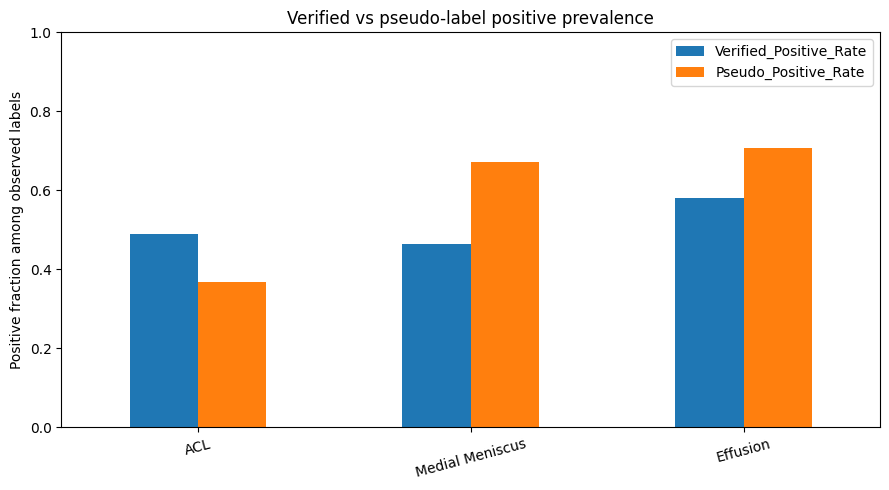

,ACL,Medial Meniscus,Effusion
ACL,0.368,0.224,0.249
Medial Meniscus,0.224,0.671,0.512
Effusion,0.249,0.512,0.708



Recorded extraction errors: 4


,Label,True,Predicted,Evidence
0,ACL,0.0,1.0,"[positive] in the intercondylar notch, there i..."
1,Effusion,0.0,1.0,[positive] leve derrame articular con discreta...
2,Effusion,0.0,1.0,[positive] leve derrame articular | [positive]...
3,Effusion,0.0,1.0,[positive] leve derrame articular con minima s...


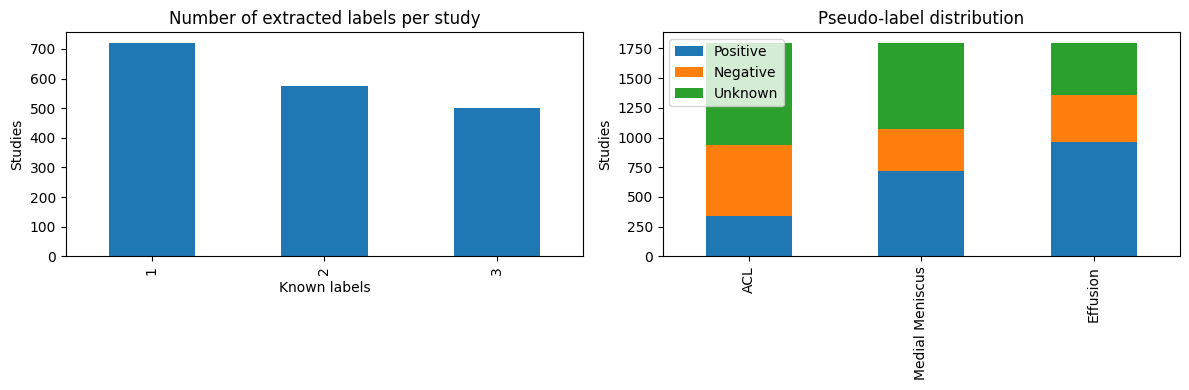


PHASE 6A COMPLETED
Outputs: /kaggle/working/knee_phase4/phase6_quality
Manual review rows: 90


In [12]:

# ============================================================
# PHASE 6A — PSEUDO-LABEL QUALITY AUDIT
#
# Reuses:
#   pseudo, verified_train, verified_val, LABELS
#   ROOT, OUT, SEED
#
# No MRI training in this phase.
# ============================================================

# 1. Load the complete candidate set from Phase 3.
# We deliberately do not use the Phase 4 random sample of 500.

P6_OUT = Path(OUT) / "phase6_quality"
P6_OUT.mkdir(parents=True, exist_ok=True)

candidate_path = Path(
    "/kaggle/working/knee_report_nlp/"
    "candidate_pseudo_labels.csv"
)

if not candidate_path.exists():
    raise FileNotFoundError(
        "Phase 3 candidate CSV not found. "
        "Run Phase 3 or attach its outputs."
    )

p6 = pd.read_csv(candidate_path)

for label in LABELS:
    p6[label] = pd.to_numeric(
        p6[label], errors="coerce"
    )

# 2. Prevent verified studies from appearing in pseudo data.

verified_ids = set(
    pd.concat([
        verified_train["StudyInstanceUID"],
        verified_val["StudyInstanceUID"]
    ])
)

p6 = p6[
    ~p6["StudyInstanceUID"].isin(verified_ids)
].copy()

assert p6["StudyInstanceUID"].is_unique

print("Candidate pseudo-labeled studies:", len(p6))

# 3. Analyze observed-label counts.

p6["Known_Count"] = p6[LABELS].notna().sum(axis=1)

print("\nNumber of labels available per study:")
print(p6["Known_Count"].value_counts().sort_index())

# 4. Label distribution.

distribution = pd.DataFrame({
    "Positive": (p6[LABELS] == 1).sum(),
    "Negative": (p6[LABELS] == 0).sum(),
    "Unknown": p6[LABELS].isna().sum()
})

distribution["Observed"] = (
    distribution["Positive"] +
    distribution["Negative"]
)

distribution["Positive_Rate"] = (
    distribution["Positive"] /
    distribution["Observed"].replace(0, np.nan)
)

display(distribution)

distribution.to_csv(
    P6_OUT / "pseudo_label_distribution.csv"
)

# 5. Compare pseudo-label prevalence with verified labels.

verified_distribution = pd.DataFrame({
    "Verified_Positive_Rate": [
        (verified_train[label] == 1).mean()
        for label in LABELS
    ],
    "Pseudo_Positive_Rate": [
        (p6[label] == 1).sum() /
        max(p6[label].notna().sum(), 1)
        for label in LABELS
    ]
}, index=LABELS)

display(verified_distribution)

verified_distribution.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Verified vs pseudo-label positive prevalence")
plt.ylabel("Positive fraction among observed labels")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    P6_OUT / "prevalence_comparison.png",
    dpi=300
)
plt.show()

# 6. Analyze label co-occurrence.
# Only studies with both labels observed contribute to a pair.

cooccurrence = pd.DataFrame(
    index=LABELS,
    columns=LABELS,
    dtype=float
)

pair_counts = cooccurrence.copy()

for a in LABELS:
    for b in LABELS:
        observed = p6[a].notna() & p6[b].notna()

        pair_counts.loc[a, b] = observed.sum()

        if observed.sum() > 0:
            cooccurrence.loc[a, b] = (
                ((p6[a] == 1) & (p6[b] == 1) & observed)
                .sum() / observed.sum()
            )
        else:
            cooccurrence.loc[a, b] = np.nan

display(cooccurrence.round(3))

cooccurrence.to_csv(
    P6_OUT / "positive_cooccurrence.csv"
)

pair_counts.to_csv(
    P6_OUT / "cooccurrence_pair_counts.csv"
)

# 7. Inspect the existing NLP error audit.

error_path = Path(
    "/kaggle/working/knee_report_nlp/nlp_errors.csv"
)

if error_path.exists():
    errors = pd.read_csv(error_path)

    print("\nRecorded extraction errors:", len(errors))

    if len(errors):
        display(
            errors[
                ["Label", "True", "Predicted", "Evidence"]
            ].head(20)
        )
else:
    print("NLP error file unavailable.")

# 8. Create a balanced manual-review sample.
#
# This is NOT an automatically verified dataset.
# Reviewers should inspect the report and extracted evidence.

review_frames = []

for label in LABELS:
    for value, status in [(1, "Positive"), (0, "Negative")]:

        subset = p6[p6[label] == value]

        if len(subset) == 0:
            continue

        sample = subset.sample(
            n=min(15, len(subset)),
            random_state=SEED
        ).copy()

        sample["Review_Label"] = label
        sample["Extracted_Status"] = status
        sample["Extracted_Value"] = value

        evidence_col = f"Evidence_{label}"

        sample["Extracted_Evidence"] = (
            sample[evidence_col]
            if evidence_col in sample
            else ""
        )

        sample["Reviewer_Label"] = np.nan
        sample["Reviewer_Notes"] = ""

        review_frames.append(sample[
            [
                "StudyInstanceUID",
                "Review_Label",
                "Extracted_Status",
                "Extracted_Value",
                "Extracted_Evidence",
                "Report",
                "Reviewer_Label",
                "Reviewer_Notes"
            ]
        ])

review = pd.concat(
    review_frames, ignore_index=True
)

review.to_csv(
    P6_OUT / "manual_review_sample.csv",
    index=False
)

# 9. Figures for the IEEE report.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

p6["Known_Count"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Number of extracted labels per study")
axes[0].set_xlabel("Known labels")
axes[0].set_ylabel("Studies")

distribution[
    ["Positive", "Negative", "Unknown"]
].plot(
    kind="bar",
    stacked=True,
    ax=axes[1]
)

axes[1].set_title("Pseudo-label distribution")
axes[1].set_ylabel("Studies")

plt.tight_layout()

plt.savefig(
    P6_OUT / "pseudo_label_quality_overview.png",
    dpi=300
)

plt.show()

print("\nPHASE 6A COMPLETED")
print("Outputs:", P6_OUT)
print("Manual review rows:", len(review))

In [13]:

# ============================================================
# PHASE 6B — EXTRACTION ERROR INVESTIGATION
#
# Purpose:
#   Inspect all incorrect NLP predictions.
#   Identify potentially ambiguous terminology.
#   Prepare a manual review file.
#
# No GPU training required.
# ============================================================

P6B_OUT = P6_OUT / "error_investigation"
P6B_OUT.mkdir(parents=True, exist_ok=True)

error_path = Path(
    "/kaggle/working/knee_report_nlp/nlp_errors.csv"
)

errors = pd.read_csv(error_path)

print("=" * 75)
print("NLP EXTRACTION ERROR INVESTIGATION")
print("=" * 75)

print("Total recorded errors:", len(errors))

# ------------------------------------------------------------
# 1. Display full evidence and report text
# ------------------------------------------------------------

for i, row in errors.iterrows():

    print("\n" + "=" * 75)
    print("ERROR", i + 1)
    print("=" * 75)

    print("Finding:", row["Label"])
    print("Verified label:", row["True"])
    print("Extracted label:", row["Predicted"])

    print("\nExtracted evidence:")
    print(row["Evidence"])

    print("\nFull radiology report:")
    print(row["Report"])

# ------------------------------------------------------------
# 2. Flag potentially ambiguous terminology
# ------------------------------------------------------------

ambiguity_terms = [
    "minimal", "trace", "mild", "small",
    "leve", "discreto", "escaso",
    "possible", "suspected", "questionable",
    "probable", "minimal effusion"
]

def find_ambiguity_terms(text):
    text = str(text).lower()

    return ", ".join(
        term for term in ambiguity_terms
        if term in text
    )

errors["Ambiguity_Terms"] = (
    errors["Evidence"].apply(find_ambiguity_terms)
)

# ------------------------------------------------------------
# 3. Prepare manual error classification
# ------------------------------------------------------------

errors["Error_Category"] = ""
errors["Reviewer_Explanation"] = ""
errors["Recommended_Action"] = ""

errors.to_csv(
    P6B_OUT / "error_review_template.csv",
    index=False
)

print("\nManual review template created.")

display(errors[
    [
        "Label",
        "True",
        "Predicted",
        "Ambiguity_Terms",
        "Error_Category"
    ]
])

print("\nSaved to:", P6B_OUT)


NLP EXTRACTION ERROR INVESTIGATION
Total recorded errors: 4

ERROR 1
Finding: ACL
Verified label: 0.0
Extracted label: 1.0

Extracted evidence:
[positive] in the intercondylar notch, there is interstitial tear of the anterior cruciate ligament, at mid substance | [positive] interstitial tear of the anterior cruciate ligament, at mid substance

Full radiology report:
 In the medial compartment, the meniscus is not torn and there is no focal chondrosis or chondral injury. 
  
 The lateral compartment, there is complex tear (main radial and longitudinal vertical component) at the posterior horn of the lateral meniscus. There is no focal chondrosis or chondral injury. 
  
 The patellofemoral joint, the patellar and trochlear cartilage appears congruent without chondral lesion. The medial patellofemoral ligament is intact.  
 In the intercondylar notch, there is interstitial tear of the anterior cruciate ligament, at mid substance. The posterior cruciate ligament is intact. There is no tibi

,Label,True,Predicted,Ambiguity_Terms,Error_Category
0,ACL,0.0,1.0,,
1,Effusion,0.0,1.0,leve,
2,Effusion,0.0,1.0,leve,
3,Effusion,0.0,1.0,leve,



Saved to: /kaggle/working/knee_phase4/phase6_quality/error_investigation


Flagged ACL positives: 7
Flagged effusion positives: 554

LABEL FILTERING COMPARISON


/tmp/ipykernel_49/3836423480.py:63: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  effusion_evidence.str.contains(


,Original_Observed,Filtered_Observed,Original_Positive,Filtered_Positive,Original_Negative,Filtered_Negative,Removed_Labels
ACL,936,929,344,337,592,592,7
Medial Meniscus,1075,1075,721,721,354,354,0
Effusion,1361,807,963,409,398,398,554



Original candidate studies: 1796
Filtered candidate studies: 1609


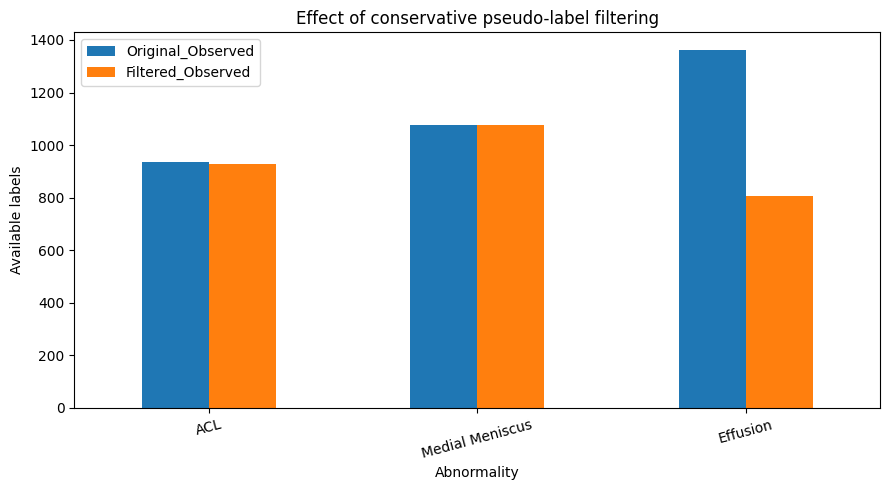


PHASE 6C COMPLETED
Saved to: /kaggle/working/knee_phase4/phase6_quality/filtered_labels


In [14]:

# ============================================================
# PHASE 6C — CONSERVATIVE PSEUDO-LABEL FILTERING
#
# Purpose:
#   1. Preserve original pseudo-labels.
#   2. Abstain on selected ambiguous positive findings.
#   3. Compare original and filtered label coverage.
#   4. Export filtered labels for controlled experiments.
#
# IMPORTANT:
#   This is a hypothesis-driven filtering experiment.
#   It does not establish that mild effusion or interstitial
#   ACL injury should be clinically classified as negative.
# ============================================================

P6C_OUT = P6_OUT / "filtered_labels"
P6C_OUT.mkdir(parents=True, exist_ok=True)

# Reuse the full candidate dataframe from Phase 6A.
filtered = p6.copy()

# ------------------------------------------------------------
# 1. Define conservative exclusion patterns
# ------------------------------------------------------------

# Ambiguous or potentially mismatched ACL-positive descriptions.
acl_ambiguous = (
    r"interstitial tear|intrasubstance tear|"
    r"interstitial injury|intrasubstance injury"
)

# Mild or minimal effusion descriptions in several languages.
effusion_ambiguous = (
    r"\b(mild|minimal|trace|tiny|small|leve|"
    r"ligero|ligera|escaso|escasa|discreto|discreta|"
    r"leger|legere|faible)\b"
    r".{0,35}"
    r"(joint effusion|knee effusion|effusion|"
    r"derrame|epanchement)"
)

# ------------------------------------------------------------
# 2. Identify affected positive pseudo-labels
# ------------------------------------------------------------

acl_evidence = filtered[
    "Evidence_ACL"
].fillna("").astype(str).str.lower()

effusion_evidence = filtered[
    "Evidence_Effusion"
].fillna("").astype(str).str.lower()

acl_flag = (
    filtered["ACL"].eq(1) &
    acl_evidence.str.contains(
        acl_ambiguous, regex=True
    )
)

effusion_flag = (
    filtered["Effusion"].eq(1) &
    effusion_evidence.str.contains(
        effusion_ambiguous, regex=True
    )
)

print("Flagged ACL positives:", int(acl_flag.sum()))
print("Flagged effusion positives:", int(effusion_flag.sum()))

# ------------------------------------------------------------
# 3. Change flagged labels to UNKNOWN
# ------------------------------------------------------------

filtered.loc[acl_flag, "ACL"] = np.nan
filtered.loc[effusion_flag, "Effusion"] = np.nan

# Do not modify medial meniscus labels in this experiment.
# They require a separate terminology audit.

filtered["Known_Count"] = (
    filtered[LABELS].notna().sum(axis=1)
)

# Remove studies with no remaining known labels.
filtered = filtered[
    filtered["Known_Count"] >= 1
].copy()

# ------------------------------------------------------------
# 4. Compare label availability
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Original_Observed": p6[LABELS].notna().sum(),
    "Filtered_Observed": filtered[LABELS].notna().sum(),
    "Original_Positive": (p6[LABELS] == 1).sum(),
    "Filtered_Positive": (filtered[LABELS] == 1).sum(),
    "Original_Negative": (p6[LABELS] == 0).sum(),
    "Filtered_Negative": (filtered[LABELS] == 0).sum()
})

comparison["Removed_Labels"] = (
    comparison["Original_Observed"] -
    comparison["Filtered_Observed"]
)

print("\nLABEL FILTERING COMPARISON")
display(comparison)

print("\nOriginal candidate studies:", len(p6))
print("Filtered candidate studies:", len(filtered))

# ------------------------------------------------------------
# 5. Export filtered training candidates
# ------------------------------------------------------------

filtered.to_csv(
    P6C_OUT / "filtered_pseudo_labels.csv",
    index=False
)

comparison.to_csv(
    P6C_OUT / "filtering_comparison.csv"
)

# Preserve flagged cases for manual inspection.
flagged = p6.loc[
    acl_flag | effusion_flag
].copy()

flagged["Flag_ACL"] = acl_flag.loc[flagged.index]
flagged["Flag_Effusion"] = effusion_flag.loc[flagged.index]

flagged.to_csv(
    P6C_OUT / "flagged_cases_for_review.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Plot original versus filtered label availability
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

comparison[
    ["Original_Observed", "Filtered_Observed"]
].plot(kind="bar", ax=ax)

ax.set_title("Effect of conservative pseudo-label filtering")
ax.set_ylabel("Available labels")
ax.set_xlabel("Abnormality")

plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    P6C_OUT / "filtering_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nPHASE 6C COMPLETED")
print("Saved to:", P6C_OUT)



 E6_verified
Studies: 43


,Positive,Negative,Unknown
ACL,21,22,0
Medial Meniscus,20,23,0
Effusion,25,18,0



 E7_original
Studies: 543


,Positive,Negative,Unknown
ACL,124,199,220
Medial Meniscus,264,123,156
Effusion,259,142,142



 E8_filtered
Studies: 543


,Positive,Negative,Unknown
ACL,123,199,221
Medial Meniscus,264,123,156
Effusion,145,142,256



TRAINING: E6_verified
E6_verified | Epoch 1 | Train 0.7308 | Val 0.7863 | AUC 0.4963
E6_verified | Epoch 2 | Train 0.6544 | Val 0.6389 | AUC 0.7723
E6_verified | Epoch 3 | Train 0.6320 | Val 0.9638 | AUC 0.7010
E6_verified | Epoch 4 | Train 0.5705 | Val 0.5301 | AUC 0.7810
E6_verified | Epoch 5 | Train 0.5324 | Val 1.8473 | AUC 0.7738
E6_verified | Epoch 6 | Train 0.5095 | Val 0.7170 | AUC 0.7244
E6_verified | Epoch 7 | Train 0.3970 | Val 1.6840 | AUC 0.6140
E6_verified | Epoch 8 | Train 0.3943 | Val 1.1373 | AUC 0.6469

TRAINING: E7_original
E7_original | Epoch 1 | Train 0.6734 | Val 0.8609 | AUC 0.4546
E7_original | Epoch 2 | Train 0.6402 | Val 1.0014 | AUC 0.5532
E7_original | Epoch 3 | Train 0.6100 | Val 1.8092 | AUC 0.5477
E7_original | Epoch 4 | Train 0.6048 | Val 0.8923 | AUC 0.6360
E7_original | Epoch 5 | Train 0.5767 | Val 0.7246 | AUC 0.7065
E7_original | Epoch 6 | Train 0.5490 | Val 0.7721 | AUC 0.6937
E7_original | Epoch 7 | Train 0.5526 | Val 0.7227 | AUC 0.6798
E7_origin

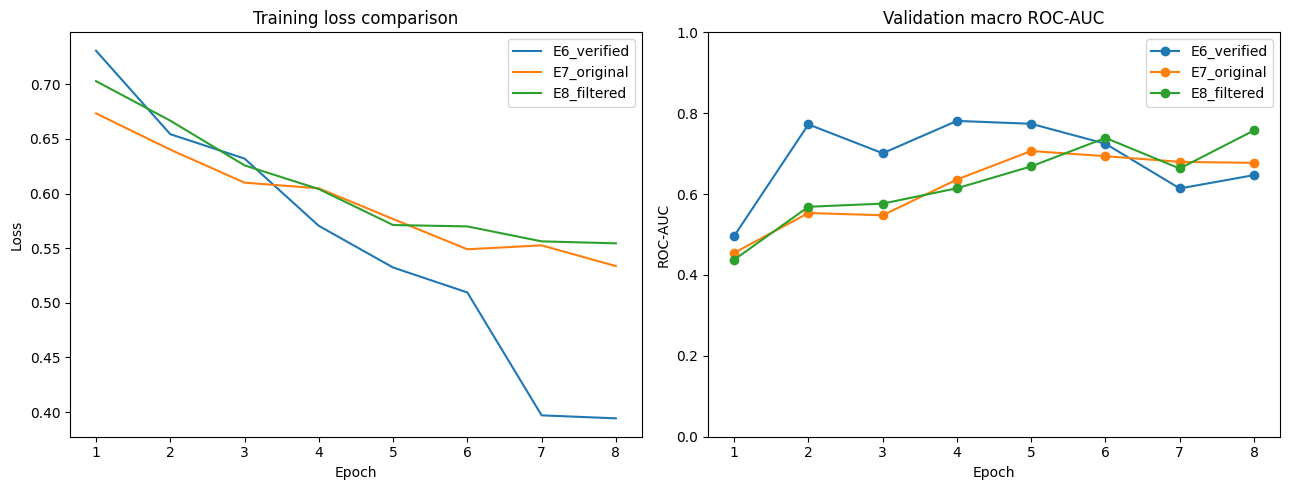


PHASE 6D RESULTS


,Experiment,Training_Studies,Best_Validation_AUC
0,E6_verified,43,0.780988
1,E7_original,543,0.706543
2,E8_filtered,543,0.757407



Saved to: /kaggle/working/knee_phase4/phase6_filtered_comparison


In [17]:

# ============================================================
# PHASE 6D — ORIGINAL VS FILTERED PSEUDO-LABELS
#
# E6: Verified labels only
# E7: Verified + original pseudo-labels
# E8: Verified + filtered pseudo-labels
#
# Uses the existing Kaggle GPU and Phase 4 components.
#
# IMPORTANT:
# - These are exploratory validation experiments.
# - Same study IDs are used for E7 and E8.
# - Unknown labels are ignored using masked BCE.
# - Reports are NOT inputs to the MRI model.
# ============================================================

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

P6D_OUT = Path(OUT) / "phase6_filtered_comparison"
P6D_OUT.mkdir(parents=True, exist_ok=True)

P6D_EPOCHS = 8
P6D_BATCH_SIZE = 2
P6D_LR = 1e-4
P6D_MAX_PSEUDO = 500

# ------------------------------------------------------------
# 2. LOAD ORIGINAL AND FILTERED LABELS
# ------------------------------------------------------------

original = pd.read_csv(
    "/kaggle/working/knee_report_nlp/"
    "candidate_pseudo_labels.csv"
)

filtered_data = pd.read_csv(
    P6C_OUT / "filtered_pseudo_labels.csv"
)

for frame in [original, filtered_data]:
    for label in LABELS:
        frame[label] = pd.to_numeric(
            frame[label], errors="coerce"
        )

# ------------------------------------------------------------
# 3. SELECT COMMON STUDY IDS
# ------------------------------------------------------------

common_ids = sorted(
    set(original["StudyInstanceUID"]) &
    set(filtered_data["StudyInstanceUID"])
)

rng = np.random.default_rng(SEED)

selected_ids = rng.choice(
    common_ids,
    size=min(P6D_MAX_PSEUDO, len(common_ids)),
    replace=False
)

original = original[
    original["StudyInstanceUID"].isin(selected_ids)
].copy()

filtered_data = filtered_data[
    filtered_data["StudyInstanceUID"].isin(selected_ids)
].copy()

# ------------------------------------------------------------
# 4. ATTACH THE SAME MRI SERIES
# ------------------------------------------------------------

original = attach_series(original)
filtered_data = attach_series(filtered_data)

# Ensure both groups contain identical study IDs.
common_after_merge = (
    set(original["StudyInstanceUID"]) &
    set(filtered_data["StudyInstanceUID"])
)

original = original[
    original["StudyInstanceUID"].isin(common_after_merge)
].copy()

filtered_data = filtered_data[
    filtered_data["StudyInstanceUID"].isin(common_after_merge)
].copy()

# Consistent ordering.
original = original.sort_values(
    "StudyInstanceUID"
).reset_index(drop=True)

filtered_data = filtered_data.sort_values(
    "StudyInstanceUID"
).reset_index(drop=True)

assert original["StudyInstanceUID"].tolist() == (
    filtered_data["StudyInstanceUID"].tolist()
)

# ------------------------------------------------------------
# 5. BUILD EXPERIMENT DATASETS
# ------------------------------------------------------------

datasets = {
    "E6_verified": verified_train.copy(),

    "E7_original": pd.concat(
        [verified_train, original],
        ignore_index=True
    ),

    "E8_filtered": pd.concat(
        [verified_train, filtered_data],
        ignore_index=True
    )
}

# ------------------------------------------------------------
# 6. DISPLAY TRAINING LABEL DISTRIBUTIONS
# ------------------------------------------------------------

for name, frame in datasets.items():

    print("\n", name)
    print("Studies:", len(frame))

    display(pd.DataFrame({
        "Positive": (frame[LABELS] == 1).sum(),
        "Negative": (frame[LABELS] == 0).sum(),
        "Unknown": frame[LABELS].isna().sum()
    }))

# ------------------------------------------------------------
# 7. TRAINING AND EVALUATION
# ------------------------------------------------------------

def p6d_train(name, frame):

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    model = KneeResNet().to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=P6D_LR,
        weight_decay=1e-4
    )

    train_loader = DataLoader(
        KneeDataset(frame),
        batch_size=P6D_BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        KneeDataset(verified_val),
        batch_size=P6D_BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    history = []
    best_auc = -np.inf
    best_state = None

    for epoch in range(1, P6D_EPOCHS + 1):

        model.train()
        train_losses = []

        for images, targets, mask in train_loader:

            images = images.to(
                DEVICE, dtype=torch.float32
            )

            targets = targets.to(
                DEVICE, dtype=torch.float32
            )

            mask = mask.to(
                DEVICE, dtype=torch.float32
            )

            optimizer.zero_grad(set_to_none=True)

            logits = model(images)

            loss = masked_loss(
                logits, targets, mask
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()

            train_losses.append(loss.item())

        val_loss, auc, per_label, _, _ = evaluate(
            model, val_loader
        )

        history.append({
            "Experiment": name,
            "Epoch": epoch,
            "Train_Loss": np.mean(train_losses),
            "Val_Loss": val_loss,
            "Macro_AUC": auc,
            **per_label
        })

        print(
            f"{name} | Epoch {epoch} | "
            f"Train {np.mean(train_losses):.4f} | "
            f"Val {val_loss:.4f} | "
            f"AUC {auc:.4f}"
        )

        if np.isfinite(auc) and auc > best_auc:
            best_auc = auc
            best_state = copy.deepcopy(
                model.state_dict()
            )

    if best_state is None:
        raise RuntimeError(
            "No valid validation AUC was produced."
        )

    torch.save(
        best_state,
        P6D_OUT / f"{name}_best.pt"
    )

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return pd.DataFrame(history), best_auc

# ------------------------------------------------------------
# 8. RUN EXPERIMENTS
# ------------------------------------------------------------

histories = []
summaries = []

for name, frame in datasets.items():

    print("\n" + "=" * 65)
    print("TRAINING:", name)
    print("=" * 65)

    history, auc = p6d_train(name, frame)

    histories.append(history)

    summaries.append({
        "Experiment": name,
        "Training_Studies": len(frame),
        "Best_Validation_AUC": auc
    })

all_history = pd.concat(
    histories, ignore_index=True
)

results = pd.DataFrame(summaries)

all_history.to_csv(
    P6D_OUT / "training_history.csv",
    index=False
)

results.to_csv(
    P6D_OUT / "experiment_results.csv",
    index=False
)

# ------------------------------------------------------------
# 9. VISUALIZE RESULTS
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in all_history.groupby("Experiment"):

    axes[0].plot(
        group["Epoch"],
        group["Train_Loss"],
        label=name
    )

    axes[1].plot(
        group["Epoch"],
        group["Macro_AUC"],
        marker="o",
        label=name
    )

axes[0].set_title("Training loss comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("Validation macro ROC-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()

plt.savefig(
    P6D_OUT / "training_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nPHASE 6D RESULTS")
display(results)

print("\nSaved to:", P6D_OUT)


GPU: Tesla T4
CUDA: 12.8
Unique studies to cache: 558
Cached 100/558 studies
Cached 200/558 studies
Cached 300/558 studies
Cached 400/558 studies
Cached 500/558 studies
Cache completed.
Successful: 558
Failed: 0
Time: 56.02 seconds
Cache RAM: 0.417 GiB

EXPERIMENT: E6_verified
E6_verified | Epoch 1/8 | Train 0.7074 | Val 0.6333 | AUC 0.6552
E6_verified | Epoch 2/8 | Train 0.6062 | Val 0.7632 | AUC 0.6336
E6_verified | Epoch 3/8 | Train 0.5132 | Val 1.1129 | AUC 0.5431
E6_verified | Epoch 4/8 | Train 0.3981 | Val 1.8263 | AUC 0.4804
E6_verified | Epoch 5/8 | Train 0.3332 | Val 1.9977 | AUC 0.5133
E6_verified | Epoch 6/8 | Train 0.2468 | Val 1.5840 | AUC 0.5432
E6_verified | Epoch 7/8 | Train 0.1500 | Val 1.2225 | AUC 0.6637
E6_verified | Epoch 8/8 | Train 0.1178 | Val 1.0694 | AUC 0.7410

EXPERIMENT: E7_original
E7_original | Epoch 1/8 | Train 0.6399 | Val 1.6833 | AUC 0.6315
E7_original | Epoch 2/8 | Train 0.5474 | Val 0.7906 | AUC 0.7559
E7_original | Epoch 3/8 | Train 0.4910 | Val 0.

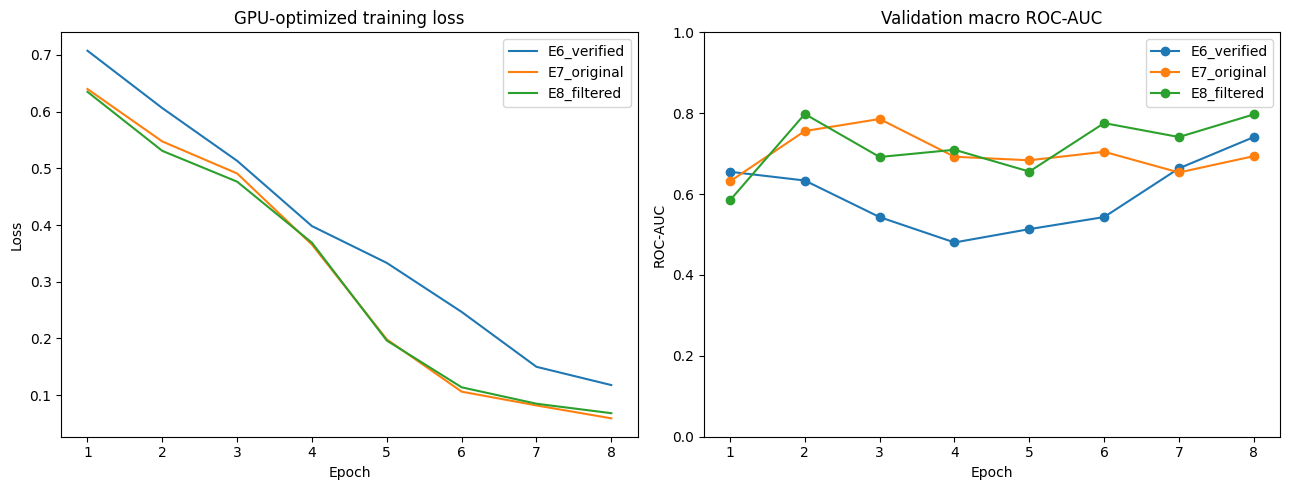


GPU-OPTIMIZED EXPERIMENT RESULTS


,Experiment,Best_Epoch,Best_AUC,Seconds
0,E6_verified,8,0.740988,25.105958
1,E7_original,3,0.785679,59.363951
2,E8_filtered,2,0.798025,54.388693



Outputs saved to: /kaggle/working/knee_phase4/phase6_gpu_optimized


In [18]:

# ============================================================
# PHASE 6E — GPU-OPTIMIZED MRI TRAINING
#
# Improvements:
# 1. Decode DICOM studies only once
# 2. Cache MRI tensors in RAM (float16)
# 3. Use parallel DataLoader workers
# 4. Use CUDA mixed precision
# 5. Use larger batches
# 6. Avoid repeatedly loading MRI metadata
# 7. Save best models and experimental results
#
# Experiments:
# E6: Verified labels
# E7: Verified + original pseudo-labels
# E8: Verified + filtered pseudo-labels
#
# Existing variables required:
# datasets, verified_val, LABELS, DEVICE, SEED,
# read_study, OUT
# ============================================================

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

FAST_EPOCHS = 8
FAST_BATCH = 8
FAST_LR = 1e-4
FAST_WORKERS = 2

FAST_OUT = Path(OUT) / "phase6_gpu_optimized"
FAST_OUT.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "Enable GPU in Kaggle."

print("GPU:", torch.cuda.get_device_name(0))
print("CUDA:", torch.version.cuda)

torch.backends.cudnn.benchmark = True

# ------------------------------------------------------------
# 2. CACHE ALL UNIQUE MRI STUDIES
# ------------------------------------------------------------
#
# Each MRI is decoded and resized once.
# float16 storage reduces RAM requirements.
#
# The cache is stored in CPU RAM.
# DataLoader transfers batches to GPU.
# ------------------------------------------------------------

all_frames = list(datasets.values()) + [verified_val]

all_studies = pd.concat(
    all_frames, ignore_index=True
).drop_duplicates("StudyInstanceUID")

print("Unique studies to cache:", len(all_studies))

MRI_CACHE = {}
failed = []

start_cache = time.time()

for index, (_, row) in enumerate(all_studies.iterrows()):

    uid = str(row["StudyInstanceUID"])

    try:
        # Existing Phase 4 preprocessing function.
        image = read_study(row)

        # Ensure [S, 1, H, W].
        image = image.to(dtype=torch.float16)

        MRI_CACHE[uid] = image.cpu()

    except Exception as error:
        failed.append((uid, str(error)))

    if (index + 1) % 100 == 0:
        print(
            f"Cached {index+1}/{len(all_studies)} studies"
        )

print("Cache completed.")
print("Successful:", len(MRI_CACHE))
print("Failed:", len(failed))
print("Time:", round(time.time()-start_cache, 2), "seconds")

cache_bytes = sum(
    x.numel() * x.element_size()
    for x in MRI_CACHE.values()
)

print("Cache RAM:", round(cache_bytes / 1024**3, 3), "GiB")

# ------------------------------------------------------------
# 3. CACHED DATASET
# ------------------------------------------------------------

class CachedKneeDataset(Dataset):

    def __init__(self, frame):
        self.frame = frame[
            frame["StudyInstanceUID"].astype(str).isin(MRI_CACHE)
        ].reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):

        row = self.frame.iloc[index]
        uid = str(row["StudyInstanceUID"])

        image = MRI_CACHE[uid]

        values = row[LABELS].to_numpy(dtype=np.float32)

        mask = np.isfinite(values).astype(np.float32)
        target = np.nan_to_num(values, nan=0.0)

        return (
            image,
            torch.from_numpy(target),
            torch.from_numpy(mask)
        )

# ------------------------------------------------------------
# 4. BUILD DATA LOADERS
# ------------------------------------------------------------

def make_fast_loader(frame, shuffle):

    return DataLoader(
        CachedKneeDataset(frame),
        batch_size=FAST_BATCH,
        shuffle=shuffle,
        num_workers=FAST_WORKERS,
        pin_memory=True,
        persistent_workers=(FAST_WORKERS > 0)
    )

fast_val_loader = make_fast_loader(
    verified_val, shuffle=False
)

# ------------------------------------------------------------
# 5. MODEL
# ------------------------------------------------------------
#
# Keep the same randomly initialized grayscale
# ResNet18 architecture as Phase 6D.
#
# No pretrained weights are used in this experiment.
# ------------------------------------------------------------

class FastKneeNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = resnet18(weights=None)

        self.encoder.conv1 = nn.Conv2d(
            1, 64,
            kernel_size=7,
            stride=2,
            padding=3,
            bias=False
        )

        feature_dim = self.encoder.fc.in_features
        self.encoder.fc = nn.Identity()

        self.head = nn.Linear(
            feature_dim, len(LABELS)
        )

    def forward(self, images):

        b, s, c, h, w = images.shape

        images = images.reshape(
            b * s, c, h, w
        )

        features = self.encoder(images)

        features = features.reshape(
            b, s, -1
        ).mean(dim=1)

        return self.head(features)

# ------------------------------------------------------------
# 6. MASKED LOSS
# ------------------------------------------------------------

def fast_masked_loss(logits, targets, mask):

    # Compute loss in float32 for numerical stability.
    loss = torch.nn.functional.binary_cross_entropy_with_logits(
        logits.float(),
        targets.float(),
        reduction="none"
    )

    return (
        (loss * mask).sum()
        / mask.sum().clamp(min=1)
    )

# ------------------------------------------------------------
# 7. GPU EVALUATION
# ------------------------------------------------------------

@torch.no_grad()
def fast_evaluate(model, loader):

    model.eval()

    truths = []
    predictions = []
    masks = []

    total_loss = 0.0
    total_observed = 0.0

    for images, targets, mask in loader:

        images = images.to(
            DEVICE, dtype=torch.float32,
            non_blocking=True
        )

        targets = targets.to(
            DEVICE, non_blocking=True
        )

        mask = mask.to(
            DEVICE, non_blocking=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = model(images)

        loss = fast_masked_loss(
            logits, targets, mask
        )

        observed = mask.sum().item()
        total_loss += loss.item() * observed
        total_observed += observed

        truths.append(targets.cpu().numpy())
        predictions.append(
            torch.sigmoid(logits.float()).cpu().numpy()
        )
        masks.append(mask.cpu().numpy())

    y = np.concatenate(truths)
    p = np.concatenate(predictions)
    m = np.concatenate(masks)

    aucs = {}

    for j, label in enumerate(LABELS):

        valid = m[:, j] == 1

        if len(np.unique(y[valid, j])) == 2:
            aucs[label] = roc_auc_score(
                y[valid, j], p[valid, j]
            )
        else:
            aucs[label] = np.nan

    values = list(aucs.values())

    macro_auc = (
        float(np.mean(values))
        if all(np.isfinite(v) for v in values)
        else np.nan
    )

    return (
        total_loss / max(total_observed, 1),
        macro_auc,
        aucs
    )

# ------------------------------------------------------------
# 8. OPTIMIZED TRAINING
# ------------------------------------------------------------

def train_fast(name, frame):

    print("\n" + "=" * 65)
    print("EXPERIMENT:", name)
    print("=" * 65)

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    loader = make_fast_loader(frame, shuffle=True)

    model = FastKneeNet().to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=FAST_LR,
        weight_decay=1e-4
    )

    scaler = torch.amp.GradScaler("cuda")

    history = []
    best_auc = -np.inf
    best_epoch = None

    start = time.time()

    for epoch in range(1, FAST_EPOCHS + 1):

        model.train()

        running_loss = 0.0
        observed_total = 0.0

        for images, targets, mask in loader:

            images = images.to(
                DEVICE, dtype=torch.float32,
                non_blocking=True
            )

            targets = targets.to(
                DEVICE, non_blocking=True
            )

            mask = mask.to(
                DEVICE, non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(images)

            loss = fast_masked_loss(
                logits, targets, mask
            )

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            scaler.step(optimizer)
            scaler.update()

            observed = mask.sum().item()

            running_loss += loss.item() * observed
            observed_total += observed

        train_loss = running_loss / max(observed_total, 1)

        val_loss, auc, per_label = fast_evaluate(
            model, fast_val_loader
        )

        history.append({
            "Experiment": name,
            "Epoch": epoch,
            "Train_Loss": train_loss,
            "Val_Loss": val_loss,
            "Macro_AUC": auc,
            **per_label
        })

        print(
            f"{name} | "
            f"Epoch {epoch}/{FAST_EPOCHS} | "
            f"Train {train_loss:.4f} | "
            f"Val {val_loss:.4f} | "
            f"AUC {auc:.4f}"
        )

        if np.isfinite(auc) and auc > best_auc:

            best_auc = auc
            best_epoch = epoch

            torch.save(
                {
                    "model": model.state_dict(),
                    "labels": LABELS,
                    "epoch": epoch,
                    "best_auc": auc
                },
                FAST_OUT / f"{name}_best.pt"
            )

    elapsed = time.time() - start

    del model, loader
    gc.collect()
    torch.cuda.empty_cache()

    return pd.DataFrame(history), {
        "Experiment": name,
        "Best_Epoch": best_epoch,
        "Best_AUC": best_auc,
        "Seconds": elapsed
    }

# ------------------------------------------------------------
# 9. RUN EXPERIMENTS
# ------------------------------------------------------------

fast_histories = []
fast_summaries = []

for name, frame in datasets.items():

    history, summary = train_fast(name, frame)

    fast_histories.append(history)
    fast_summaries.append(summary)

fast_history = pd.concat(
    fast_histories, ignore_index=True
)

fast_results = pd.DataFrame(fast_summaries)

fast_history.to_csv(
    FAST_OUT / "training_history.csv",
    index=False
)

fast_results.to_csv(
    FAST_OUT / "experiment_results.csv",
    index=False
)

# ------------------------------------------------------------
# 10. GENERATE COMPARISON FIGURES
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, group in fast_history.groupby("Experiment"):

    axes[0].plot(
        group["Epoch"],
        group["Train_Loss"],
        label=name
    )

    axes[1].plot(
        group["Epoch"],
        group["Macro_AUC"],
        marker="o",
        label=name
    )

axes[0].set_title("GPU-optimized training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("Validation macro ROC-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()

plt.savefig(
    FAST_OUT / "gpu_optimized_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nGPU-OPTIMIZED EXPERIMENT RESULTS")
display(fast_results)

print("\nOutputs saved to:", FAST_OUT)


Verified studies: 58
Common pseudo-labeled studies: 500
New studies cached: 0
Cache failures: 0

FOLD: 1 | MODEL: Verified
Verified | Fold 1 | Epoch 1/6 | AUC 0.6013
Verified | Fold 1 | Epoch 2/6 | AUC 0.6571
Verified | Fold 1 | Epoch 3/6 | AUC 0.6135
Verified | Fold 1 | Epoch 4/6 | AUC 0.5855
Verified | Fold 1 | Epoch 5/6 | AUC 0.6408
Verified | Fold 1 | Epoch 6/6 | AUC 0.6232

FOLD: 1 | MODEL: Original
Original | Fold 1 | Epoch 1/6 | AUC 0.7087
Original | Fold 1 | Epoch 2/6 | AUC 0.6966
Original | Fold 1 | Epoch 3/6 | AUC 0.6312
Original | Fold 1 | Epoch 4/6 | AUC 0.7092
Original | Fold 1 | Epoch 5/6 | AUC 0.5961
Original | Fold 1 | Epoch 6/6 | AUC 0.7130

FOLD: 1 | MODEL: Filtered
Filtered | Fold 1 | Epoch 1/6 | AUC 0.7183
Filtered | Fold 1 | Epoch 2/6 | AUC 0.6432
Filtered | Fold 1 | Epoch 3/6 | AUC 0.6276
Filtered | Fold 1 | Epoch 4/6 | AUC 0.6586
Filtered | Fold 1 | Epoch 5/6 | AUC 0.5437
Filtered | Fold 1 | Epoch 6/6 | AUC 0.6312

FOLD: 2 | MODEL: Verified
Verified | Fold 2 | Ep

,Experiment,Mean_AUC,Std_AUC,Mean_Seconds
0,Filtered,0.648972,0.049040,41.229015
1,Original,0.683910,0.031911,43.314263
2,Verified,0.616768,0.062200,6.784730


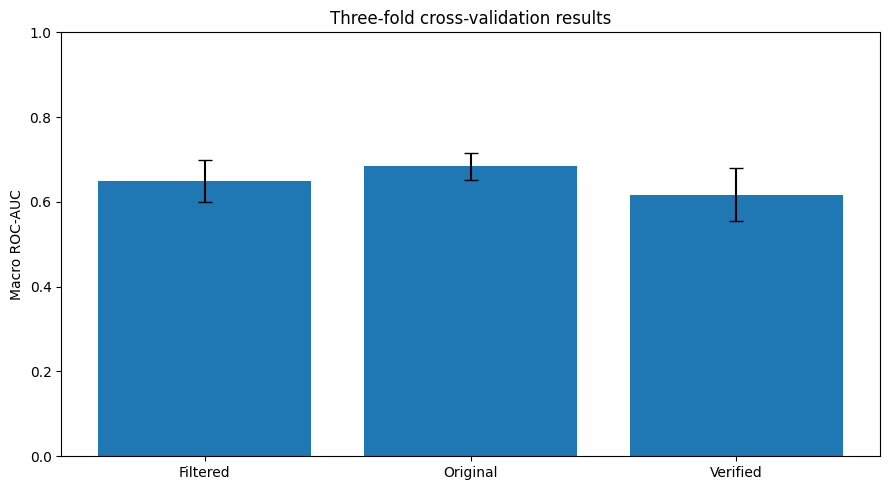


PHASE 7 COMPLETED
Results saved to: /kaggle/working/knee_phase4/phase7_cross_validation


In [19]:

# ============================================================
# PHASE 7 — STUDY-LEVEL CROSS-VALIDATION
#
# Compare:
#   CV1: Verified labels only
#   CV2: Verified + original pseudo-labels
#   CV3: Verified + filtered pseudo-labels
#
# GPU optimized:
#   - Reuses MRI_CACHE
#   - Uses FP16 mixed precision
#   - Reuses CachedKneeDataset and FastKneeNet
#
# Evaluation:
#   3-fold study-level cross-validation
#   Final-epoch ROC-AUC
#   Per-label ROC-AUC
#   Mean and standard deviation across folds
#
# No reports are passed to the MRI classifier.
# ============================================================

# ------------------------------------------------------------
# 1. SETTINGS AND STATE CHECKS
# ------------------------------------------------------------

from sklearn.model_selection import KFold

CV_FOLDS = 3
CV_EPOCHS = 6
CV_BATCH = 8
CV_LR = 1e-4

CV_OUT = Path(OUT) / "phase7_cross_validation"
CV_OUT.mkdir(parents=True, exist_ok=True)

required = [
    "FastKneeNet", "CachedKneeDataset",
    "MRI_CACHE", "read_study", "attach_series",
    "datasets", "fast_masked_loss",
    "verified", "LABELS", "SEED", "DEVICE"
]

missing = [x for x in required if x not in globals()]
if missing:
    raise RuntimeError("Run earlier cells first: " + str(missing))

assert torch.cuda.is_available(), "Enable Kaggle GPU."

# ------------------------------------------------------------
# 2. PREPARE ALL 58 VERIFIED STUDIES
# ------------------------------------------------------------

cv_verified = attach_series(
    verified[["StudyInstanceUID"] + LABELS].copy()
)

cv_verified = cv_verified.drop_duplicates(
    "StudyInstanceUID"
).reset_index(drop=True)

print("Verified studies:", len(cv_verified))

# ------------------------------------------------------------
# 3. REUSE THE SAME PSEUDO-LABELED STUDIES
# ------------------------------------------------------------

# These frames already contain the Phase 6D selection.
# Both have the same pseudo-labeled study identities.

cv_original = datasets["E7_original"].copy()
cv_filtered = datasets["E8_filtered"].copy()

verified_ids = set(cv_verified["StudyInstanceUID"])

cv_original = cv_original[
    ~cv_original["StudyInstanceUID"].isin(verified_ids)
].copy()

cv_filtered = cv_filtered[
    ~cv_filtered["StudyInstanceUID"].isin(verified_ids)
].copy()

common_ids = (
    set(cv_original["StudyInstanceUID"]) &
    set(cv_filtered["StudyInstanceUID"])
)

cv_original = cv_original[
    cv_original["StudyInstanceUID"].isin(common_ids)
].copy()

cv_filtered = cv_filtered[
    cv_filtered["StudyInstanceUID"].isin(common_ids)
].copy()

print("Common pseudo-labeled studies:", len(common_ids))

# ------------------------------------------------------------
# 4. ENSURE MRI TENSORS ARE CACHED
# ------------------------------------------------------------

all_cv = pd.concat(
    [cv_verified, cv_original, cv_filtered],
    ignore_index=True
).drop_duplicates("StudyInstanceUID")

newly_cached = 0
failed = []

for _, row in all_cv.iterrows():

    uid = str(row["StudyInstanceUID"])

    if uid in MRI_CACHE:
        continue

    try:
        MRI_CACHE[uid] = (
            read_study(row).half().cpu()
        )
        newly_cached += 1

    except Exception as error:
        failed.append((uid, str(error)))

print("New studies cached:", newly_cached)
print("Cache failures:", len(failed))

# Require all verified studies to be available.
missing_verified = [
    uid for uid in cv_verified["StudyInstanceUID"]
    if str(uid) not in MRI_CACHE
]

if missing_verified:
    raise RuntimeError(
        f"{len(missing_verified)} verified studies "
        "could not be cached."
    )

# Remove failed pseudo-labeled studies consistently.
available = set(MRI_CACHE.keys())

cv_original = cv_original[
    cv_original["StudyInstanceUID"].astype(str).isin(available)
].copy()

cv_filtered = cv_filtered[
    cv_filtered["StudyInstanceUID"].astype(str).isin(available)
].copy()

# ------------------------------------------------------------
# 5. FIXED STUDY-LEVEL FOLDS
# ------------------------------------------------------------

kf = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=SEED
)

folds = list(kf.split(cv_verified))

# Ensure each fold contains both classes for all labels.
for fold_no, (_, val_idx) in enumerate(folds, 1):

    subset = cv_verified.iloc[val_idx]

    for label in LABELS:
        if subset[label].nunique() < 2:
            raise RuntimeError(
                f"Fold {fold_no} lacks both classes for {label}. "
                "Choose another fixed seed or use a "
                "multi-label-stratified fold assignment."
            )

# Save fold membership for reproducibility.
fold_membership = []

for fold_no, (_, val_idx) in enumerate(folds, 1):
    for uid in cv_verified.iloc[val_idx]["StudyInstanceUID"]:
        fold_membership.append({
            "StudyInstanceUID": uid,
            "Fold": fold_no
        })

pd.DataFrame(fold_membership).to_csv(
    CV_OUT / "fold_assignments.csv",
    index=False
)

# ------------------------------------------------------------
# 6. DATA LOADER
# ------------------------------------------------------------

def cv_loader(frame, shuffle):

    return DataLoader(
        CachedKneeDataset(frame),
        batch_size=CV_BATCH,
        shuffle=shuffle,
        num_workers=2,
        pin_memory=True,
        persistent_workers=True
    )

# ------------------------------------------------------------
# 7. EVALUATION
# ------------------------------------------------------------

@torch.no_grad()
def cv_evaluate(model, loader):

    model.eval()

    truth_list = []
    prob_list = []

    for images, targets, mask in loader:

        images = images.to(
            DEVICE, dtype=torch.float32,
            non_blocking=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = model(images)

        prob_list.append(
            torch.sigmoid(logits.float()).cpu().numpy()
        )

        truth_list.append(targets.numpy())

    truth = np.concatenate(truth_list)
    prob = np.concatenate(prob_list)

    aucs = {}

    for j, label in enumerate(LABELS):

        if len(np.unique(truth[:, j])) == 2:
            aucs[label] = roc_auc_score(
                truth[:, j], prob[:, j]
            )
        else:
            aucs[label] = np.nan

    macro = (
        float(np.mean(list(aucs.values())))
        if all(np.isfinite(v) for v in aucs.values())
        else np.nan
    )

    return macro, aucs, truth, prob

# ------------------------------------------------------------
# 8. TRAIN ONE FOLD
# ------------------------------------------------------------

def cv_train_one(name, train_frame, val_frame, fold_no):

    random.seed(SEED + fold_no)
    np.random.seed(SEED + fold_no)
    torch.manual_seed(SEED + fold_no)
    torch.cuda.manual_seed_all(SEED + fold_no)

    train_loader = cv_loader(train_frame, True)
    val_loader = cv_loader(val_frame, False)

    model = FastKneeNet().to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=CV_LR,
        weight_decay=1e-4
    )

    scaler = torch.amp.GradScaler("cuda")

    history = []
    start = time.time()

    for epoch in range(1, CV_EPOCHS + 1):

        model.train()
        losses = []

        for images, targets, mask in train_loader:

            images = images.to(
                DEVICE, dtype=torch.float32,
                non_blocking=True
            )

            targets = targets.to(
                DEVICE, dtype=torch.float32,
                non_blocking=True
            )

            mask = mask.to(
                DEVICE, dtype=torch.float32,
                non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(images)

            loss = fast_masked_loss(
                logits, targets, mask
            )

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            scaler.step(optimizer)
            scaler.update()

            losses.append(loss.item())

        auc, label_aucs, _, _ = cv_evaluate(
            model, val_loader
        )

        history.append({
            "Experiment": name,
            "Fold": fold_no,
            "Epoch": epoch,
            "Train_Loss": float(np.mean(losses)),
            "Macro_AUC": auc,
            **label_aucs
        })

        print(
            f"{name} | Fold {fold_no} | "
            f"Epoch {epoch}/{CV_EPOCHS} | "
            f"AUC {auc:.4f}"
        )

    # Evaluate the final epoch only.
    final_auc, final_labels, truth, prob = (
        cv_evaluate(model, val_loader)
    )

    predictions = val_frame[
        ["StudyInstanceUID"] + LABELS
    ].copy().reset_index(drop=True)

    for j, label in enumerate(LABELS):
        predictions["pred_" + label] = prob[:, j]

    predictions.to_csv(
        CV_OUT / f"{name}_fold{fold_no}_predictions.csv",
        index=False
    )

    elapsed = time.time() - start

    del model, train_loader, val_loader
    gc.collect()
    torch.cuda.empty_cache()

    return pd.DataFrame(history), {
        "Experiment": name,
        "Fold": fold_no,
        "Macro_AUC": final_auc,
        "Seconds": elapsed,
        **final_labels
    }

# ------------------------------------------------------------
# 9. RUN THREE EXPERIMENTS ACROSS THREE FOLDS
# ------------------------------------------------------------

cv_histories = []
cv_summaries = []

for fold_no, (train_idx, val_idx) in enumerate(folds, 1):

    fold_train = cv_verified.iloc[train_idx].copy()
    fold_val = cv_verified.iloc[val_idx].copy()

    configurations = {
        "Verified": fold_train,

        "Original": pd.concat(
            [fold_train, cv_original],
            ignore_index=True
        ),

        "Filtered": pd.concat(
            [fold_train, cv_filtered],
            ignore_index=True
        )
    }

    for name, frame in configurations.items():

        print("\n" + "=" * 65)
        print("FOLD:", fold_no, "| MODEL:", name)
        print("=" * 65)

        hist, summary = cv_train_one(
            name, frame, fold_val, fold_no
        )

        cv_histories.append(hist)
        cv_summaries.append(summary)

# ------------------------------------------------------------
# 10. SAVE RESULTS
# ------------------------------------------------------------

cv_history = pd.concat(
    cv_histories, ignore_index=True
)

cv_results = pd.DataFrame(cv_summaries)

cv_history.to_csv(
    CV_OUT / "cross_validation_history.csv",
    index=False
)

cv_results.to_csv(
    CV_OUT / "cross_validation_fold_results.csv",
    index=False
)

summary = cv_results.groupby("Experiment").agg(
    Mean_AUC=("Macro_AUC", "mean"),
    Std_AUC=("Macro_AUC", "std"),
    Mean_Seconds=("Seconds", "mean")
).reset_index()

summary.to_csv(
    CV_OUT / "cross_validation_summary.csv",
    index=False
)

print("\nCROSS-VALIDATION SUMMARY")
display(summary)

# ------------------------------------------------------------
# 11. PLOT CROSS-VALIDATION RESULTS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    summary["Experiment"],
    summary["Mean_AUC"],
    yerr=summary["Std_AUC"],
    capsize=5
)

ax.set_ylim(0, 1)
ax.set_ylabel("Macro ROC-AUC")
ax.set_title("Three-fold cross-validation results")

plt.tight_layout()

plt.savefig(
    CV_OUT / "cross_validation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nPHASE 7 COMPLETED")
print("Results saved to:", CV_OUT)


In [22]:

# ============================================================
# PHASE 8 — MRI-ONLY INFERENCE AND INTERACTIVE VIEWER
#
# Uses the existing Phase 6E:
#   FastKneeNet, MRI_CACHE, verified_val,
#   read_study, LABELS, DEVICE, OUT
#
# Model: E8_filtered_best.pt
#
# Features:
#   1. Load the trained model
#   2. Reproduce validation macro ROC-AUC
#   3. Display per-label ROC-AUC
#   4. Select a validation MRI study
#   5. Navigate through MRI slices
#   6. Display ACL, Meniscus and Effusion scores
#   7. Save a faculty demonstration image
#
# No radiology reports are used during inference.
# ============================================================

# ------------------------------------------------------------
# 1. CHECK EXISTING NOTEBOOK VARIABLES
# ------------------------------------------------------------

required = [
    "FastKneeNet",
    "MRI_CACHE",
    "verified_val",
    "LABELS",
    "DEVICE",
    "OUT",
    "read_study"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing notebook variables: " + str(missing)
        + "\nRun the Phase 6E cells first."
    )

# ipywidgets is used only for the interactive viewer.
import ipywidgets as widgets
from IPython.display import display, clear_output

# ------------------------------------------------------------
# 2. CONFIGURATION
# ------------------------------------------------------------

DEMO_OUT = Path(OUT) / "phase8_demo"
DEMO_OUT.mkdir(parents=True, exist_ok=True)

CHECKPOINT = (
    Path(OUT) /
    "phase6_gpu_optimized" /
    "E8_filtered_best.pt"
)

assert CHECKPOINT.exists(), (
    f"Checkpoint not found: {CHECKPOINT}"
)

# ------------------------------------------------------------
# 3. LOAD THE EXACT TRAINED ARCHITECTURE
# ------------------------------------------------------------

model = FastKneeNet().to(DEVICE)

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=True
)

state = checkpoint.get("model", checkpoint)

# Strict loading prevents silent layer mismatches.
model.load_state_dict(state, strict=True)
model.eval()

print("Checkpoint loaded:", CHECKPOINT)
print("Device:", DEVICE)

# ------------------------------------------------------------
# 4. PREPARE VALIDATION DATA
# ------------------------------------------------------------

demo_val = verified_val.reset_index(drop=True).copy()

# Ensure every study has its exact training-selected series.
assert "SeriesInstanceUID" in demo_val.columns

# Use the existing cache when possible.
# The cache was built using the Phase 6E preprocessing.
for _, row in demo_val.iterrows():

    uid = str(row["StudyInstanceUID"])

    if uid not in MRI_CACHE:
        MRI_CACHE[uid] = read_study(row).half().cpu()

print("Validation studies:", len(demo_val))

# ------------------------------------------------------------
# 5. PREDICT ALL VALIDATION STUDIES
# ------------------------------------------------------------

all_predictions = []
all_targets = []

with torch.inference_mode():

    for _, row in demo_val.iterrows():

        uid = str(row["StudyInstanceUID"])

        # [S, 1, H, W] -> [1, S, 1, H, W]
        image = MRI_CACHE[uid].unsqueeze(0)

        image = image.to(
            DEVICE,
            dtype=torch.float32
        )

        with torch.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):
            logits = model(image)

        probabilities = torch.sigmoid(
            logits.float()
        )[0].cpu().numpy()

        targets = row[LABELS].to_numpy(
            dtype=np.float32
        )

        all_predictions.append(probabilities)
        all_targets.append(targets)

predictions = np.asarray(all_predictions)
targets = np.asarray(all_targets)

# ------------------------------------------------------------
# 6. VALIDATION METRICS
# ------------------------------------------------------------

auc_results = {}

for j, label in enumerate(LABELS):

    truth = targets[:, j]
    scores = predictions[:, j]

    if len(np.unique(truth)) == 2:

        auc_results[label] = roc_auc_score(
            truth, scores
        )

    else:
        auc_results[label] = np.nan

macro_auc = np.mean([
    auc_results[label]
    for label in LABELS
])

print("\nVALIDATION RESULTS")

for label, auc in auc_results.items():
    print(f"{label}: {auc:.4f}")

print(f"\nMacro ROC-AUC: {macro_auc:.4f}")
print("Previous E8 result: approximately 0.7980")

# Save predictions for the IEEE report.
prediction_table = demo_val[
    ["StudyInstanceUID"] + LABELS
].copy()

for j, label in enumerate(LABELS):
    prediction_table["pred_" + label] = predictions[:, j]

prediction_table.to_csv(
    DEMO_OUT / "validation_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# 7. INTERACTIVE MRI VIEWER
# ------------------------------------------------------------

study_selector = widgets.Dropdown(
    options=[
        (f"Study {i+1}", i)
        for i in range(len(demo_val))
    ],
    value=0,
    description="MRI Study:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="300px")
)

slice_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=7,
    step=1,
    description="MRI Slice:",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="500px")
)

output = widgets.Output()

def update_view(change=None):

    study_index = study_selector.value

    row = demo_val.iloc[study_index]

    uid = str(row["StudyInstanceUID"])

    volume = MRI_CACHE[uid].float().numpy()

    # Shape: [S, 1, H, W]
    num_slices = len(volume)

    slice_slider.max = num_slices - 1

    slice_index = min(
        slice_slider.value,
        num_slices - 1
    )

    scores = predictions[study_index]
    truth = targets[study_index]

    with output:

        clear_output(wait=True)

        fig, axes = plt.subplots(
            1, 2,
            figsize=(12, 5),
            gridspec_kw={"width_ratios": [1.2, 1]}
        )

        # MRI visualization
        axes[0].imshow(
            volume[slice_index, 0],
            cmap="gray"
        )

        axes[0].set_title(
            f"Sagittal MRI — Slice "
            f"{slice_index+1}/{num_slices}"
        )

        axes[0].axis("off")

        # Prediction scores
        axes[1].barh(
            LABELS,
            scores
        )

        axes[1].set_xlim(0, 1)
        axes[1].set_xlabel("Model score")
        axes[1].set_title(
            "Study-level abnormality predictions"
        )

        axes[1].invert_yaxis()

        for j, score in enumerate(scores):

            axes[1].text(
                min(float(score) + 0.02, 0.92),
                j,
                f"{score:.3f}",
                va="center"
            )

        fig.suptitle(
            "Knee MRI Abnormality Detection "
            "(Research Prototype)",
            fontsize=13
        )

        plt.tight_layout()
        plt.show()

        print("Study UID:", uid)

        print("\nGround truth:")
        for label, value in zip(LABELS, truth):
            print(f"  {label}: {int(value)}")

        print("\nPredicted scores:")
        for label, score in zip(LABELS, scores):
            print(f"  {label}: {score:.4f}")

        print(
            "\nNote: Scores are not calibrated "
            "clinical probabilities."
        )

study_selector.observe(update_view, names="value")
slice_slider.observe(update_view, names="value")

display(
    widgets.VBox([
        study_selector,
        slice_slider,
        output
    ])
)

update_view()

# ------------------------------------------------------------
# 8. SAVE STATIC DEMONSTRATION FIGURE
# ------------------------------------------------------------

demo_index = 0
demo_row = demo_val.iloc[demo_index]

demo_uid = str(demo_row["StudyInstanceUID"])

demo_volume = MRI_CACHE[demo_uid].float().numpy()
demo_scores = predictions[demo_index]

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 5)
)

axes[0].imshow(
    demo_volume[len(demo_volume)//2, 0],
    cmap="gray"
)

axes[0].axis("off")
axes[0].set_title("Representative sagittal MRI slice")

axes[1].barh(LABELS, demo_scores)
axes[1].set_xlim(0, 1)
axes[1].invert_yaxis()
axes[1].set_title("Predicted abnormality scores")
axes[1].set_xlabel("Model score")

plt.tight_layout()

plt.savefig(
    DEMO_OUT / "faculty_demo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("\nDemo image saved to:")
print(DEMO_OUT / "faculty_demo.png")
print("\nPHASE 8 INFERENCE VIEWER READY")


Checkpoint loaded: /kaggle/working/knee_phase4/phase6_gpu_optimized/E8_filtered_best.pt
Device: cuda
Validation studies: 15

VALIDATION RESULTS
ACL: 0.9444
Medial Meniscus: 0.6296
Effusion: 0.8200

Macro ROC-AUC: 0.7980
Previous E8 result: approximately 0.7980



Demo image saved to:
/kaggle/working/knee_phase4/phase8_demo/faculty_demo.png

PHASE 8 INFERENCE VIEWER READY


In [23]:
# ============================================================
# PHASE 9 - REPRODUCIBLE STUDY-LEVEL CROSS-VALIDATION HARNESS
#
# Paste into ONE new cell at the END of your notebook (after Phase 7),
# or run with:  %run -i phase9_cv_harness.py
# Then call:    P9 = p9_main()
#
# Re-uses your existing objects (nothing is re-implemented):
#   read_study, attach_series, MRI_CACHE, CachedKneeDataset,
#   FastKneeNet, fast_masked_loss, fast_evaluate (cross-check only),
#   datasets["E7_original"], datasets["E8_filtered"], verified,
#   LABELS, SEED, DEVICE
# The NLP functions (normalize_text, split_segments, classify_segment,
# extract_label) are NOT called here: pseudo-labels are already in
# `datasets`. Reports never reach the MRI model (see assertions).
#
# Configurations (identical folds, identical initial weights per fold):
#   Verified              fold-train verified only, EPOCHS epochs
#   Original              + original pseudo-labels, EPOCHS epochs
#   Filtered              + filtered pseudo-labels, EPOCHS epochs
#   Verified_StepMatched  verified only, trained for the SAME NUMBER OF
#                         OPTIMIZER STEPS as Original/Filtered (control)
#
# Evaluation: FINAL epoch only. No best-epoch selection on held-out folds.
# ============================================================
import gc, json, math, time, random, hashlib, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score, roc_curve

try:
    import torch
    from torch.utils.data import DataLoader
except ImportError:          # lets the analysis code be unit-tested without torch
    torch = None
    DataLoader = None

# ------------------------------------------------------------
# 0. SETTINGS (keep identical to Phase 7 unless noted)
# ------------------------------------------------------------
P9_OUT = Path("/kaggle/working/knee_phase9_cv")
P9_FOLDS = 3
P9_REPEATS = 3            # 3 independent 3-fold partitions (9 held-out runs per config)
P9_EPOCHS = 6             # Phase 7 value
P9_BATCH = 8              # Phase 7 value
P9_LR = 1e-4              # Phase 7 value
P9_WD = 1e-4              # Phase 7 value
P9_CLIP = 1.0             # Phase 7 value
P9_WORKERS = 0            # data are already in RAM; 0 workers = deterministic, no worker leaks
P9_EVAL_POINTS = 6        # diagnostic curves only; never used for selection
P9_SAVE_CKPT = True
P9_BOOTSTRAPS = 1000
P9_FOLD_SEARCH_TRIES = 5000
P9_BASE_SEED = 20260101   # fold-search seed (independent of training SEED)

P9_ORDER = ["Verified", "Original", "Filtered", "Verified_StepMatched"]
P9_NAMES = {
    "Verified": "Verified only",
    "Original": "Verified + original PL",
    "Filtered": "Verified + filtered PL",
    "Verified_StepMatched": "Verified only (step-matched)",
}
P9_COLORS = {  # Okabe-Ito, colour-blind safe
    "Verified": "#0072B2", "Original": "#D55E00",
    "Filtered": "#009E73", "Verified_StepMatched": "#CC79A7",
}
P9_PAIRS = [
    ("Original", "Verified"), ("Filtered", "Verified"), ("Filtered", "Original"),
    ("Verified_StepMatched", "Verified"),
    ("Original", "Verified_StepMatched"), ("Filtered", "Verified_StepMatched"),
]
P9_LIMITATIONS = [
    "Pseudo-labels are produced only for studies with NO verified label, so the "
    "reports and MRI of every held-out verified study never contribute training labels.",
    "LIMITATION (rule development): the extractor was a predefined baseline, but the "
    "'rule audit' subset of verified studies (n~18) was used to measure extraction quality, "
    "and its error cases (interstitial ACL tear, mild/minimal effusion) motivated the "
    "conservative filter. Those studies are inside the held-out CV folds, so the Filtered "
    "configuration is NOT fully independent of the evaluation data. A sensitivity analysis "
    "excluding those studies is reported (summary_excluding_rule_audit.csv). Whether the "
    "original RULES were also tuned while looking at the other verified studies must be "
    "stated by the authors.",
    "Patient and site identifiers are unavailable, so patient-level leakage between folds "
    "(same patient, two studies) cannot be excluded. Folds are study-level only.",
    "Only 58 verified studies: per-fold validation sets contain ~19 studies; per-label AUCs "
    "(especially ACL) are highly variable. Repeated partitions are NOT independent, so the "
    "reported SD understates true uncertainty.",
    "Pseudo-labelled data are the 500-study subset from Phase 6D (not all 1,609 candidates).",
    "No hyper-parameter tuning; fixed epochs; final-epoch evaluation (no early stopping).",
    "Pooled out-of-fold AUC mixes predictions of models from different folds.",
    "Scores are uncalibrated model outputs, not clinical probabilities.",
]


def p9_log(*a):
    print("[P9]", *a, flush=True)


# ------------------------------------------------------------
# 1. PURE ANALYSIS HELPERS (no torch needed)
# ------------------------------------------------------------
def p9_auc(y, p):
    y = np.asarray(y)
    if len(np.unique(y)) < 2:
        return np.nan
    return float(roc_auc_score(y, p))


def p9_fast_auc(y, p):
    """Rank-based AUC (ties handled); used inside the bootstrap for speed."""
    n1 = int(y.sum()); n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(p)
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def p9_macro(y2d, p2d, fn=p9_auc):
    a = [fn(y2d[:, j], p2d[:, j]) for j in range(len(LABELS))]
    return (float(np.mean(a)) if np.all(np.isfinite(a)) else np.nan), a


def p9_make_folds(df, n_folds, repeat, tries):
    """
    Deterministic study-level folds. Searches random balanced partitions and keeps the one
    whose per-label positive counts are most even, requiring >=2 positives AND >=2 negatives
    of every label in every fold (falls back to >=1 with a warning).
    """
    rng = np.random.RandomState(P9_BASE_SEED + repeat)
    Y = df[LABELS].to_numpy(int); n = len(df)
    best, best_score, strict = None, np.inf, True
    for need in (2, 1):
        for _ in range(tries):
            perm = rng.permutation(n)
            fold_of = np.empty(n, int); fold_of[perm] = np.arange(n) % n_folds
            ok, score = True, 0.0
            for f in range(n_folds):
                m = fold_of == f
                pos = Y[m].sum(0); neg = m.sum() - pos
                if (pos < need).any() or (neg < need).any():
                    ok = False; break
                score += np.abs(pos - Y.sum(0) * m.sum() / n).sum()
            if ok and score < best_score:
                best, best_score = fold_of.copy(), score
        if best is not None:
            strict = need == 2
            break
    if best is None:
        raise RuntimeError("No valid fold assignment found; labels too sparse.")
    if not strict:
        warnings.warn("Folds contain only 1 example of some class; AUCs will be very unstable.")
    return best


def p9_fold_table(pred):
    rows = []
    for (cfg, r, f), g in pred.groupby(["Config", "Repeat", "Fold"], sort=True):
        y = g[[f"y_{l}" for l in LABELS]].to_numpy(int)
        p = g[[f"p_{l}" for l in LABELS]].to_numpy(float)
        macro, a = p9_macro(y, p)
        rows.append({"Config": cfg, "Repeat": r, "Fold": f, "n_val": len(g),
                     **dict(zip(LABELS, a)), "Macro": macro})
    return pd.DataFrame(rows)


def p9_pooled_oof(pred, exclude_ids=None):
    """Pool the 3 folds of each repeat into one out-of-fold prediction set per config."""
    rows = []
    for (cfg, r), g in pred.groupby(["Config", "Repeat"], sort=True):
        if exclude_ids is not None:
            g = g[~g["StudyInstanceUID"].isin(exclude_ids)]
        y = g[[f"y_{l}" for l in LABELS]].to_numpy(int)
        p = g[[f"p_{l}" for l in LABELS]].to_numpy(float)
        macro, a = p9_macro(y, p)
        rows.append({"Config": cfg, "Repeat": r, "n": len(g),
                     **dict(zip(LABELS, a)), "Macro": macro})
    return pd.DataFrame(rows)


def p9_summarise(df, cols):
    rows = []
    for cfg in [c for c in P9_ORDER if c in set(df["Config"])]:
        g = df[df["Config"] == cfg]
        row = {"Config": cfg, "N": len(g)}
        for c in cols:
            row[f"{c}_mean"] = g[c].mean()
            row[f"{c}_sd"] = g[c].std(ddof=1) if len(g) > 1 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


def p9_pretty(summary, cols):
    out = pd.DataFrame({"Config": summary["Config"].map(P9_NAMES), "N": summary["N"]})
    for c in cols:
        out[c] = [f"{m:.3f} \u00b1 {s:.3f}" if np.isfinite(s) else f"{m:.3f}"
                  for m, s in zip(summary[f"{c}_mean"], summary[f"{c}_sd"])]
    return out


def p9_paired(fold_tab):
    rows = []
    piv = fold_tab.pivot_table(index=["Repeat", "Fold"], columns="Config", values="Macro")
    for a, b in P9_PAIRS:
        if a in piv and b in piv:
            d = (piv[a] - piv[b]).dropna()
            rows.append({"Comparison": f"{P9_NAMES[a]} - {P9_NAMES[b]}", "N_runs": len(d),
                         "Mean_diff": d.mean(), "SD_diff": d.std(ddof=1),
                         "A_better_in": f"{int((d > 0).sum())}/{len(d)}"})
    return pd.DataFrame(rows)


def p9_bootstrap(pred, B, seed=0):
    """
    Study-level bootstrap of the pooled-OOF macro AUC (averaged over repeats).
    Same resampled studies for every config -> paired differences.
    """
    cfgs = [c for c in P9_ORDER if c in set(pred["Config"])]
    reps = sorted(pred["Repeat"].unique())
    uids = sorted(pred["StudyInstanceUID"].unique())
    n = len(uids); pos = {u: i for i, u in enumerate(uids)}
    Y = np.zeros((n, len(LABELS)), int)
    P = {c: {r: np.full((n, len(LABELS)), np.nan) for r in reps} for c in cfgs}
    for (c, r), g in pred.groupby(["Config", "Repeat"]):
        idx = g["StudyInstanceUID"].map(pos).to_numpy()
        Y[idx] = g[[f"y_{l}" for l in LABELS]].to_numpy(int)
        P[c][r][idx] = g[[f"p_{l}" for l in LABELS]].to_numpy(float)
    rng = np.random.RandomState(seed)
    stat = {c: [] for c in cfgs}
    for _ in range(B):
        ix = rng.randint(0, n, n)
        if any(len(np.unique(Y[ix, j])) < 2 for j in range(len(LABELS))):
            continue
        vals = {}
        for c in cfgs:
            vals[c] = np.mean([p9_macro(Y[ix], P[c][r][ix], p9_fast_auc)[0] for r in reps])
        if all(np.isfinite(v) for v in vals.values()):
            for c in cfgs:
                stat[c].append(vals[c])
    rows = []
    for c in cfgs:
        s = np.array(stat[c])
        rows.append({"Item": P9_NAMES[c], "Estimate": np.mean(s),
                     "CI95_low": np.percentile(s, 2.5), "CI95_high": np.percentile(s, 97.5),
                     "Valid_resamples": len(s)})
    for a, b in P9_PAIRS:
        if a in stat and b in stat:
            d = np.array(stat[a]) - np.array(stat[b])
            rows.append({"Item": f"{P9_NAMES[a]} - {P9_NAMES[b]}", "Estimate": d.mean(),
                         "CI95_low": np.percentile(d, 2.5), "CI95_high": np.percentile(d, 97.5),
                         "Valid_resamples": len(d)})
    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 2. IEEE-STYLE FIGURES
# ------------------------------------------------------------
def p9_style():
    matplotlib.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "DejaVu Serif"],
        "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8,
        "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.5,
        "axes.linewidth": 0.6, "lines.linewidth": 1.0, "grid.linewidth": 0.4,
        "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300,
    })


def p9_save(fig, stem):
    d = P9_OUT / "figures"; d.mkdir(parents=True, exist_ok=True)
    fig.savefig(d / f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(d / f"{stem}.png", bbox_inches="tight", dpi=300)
    plt.close(fig)


def p9_figures(pred, fold_tab, hist):
    p9_style()
    cfgs = [c for c in P9_ORDER if c in set(fold_tab["Config"])]
    rng = np.random.RandomState(0)
    short = {"Verified": "Verified", "Original": "+ Orig. PL",
             "Filtered": "+ Filt. PL", "Verified_StepMatched": "Verified\n(step-matched)"}

    # Fig 1: macro AUC, mean +/- SD with every fold-run shown
    fig, ax = plt.subplots(figsize=(3.5, 2.5))
    for i, c in enumerate(cfgs):
        v = fold_tab.loc[fold_tab.Config == c, "Macro"].to_numpy()
        ax.bar(i, np.nanmean(v), yerr=np.nanstd(v, ddof=1) if len(v) > 1 else 0, capsize=3,
               color=P9_COLORS[c], alpha=0.55, edgecolor="black", linewidth=0.5)
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=7, color="black", zorder=3)
    ax.axhline(0.5, ls="--", lw=0.6, color="gray")
    ax.set_xticks(range(len(cfgs))); ax.set_xticklabels([short[c] for c in cfgs])
    ax.set_ylabel("Macro ROC-AUC"); ax.set_ylim(0.3, 1.0)
    p9_save(fig, "fig1_macro_auc")

    # Fig 2: per-label AUC
    fig, ax = plt.subplots(figsize=(3.5, 2.5))
    w = 0.8 / len(cfgs)
    for k, c in enumerate(cfgs):
        g = fold_tab[fold_tab.Config == c]
        m = [g[l].mean() for l in LABELS]
        s = [g[l].std(ddof=1) if len(g) > 1 else 0 for l in LABELS]
        ax.bar(np.arange(len(LABELS)) + k * w - 0.4 + w / 2, m, w, yerr=s, capsize=2,
               color=P9_COLORS[c], edgecolor="black", linewidth=0.4, label=P9_NAMES[c])
    ax.axhline(0.5, ls="--", lw=0.6, color="gray")
    ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS)
    ax.set_ylabel("ROC-AUC"); ax.set_ylim(0.3, 1.0)
    ax.legend(loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.25))
    p9_save(fig, "fig2_per_label_auc")

    # Fig 3: pooled out-of-fold ROC curves (repeat 0)
    fig, axes = plt.subplots(1, len(LABELS), figsize=(7.16, 2.5), sharey=True)
    for j, lab in enumerate(LABELS):
        ax = axes[j]
        for c in cfgs:
            g = pred[(pred.Config == c) & (pred.Repeat == 0)]
            y, p = g[f"y_{lab}"].to_numpy(int), g[f"p_{lab}"].to_numpy(float)
            if len(np.unique(y)) == 2:
                fpr, tpr, _ = roc_curve(y, p)
                ax.plot(fpr, tpr, color=P9_COLORS[c], label=f"{short[c].replace(chr(10), ' ')} ({p9_auc(y, p):.2f})")
        ax.plot([0, 1], [0, 1], ls="--", lw=0.6, color="gray")
        ax.set_title(lab); ax.set_xlabel("False positive rate")
        ax.legend(loc="lower right", frameon=False, fontsize=6)
    axes[0].set_ylabel("True positive rate")
    p9_save(fig, "fig3_roc_pooled_oof")

    # Fig 4: paired macro-AUC differences per fold-run
    piv = fold_tab.pivot_table(index=["Repeat", "Fold"], columns="Config", values="Macro")
    pairs = [(a, b) for a, b in P9_PAIRS if a in piv and b in piv]
    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    for i, (a, b) in enumerate(pairs):
        d = (piv[a] - piv[b]).dropna().to_numpy()
        ax.scatter(rng.uniform(-0.12, 0.12, len(d)) + i, d, s=8, color="black", zorder=3)
        ax.hlines(d.mean(), i - 0.25, i + 0.25, color="red", lw=1.2)
    ax.axhline(0, color="gray", lw=0.6)
    abbr = {"Verified": "V", "Original": "O", "Filtered": "F", "Verified_StepMatched": "V$_{sm}$"}
    ax.set_xticks(range(len(pairs)))
    ax.set_xticklabels([f"{abbr[a]} \u2212 {abbr[b]}" for a, b in pairs])
    # Caption: V = verified only; O = + original PL; F = + filtered PL; V_sm = verified, step-matched.
    ax.set_ylabel("\u0394 macro ROC-AUC")
    p9_save(fig, "fig4_paired_differences")

    # Fig 5: diagnostic validation curves vs optimizer step (not used for selection)
    if hist is not None and len(hist):
        fig, ax = plt.subplots(figsize=(3.5, 2.5))
        for c in cfgs:
            g = hist[hist.Config == c].groupby("Step")["Macro"].agg(["mean", "std"]).reset_index()
            ax.plot(g["Step"], g["mean"], color=P9_COLORS[c], label=P9_NAMES[c], marker="o", ms=2)
            ax.fill_between(g["Step"], g["mean"] - g["std"].fillna(0),
                            g["mean"] + g["std"].fillna(0), color=P9_COLORS[c], alpha=0.15)
        ax.axhline(0.5, ls="--", lw=0.6, color="gray")
        ax.set_xlabel("Optimizer step"); ax.set_ylabel("Held-out macro ROC-AUC")
        ax.legend(frameon=False, loc="lower right")
        p9_save(fig, "fig5_validation_vs_steps")


# ------------------------------------------------------------
# 3. ANALYSIS DRIVER (works purely from saved predictions)
# ------------------------------------------------------------
def p9_analyze(pred, hist=None, meta=None, audit_ids=None, folds_df=None):
    P9_OUT.mkdir(parents=True, exist_ok=True)
    cols = LABELS + ["Macro"]
    fold_tab = p9_fold_table(pred)
    if meta is not None and len(meta):
        fold_tab = fold_tab.merge(meta, on=["Config", "Repeat", "Fold"], how="left")
    fold_tab.to_csv(P9_OUT / "fold_results.csv", index=False)

    s_runs = p9_summarise(fold_tab, cols); s_runs.to_csv(P9_OUT / "summary_fold_runs_raw.csv", index=False)
    t_runs = p9_pretty(s_runs, cols); t_runs.to_csv(P9_OUT / "summary_fold_runs_mean_sd.csv", index=False)

    oof = p9_pooled_oof(pred); oof.to_csv(P9_OUT / "pooled_oof_by_repeat.csv", index=False)
    s_oof = p9_summarise(oof, cols); s_oof.to_csv(P9_OUT / "summary_pooled_oof_raw.csv", index=False)
    t_oof = p9_pretty(s_oof, cols); t_oof.to_csv(P9_OUT / "summary_pooled_oof_mean_sd.csv", index=False)

    paired = p9_paired(fold_tab); paired.to_csv(P9_OUT / "paired_differences.csv", index=False)
    boot = p9_bootstrap(pred, P9_BOOTSTRAPS); boot.to_csv(P9_OUT / "bootstrap_ci.csv", index=False)

    t_aud = None
    if audit_ids:
        oof_ex = p9_pooled_oof(pred, exclude_ids=set(audit_ids))
        t_aud = p9_pretty(p9_summarise(oof_ex, cols), cols)
        t_aud.insert(2, "n_studies", oof_ex.groupby("Config")["n"].first().reindex(
            [c for c in P9_ORDER if c in set(oof_ex.Config)]).to_numpy())
        t_aud.to_csv(P9_OUT / "summary_excluding_rule_audit.csv", index=False)

    p9_figures(pred, fold_tab, hist)

    with open(P9_OUT / "LIMITATIONS.md", "w") as fh:
        fh.write("# Protocol limitations (include in the paper)\n\n")
        for item in P9_LIMITATIONS:
            fh.write(f"- {item}\n")

    print("\n" + "=" * 78)
    print(f"RESULTS - mean \u00b1 SD over {P9_FOLDS}-fold runs x {pred.Repeat.nunique()} repeats (final epoch)")
    print("=" * 78); print(t_runs.to_string(index=False))
    print("\nPOOLED OUT-OF-FOLD AUC - mean \u00b1 SD over repeats"); print(t_oof.to_string(index=False))
    print("\nPAIRED DIFFERENCES (macro AUC, per fold-run)"); print(paired.round(3).to_string(index=False))
    print("\nSTUDY-LEVEL BOOTSTRAP (pooled OOF macro AUC, 95% CI)"); print(boot.round(3).to_string(index=False))
    if t_aud is not None:
        print("\nSENSITIVITY: excluding rule-audit studies"); print(t_aud.to_string(index=False))
    print("\nLIMITATIONS written to", P9_OUT / "LIMITATIONS.md")
    return {"fold_table": fold_tab, "summary": t_runs, "pooled": t_oof, "paired": paired,
            "bootstrap": boot, "excluding_audit": t_aud}


# ------------------------------------------------------------
# 4. DATA PREPARATION AND LEAKAGE CHECKS
# ------------------------------------------------------------
def p9_prepare():
    g = globals()
    need = ["FastKneeNet", "CachedKneeDataset", "MRI_CACHE", "read_study", "attach_series",
            "datasets", "fast_masked_loss", "verified", "LABELS", "SEED", "DEVICE"]
    miss = [n for n in need if n not in g]
    if miss:
        raise RuntimeError("Run the earlier notebook cells first. Missing: " + str(miss))
    assert torch is not None and torch.cuda.is_available(), "Enable the Kaggle GPU."
    keep = ["StudyInstanceUID", "SeriesInstanceUID"] + LABELS

    # --- verified studies (all 58), series chosen by the existing attach_series ---
    v = verified[["StudyInstanceUID"] + LABELS].copy()
    for l in LABELS:
        v[l] = pd.to_numeric(v[l], errors="coerce")
    v = attach_series(v).drop_duplicates("StudyInstanceUID").reset_index(drop=True)
    v["StudyInstanceUID"] = v["StudyInstanceUID"].astype(str)
    assert v[LABELS].isin([0, 1]).all().all(), "Verified labels must be fully observed 0/1."
    v = v[keep].copy()
    vids = set(v.StudyInstanceUID)

    # --- pseudo-labelled studies exactly as in Phase 6D / Phase 7 ---
    def clean(df):
        df = df[keep].copy()
        df["StudyInstanceUID"] = df["StudyInstanceUID"].astype(str)
        for l in LABELS:
            df[l] = pd.to_numeric(df[l], errors="coerce")
        return df[~df.StudyInstanceUID.isin(vids)].drop_duplicates("StudyInstanceUID")

    po, pf = clean(datasets["E7_original"]), clean(datasets["E8_filtered"])
    common = set(po.StudyInstanceUID) & set(pf.StudyInstanceUID)
    po = po[po.StudyInstanceUID.isin(common)].sort_values("StudyInstanceUID").reset_index(drop=True)
    pf = pf[pf.StudyInstanceUID.isin(common)].sort_values("StudyInstanceUID").reset_index(drop=True)

    # --- make sure every MRI tensor exists (same call as Phase 7) ---
    failed = []
    for df in (v, po, pf):
        for _, row in df.iterrows():
            uid = str(row["StudyInstanceUID"])
            if uid not in MRI_CACHE:
                try:
                    MRI_CACHE[uid] = read_study(row).half().cpu()
                except Exception as e:
                    failed.append((uid, str(e)))
    bad = {u for u, _ in failed}
    if bad & vids:
        raise RuntimeError(f"{len(bad & vids)} verified studies could not be cached: {failed[:3]}")
    po = po[~po.StudyInstanceUID.isin(bad)]; pf = pf[~pf.StudyInstanceUID.isin(bad)]
    ids = set(po.StudyInstanceUID) & set(pf.StudyInstanceUID)
    po = po[po.StudyInstanceUID.isin(ids)].reset_index(drop=True)
    pf = pf[pf.StudyInstanceUID.isin(ids)].reset_index(drop=True)

    # --- invariants that must hold for the whole experiment ---
    assert vids.isdisjoint(set(po.StudyInstanceUID)), "LEAK: verified study inside pseudo set"
    assert set(po.StudyInstanceUID) == set(pf.StudyInstanceUID), "Original/Filtered ID sets differ"
    assert not (set(keep) & {"Report", "Evidence_ACL", "Evidence_Medial Meniscus", "Evidence_Effusion"}), \
        "Report text must never reach the MRI model"
    p9_log(f"verified={len(v)} pseudo={len(po)} "
           f"(filtered frame has {int(pf[LABELS].isna().all(axis=1).sum())} studies with no remaining label)")

    # --- rule-audit subset (documented limitation) ---
    audit_ids = None
    if "audit_verified" in g:
        audit_ids = set(g["audit_verified"]["StudyInstanceUID"].astype(str))
    else:
        for cand in ["/kaggle/working/knee_report_nlp/rule_audit_verified.csv"]:
            if Path(cand).exists():
                audit_ids = set(pd.read_csv(cand)["StudyInstanceUID"].astype(str))
    if audit_ids is None:
        warnings.warn("Rule-audit subset not found: sensitivity analysis skipped. "
                      "You MUST still describe this limitation in the paper.")
    else:
        audit_ids &= vids
        p9_log(f"rule-audit studies inside the verified set: {len(audit_ids)}")
    return {"verified": v, "orig": po, "filt": pf, "audit_ids": audit_ids}


def p9_build_folds(ctx):
    v = ctx["verified"]; frames = []; sigs = []
    for r in range(P9_REPEATS):
        fo = p9_make_folds(v, P9_FOLDS, r, P9_FOLD_SEARCH_TRIES)
        sig = tuple(fo)
        assert sig not in sigs, "Two repeats produced the same partition"
        sigs.append(sig)
        d = v[["StudyInstanceUID"] + LABELS].copy()
        d.insert(0, "Fold", fo + 1); d.insert(0, "Repeat", r)
        if ctx["audit_ids"] is not None:
            d["Rule_Audit_Subset"] = d.StudyInstanceUID.isin(ctx["audit_ids"])
        frames.append(d)
    out = pd.concat(frames, ignore_index=True)
    P9_OUT.mkdir(parents=True, exist_ok=True)
    out.to_csv(P9_OUT / "fold_assignments.csv", index=False)
    h = hashlib.sha256(out[["Repeat", "Fold", "StudyInstanceUID"]].to_csv(index=False).encode()).hexdigest()[:16]
    summ = (out.groupby(["Repeat", "Fold"])[LABELS].agg(["sum", "count"]))
    p9_log("fold hash:", h); print(summ.to_string())
    return out, h


def p9_assert_no_leakage(train_frame, val_frame, pseudo_ids, r, f):
    tr, va = set(train_frame.StudyInstanceUID), set(val_frame.StudyInstanceUID)
    assert tr.isdisjoint(va), f"LEAK r{r} f{f}: study in train and val"
    assert va.isdisjoint(pseudo_ids), f"LEAK r{r} f{f}: held-out study in pseudo set"
    assert not train_frame.StudyInstanceUID.duplicated().any(), "duplicate study in training frame"
    assert set(train_frame.SeriesInstanceUID).isdisjoint(set(val_frame.SeriesInstanceUID)), "shared series"
    assert not any("report" in c.lower() or "evidence" in c.lower() for c in train_frame.columns)


# ------------------------------------------------------------
# 5. TRAINING (same loop body as Phase 7 cv_train_one, but final-epoch only)
# ------------------------------------------------------------
def p9_loader(frame, shuffle, seed):
    ds = CachedKneeDataset(frame)
    assert len(ds) == len(frame), "CachedKneeDataset silently dropped studies (cache miss)"
    gen = torch.Generator(); gen.manual_seed(seed)
    return DataLoader(ds, batch_size=P9_BATCH, shuffle=shuffle, num_workers=P9_WORKERS,
                      pin_memory=True, generator=gen if shuffle else None)


def p9_predict(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for images, targets, mask in loader:
            images = images.to(DEVICE, dtype=torch.float32, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images)
            ps.append(torch.sigmoid(logits.float()).cpu().numpy()); ys.append(targets.numpy())
    return np.concatenate(ys).astype(int), np.concatenate(ps)


def p9_train_one(cfg, train_frame, val_frame, repeat, fold, epochs, fold_hash):
    seed = int(SEED) + 1000 * repeat + 10 * fold          # SAME seed for every config of this fold
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    model = FastKneeNet().to(DEVICE)                      # identical initial weights across configs
    loader = p9_loader(train_frame, True, seed + 1)
    vloader = p9_loader(val_frame, False, 0)
    opt = torch.optim.AdamW(model.parameters(), lr=P9_LR, weight_decay=P9_WD)
    scaler = torch.amp.GradScaler("cuda")
    eval_at = set(np.unique(np.linspace(1, epochs, P9_EVAL_POINTS).round().astype(int)).tolist())
    hist, step, t0 = [], 0, time.time()
    for epoch in range(1, epochs + 1):
        model.train(); losses = []
        for images, targets, mask in loader:
            images = images.to(DEVICE, dtype=torch.float32, non_blocking=True)
            targets = targets.to(DEVICE, dtype=torch.float32, non_blocking=True)
            mask = mask.to(DEVICE, dtype=torch.float32, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images)
            loss = fast_masked_loss(logits, targets, mask)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), P9_CLIP)
            scaler.step(opt); scaler.update()
            losses.append(loss.item()); step += 1
        if epoch in eval_at:      # diagnostic only - NEVER used to choose a checkpoint
            y, p = p9_predict(model, vloader)
            hist.append({"Config": cfg, "Repeat": repeat, "Fold": fold + 1, "Epoch": epoch,
                         "Step": step, "Train_Loss": float(np.mean(losses)),
                         "Macro": p9_macro(y, p)[0]})
    y, p = p9_predict(model, vloader)
    macro, aucs = p9_macro(y, p)
    diff = np.nan
    if "fast_evaluate" in globals():                       # cross-check against your Phase 6E metric
        _, fm, _ = fast_evaluate(model, vloader)
        diff = abs(fm - macro) if np.isfinite(fm) and np.isfinite(macro) else np.nan
        if np.isfinite(diff) and diff > 1e-3:
            warnings.warn(f"fast_evaluate disagrees with harness AUC by {diff:.4f}")
    ck = ""
    if P9_SAVE_CKPT:
        (P9_OUT / "checkpoints").mkdir(parents=True, exist_ok=True)
        ck = str(P9_OUT / "checkpoints" / f"{cfg}_r{repeat}_f{fold + 1}.pt")
        torch.save({"model": model.state_dict(), "labels": LABELS, "config": cfg, "repeat": repeat,
                    "fold": fold + 1, "epochs": epochs, "steps": step, "seed": seed,
                    "final_macro_auc": macro, "fold_hash": fold_hash}, ck)
    pred = val_frame[["StudyInstanceUID"]].copy().reset_index(drop=True)
    pred.insert(0, "Fold", fold + 1); pred.insert(0, "Repeat", repeat); pred.insert(0, "Config", cfg)
    for j, l in enumerate(LABELS):
        pred[f"y_{l}"] = y[:, j]; pred[f"p_{l}"] = p[:, j]
    rec = {"Config": cfg, "Repeat": repeat, "Fold": fold + 1, "epochs": epochs, "steps": step,
           "n_train": len(train_frame), "seconds": round(time.time() - t0, 1), "seed": seed,
           "fold_hash": fold_hash, "crosscheck_abs_diff": None if not np.isfinite(diff) else float(diff),
           "checkpoint": ck}
    del model, loader, vloader, opt, scaler
    gc.collect(); torch.cuda.empty_cache()
    return pred, rec, pd.DataFrame(hist)


def p9_train_all(ctx, folds_df, fold_hash):
    for sub in ["runs", "predictions"]:
        (P9_OUT / sub).mkdir(parents=True, exist_ok=True)
    v, po, pf = ctx["verified"], ctx["orig"], ctx["filt"]
    pseudo_ids = set(po.StudyInstanceUID)
    torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True
    preds, recs, hists = [], [], []
    for r in range(P9_REPEATS):
        fa = folds_df[folds_df.Repeat == r].set_index("StudyInstanceUID")["Fold"] - 1
        for f in range(P9_FOLDS):
            val = v[v.StudyInstanceUID.map(fa) == f].reset_index(drop=True)
            trn = v[v.StudyInstanceUID.map(fa) != f].reset_index(drop=True)
            p9_assert_no_leakage(trn, val, pseudo_ids, r, f)
            full_o, full_f = pd.concat([trn, po], ignore_index=True), pd.concat([trn, pf], ignore_index=True)
            p9_assert_no_leakage(full_o, val, pseudo_ids, r, f); p9_assert_no_leakage(full_f, val, pseudo_ids, r, f)
            target_steps = P9_EPOCHS * math.ceil(len(full_o) / P9_BATCH)
            matched_epochs = math.ceil(target_steps / math.ceil(len(trn) / P9_BATCH))
            plan = {"Verified": (trn, P9_EPOCHS), "Original": (full_o, P9_EPOCHS),
                    "Filtered": (full_f, P9_EPOCHS), "Verified_StepMatched": (trn, matched_epochs)}
            for cfg in P9_ORDER:
                tag = f"{cfg}_r{r}_f{f + 1}"
                jpath, ppath, hpath = P9_OUT / "runs" / f"{tag}.json", P9_OUT / "predictions" / f"{tag}.csv", P9_OUT / "runs" / f"{tag}_hist.csv"
                ckpt_ok = (not P9_SAVE_CKPT) or (P9_OUT / "checkpoints" / f"{tag}.pt").exists()
                if jpath.exists() and ppath.exists() and hpath.exists() and ckpt_ok:
                    rec = json.load(open(jpath))
                    if rec.get("fold_hash") == fold_hash:
                        p9_log("resume: skip", tag)
                        preds.append(pd.read_csv(ppath)); recs.append(rec); hists.append(pd.read_csv(hpath)); continue
                p9_log(f"train {tag}  n_train={len(plan[cfg][0])}  epochs={plan[cfg][1]}")
                pr, rec, h = p9_train_one(cfg, plan[cfg][0], val, r, f, plan[cfg][1], fold_hash)
                pr.to_csv(ppath, index=False); h.to_csv(hpath, index=False); json.dump(rec, open(jpath, "w"), indent=1)
                m = p9_macro(pr[[f"y_{l}" for l in LABELS]].to_numpy(int), pr[[f"p_{l}" for l in LABELS]].to_numpy(float))[0]
                p9_log(f"   final macro AUC = {m:.4f}  ({rec['seconds']} s, {rec['steps']} steps)")
                preds.append(pr); recs.append(rec); hists.append(h)
    pred = pd.concat(preds, ignore_index=True); hist = pd.concat(hists, ignore_index=True)
    meta = pd.DataFrame(recs)[["Config", "Repeat", "Fold", "epochs", "steps", "n_train", "seconds", "crosscheck_abs_diff"]]
    pred.to_csv(P9_OUT / "all_predictions.csv", index=False)
    hist.to_csv(P9_OUT / "training_history.csv", index=False)
    return pred, hist, meta


def p9_write_protocol(fold_hash):
    info = {"folds": P9_FOLDS, "repeats": P9_REPEATS, "epochs": P9_EPOCHS, "batch": P9_BATCH,
            "lr": P9_LR, "weight_decay": P9_WD, "grad_clip": P9_CLIP, "seed": int(SEED),
            "fold_search_seed": P9_BASE_SEED, "fold_hash": fold_hash, "evaluation": "final epoch only",
            "python": platform.python_version(), "torch": getattr(torch, "__version__", None),
            "gpu": torch.cuda.get_device_name(0) if torch is not None and torch.cuda.is_available() else None,
            "configs": P9_ORDER, "limitations": P9_LIMITATIONS}
    json.dump(info, open(P9_OUT / "protocol.json", "w"), indent=1)


def p9_main():
    ctx = p9_prepare()
    folds_df, fh = p9_build_folds(ctx)
    p9_write_protocol(fh)
    pred, hist, meta = p9_train_all(ctx, folds_df, fh)
    return p9_analyze(pred, hist, meta, ctx["audit_ids"], folds_df)


def p9_analyze_only():
    """Re-create every table and figure from saved predictions (no GPU needed)."""
    pred = pd.read_csv(P9_OUT / "all_predictions.csv")
    hist = pd.read_csv(P9_OUT / "training_history.csv") if (P9_OUT / "training_history.csv").exists() else None
    fa = pd.read_csv(P9_OUT / "fold_assignments.csv")
    audit = set(fa.loc[fa["Rule_Audit_Subset"], "StudyInstanceUID"]) if "Rule_Audit_Subset" in fa else None
    return p9_analyze(pred, hist, None, audit, fa)

In [24]:
P9 = p9_main()

[P9] verified=58 pseudo=500 (filtered frame has 0 studies with no remaining label)
[P9] rule-audit studies inside the verified set: 18
[P9] fold hash: bb6ad1db18ae334f
             ACL       Medial Meniscus       Effusion      
             sum count             sum count      sum count
Repeat Fold                                                
0      1     8.0    20             9.0    20     12.0    20
       2     8.0    19             9.0    19     12.0    19
       3     8.0    19             8.0    19     11.0    19
1      1     8.0    20             9.0    20     12.0    20
       2     8.0    19             9.0    19     11.0    19
       3     8.0    19             8.0    19     12.0    19
2      1     8.0    20             9.0    20     12.0    20
       2     8.0    19             8.0    19     12.0    19
       3     8.0    19             9.0    19     11.0    19
[P9] train Verified_r0_f1  n_train=38  epochs=6
[P9]    final macro AUC = 0.5299  (4.5 s, 30 steps)
[P9] train O

In [25]:
# ============================================================
# PHASE 10 - IMPROVEMENT LADDER (all five improvements, one cell)
#
# Run AFTER Phase 9 (needs its folds, predictions and p9_* helpers).
# Paste into ONE new cell, set P10_SMOKE=True first (about 5 min) to catch
# errors, then set P10_SMOKE=False and call:   P10 = p10_main()
#
# Pre-specified ablation ladder (all variants are reported, none dropped):
#   Item 1  central-slice sampling + attention pooling + 16 slices
#           C8_mean -> C8_attn -> C16_attn
#   Item 2  ImageNet-pretrained initialisation                C16_pre
#   Item 4  GPU augmentation (C16_pre_aug) and seed ensemble (ALL_ens)
#   Item 3  all 1,609 filtered pseudo-labelled studies        ALL
#   Item 5  ALL_soft  : soft targets + down-weighted pseudo-labels
#           ALL_NS    : noisy student, teacher = fold-local ALL ensemble,
#                       pseudo-labels kept only where teacher agrees
#   Control ALL_V     : same architecture, verified only, step-matched to ALL
# Baselines (Verified, Original, Filtered, Verified_StepMatched) are read from
# the Phase 9 predictions: same folds, so paired comparisons are valid.
#
# Unchanged from Phase 9: study-level folds (loaded from fold_assignments.csv),
# final-epoch evaluation only, no checkpoint selection, no reports as input,
# leakage assertions on every run.
# Rough cost on a T4 (3 repeats x 3 folds): about 4-5 hours; resumable.
# ============================================================
import gc, json, math, time, random, traceback, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader
    from torchvision.models import resnet18
    import pydicom
except ImportError:            # allows CPU-only unit tests of the analysis code
    torch = None
    nn = type("nn_stub", (), {"Module": object})
    Dataset = object

# ------------------------------------------------------------
# 0. SETTINGS
# ------------------------------------------------------------
P10_SMOKE = False            # True = tiny end-to-end test (1 fold, 1 epoch, 64 pseudo studies)
P10_REPEATS = 3
P10_FOLDS = 3
P10_ENSEMBLE_SEEDS = 3
P10_ONLY = None              # e.g. ["C8_mean", "C8_attn"] to run a subset
P10_EPOCHS = 6               # same as Phase 9
P10_BATCH = 8
P10_LR = 1e-4
P10_WD = 1e-4
P10_CLIP = 1.0
P10_CENTER = 0.6             # central fraction of ordered slices (a-priori choice, not tuned)
P10_CACHE_SLICES = 16
P10_IO_THREADS = 4
P10_SAVE_CKPT = True
P10_BOOTSTRAPS = 1000
P10_EVAL_POINTS = 6

P10_P9_DIR = Path("/kaggle/working/knee_phase9_cv")
P10_FILTERED_CSV = Path("/kaggle/working/knee_phase4/phase6_quality/filtered_labels/filtered_pseudo_labels.csv")
P10_OUT = Path("/kaggle/working/knee_phase10_smoke" if P10_SMOKE else "/kaggle/working/knee_phase10_ladder")
P10_CACHE_FILE = Path("/kaggle/working/cache_central16.pt")

P10_VARIANTS = {   # name -> spec (order = execution order within each fold)
    "C8_mean":     dict(slices=8,  pool="mean", pre=False, aug=False, data="F500"),
    "C8_attn":     dict(slices=8,  pool="attn", pre=False, aug=False, data="F500"),
    "C16_attn":    dict(slices=16, pool="attn", pre=False, aug=False, data="F500"),
    "C16_pre":     dict(slices=16, pool="attn", pre=True,  aug=False, data="F500"),
    "C16_pre_aug": dict(slices=16, pool="attn", pre=True,  aug=True,  data="F500"),
    "ALL":         dict(slices=16, pool="attn", pre=True,  aug=True,  data="F1609", seeds=P10_ENSEMBLE_SEEDS),
    "ALL_V":       dict(slices=16, pool="attn", pre=True,  aug=True,  data="V"),
    "ALL_soft":    dict(slices=16, pool="attn", pre=True,  aug=True,  data="SOFT"),
    "ALL_NS":      dict(slices=16, pool="attn", pre=True,  aug=True,  data="NS"),
}
P10_NAMES = {
    "Verified": "V: verified only (P9)", "Original": "O: + orig. PL (P9)",
    "Filtered": "F: + filt. PL (P9)", "Verified_StepMatched": "V_sm: verified, step-matched (P9)",
    "C8_mean": "+ central 8 slices", "C8_attn": "+ attention pooling", "C16_attn": "+ 16 slices",
    "C16_pre": "+ ImageNet init", "C16_pre_aug": "+ augmentation",
    "ALL": "+ 1,609 filt. PL (ALL)", "ALL_ens": "ALL, 3-seed ensemble",
    "ALL_V": "ALL arch., verified only (step-matched)",
    "ALL_soft": "ALL + soft/weighted PL", "ALL_NS": "ALL + noisy-student PL",
}
P10_ORDER = ["Verified", "Original", "Filtered", "Verified_StepMatched", "C8_mean", "C8_attn",
             "C16_attn", "C16_pre", "C16_pre_aug", "ALL", "ALL_ens", "ALL_V", "ALL_soft", "ALL_NS"]
P10_GROUP = {**{c: "baseline" for c in P10_ORDER[:4]}, **{c: "ladder" for c in P10_ORDER[4:9]},
             "ALL": "full", "ALL_ens": "full", "ALL_V": "control", "ALL_soft": "pl", "ALL_NS": "pl"}
P10_COLORS = {"baseline": "#7f7f7f", "ladder": "#E69F00", "full": "#009E73", "control": "#CC79A7", "pl": "#0072B2"}
P10_PAIRS = [   # pre-specified comparisons (A better than B?)
    ("C8_mean", "Filtered"), ("C8_attn", "C8_mean"), ("C16_attn", "C8_attn"), ("C16_pre", "C16_attn"),
    ("C16_pre_aug", "C16_pre"), ("ALL", "C16_pre_aug"), ("ALL_ens", "ALL"), ("ALL", "ALL_V"),
    ("ALL_ens", "Filtered"), ("ALL_ens", "Verified_StepMatched"), ("ALL_soft", "ALL"), ("ALL_NS", "ALL"),
]
P10_LIMITATIONS = [
    "All Phase 9 limitations apply (filter informed by the 18 audit studies, no patient IDs, 58 "
    "verified studies, uncalibrated scores, pooled AUC mixes fold models).",
    "RESEARCHER DEGREES OF FREEDOM: the variants were chosen AFTER observing near-chance baseline "
    "results on these same folds. The ladder was fixed before running and every variant is reported, "
    "but the design is not independent of the evaluation data.",
    "About a dozen pre-specified comparisons are reported without multiplicity correction; treat "
    "intervals as exploratory.",
    "Central-slice fraction (0.6), augmentation strengths, soft-label values (0.9/0.1, weight 0.5) and "
    "the noisy-student agreement rule were fixed a priori and not tuned.",
    "The noisy-student teacher is trained only on the fold-training split (no held-out information).",
    "Seed ensembling (3 seeds) uses the same training data; it reduces variance, not bias.",
]
P10_STATE = {}


def p10_log(*a):
    print("[P10]", *a, flush=True)


# ------------------------------------------------------------
# 1. CENTRAL-SLICE CACHE (Phase 4 preprocessing, only the slice choice differs)
# ------------------------------------------------------------
def p10_series_root():
    g = globals()
    if g.get("SERIES_ROOT") is not None:
        return Path(SERIES_ROOT)
    return Path(g.get("ROOT", "/kaggle/input/competitions/rsna-knee-abnormality-detection")) / "train_series"


def p10_read_central(row, n=P10_CACHE_SLICES, frac=P10_CENTER):
    """Copy of Phase 4 read_study; ONLY the slice indices differ (central fraction, n slices)."""
    folder = p10_series_root() / str(row["StudyInstanceUID"]) / str(row["SeriesInstanceUID"])
    files = sorted(folder.glob("*.dcm"))
    if not files:
        raise FileNotFoundError(folder)
    headers = []
    for file in files:
        ds = pydicom.dcmread(str(file), stop_before_pixels=True)
        headers.append((file, getattr(ds, "ImagePositionPatient", None), getattr(ds, "InstanceNumber", None)))
    if all(h[1] is not None for h in headers):
        axis = int(np.argmax(np.ptp(np.array([h[1] for h in headers], dtype=float), axis=0)))
        headers.sort(key=lambda h: float(h[1][axis]))
    elif all(h[2] is not None for h in headers):
        headers.sort(key=lambda h: int(h[2]))
    L = len(headers)
    lo = int(round(L * (1.0 - frac) / 2.0)); hi = max(lo, L - 1 - lo)
    idx = np.linspace(lo, hi, n).round().astype(int)
    size = int(globals().get("SIZE", 224))
    images = []
    for i in idx:
        ds = pydicom.dcmread(str(headers[i][0]))
        img = ds.pixel_array.astype(np.float32)
        img = img * float(getattr(ds, "RescaleSlope", 1)) + float(getattr(ds, "RescaleIntercept", 0))
        if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
            img = img.max() + img.min() - img
        lo_p, hi_p = np.percentile(img, [1, 99])
        img = np.clip(img, lo_p, hi_p)
        img = ((img - lo_p) / max(hi_p - lo_p, 1e-6)).astype(np.float32, copy=False)
        t = torch.from_numpy(img)[None, None]
        t = F.interpolate(t, size=(size, size), mode="bilinear", align_corners=False)
        images.append(t[0].float())
    return torch.stack(images).half()          # [16, 1, H, W]


def p10_build_cache(frames):
    cache = {}
    if P10_CACHE_FILE.exists() and not P10_SMOKE:
        cache = torch.load(P10_CACHE_FILE, map_location="cpu")
        p10_log(f"loaded cache with {len(cache)} studies from disk")
    todo = {}
    for df in frames:
        for _, row in df.iterrows():
            uid = str(row["StudyInstanceUID"])
            if uid not in cache and uid not in todo:
                todo[uid] = row
    p10_log(f"decoding {len(todo)} studies (central {P10_CENTER:.0%}, {P10_CACHE_SLICES} slices)")
    failed, t0 = [], time.time()

    def work(item):
        uid, row = item
        try:
            return uid, p10_read_central(row), None
        except Exception as e:
            return uid, None, str(e)

    with ThreadPoolExecutor(max_workers=P10_IO_THREADS) as ex:
        for k, (uid, t, err) in enumerate(ex.map(work, todo.items()), 1):
            if t is None:
                failed.append((uid, err))
            else:
                cache[uid] = t
            if k % 200 == 0:
                p10_log(f"  cached {k}/{len(todo)}  ({time.time() - t0:.0f}s)")
    if todo and not P10_SMOKE:
        torch.save(cache, P10_CACHE_FILE)
    gb = sum(t.numel() * t.element_size() for t in cache.values()) / 1024 ** 3
    p10_log(f"cache ready: {len(cache)} studies, {gb:.2f} GiB, failures={len(failed)}")
    return cache, failed


# ------------------------------------------------------------
# 2. DATA, MODEL, AUGMENTATION, LOSS
# ------------------------------------------------------------
class P10Dataset(Dataset):
    def __init__(self, frame, stride):
        self.uid = frame["StudyInstanceUID"].astype(str).tolist()
        self.vals = frame[LABELS].to_numpy(np.float32)
        self.w = (frame["Weight"].to_numpy(np.float32) if "Weight" in frame
                  else np.ones(len(frame), np.float32))
        self.stride = stride
        miss = [u for u in self.uid if u not in P10_CACHE]
        assert not miss, f"{len(miss)} studies missing from central cache"

    def __len__(self):
        return len(self.uid)

    def __getitem__(self, i):
        x = P10_CACHE[self.uid[i]][::self.stride]
        v = self.vals[i]
        m = np.isfinite(v).astype(np.float32)
        t = np.nan_to_num(v, nan=0.0)
        return x, torch.from_numpy(t), torch.from_numpy(m), torch.tensor(self.w[i])


def p10_loader(frame, stride, shuffle, seed):
    gen = torch.Generator(); gen.manual_seed(seed)
    return DataLoader(P10Dataset(frame, stride), batch_size=P10_BATCH, shuffle=shuffle,
                      num_workers=0, pin_memory=True, generator=gen if shuffle else None)


def p10_weights_path():
    g = globals()
    for cand in (g.get("WEIGHTS_PATH"), g.get("PRETRAINED_WEIGHTS_PATH")):
        if cand and Path(cand).is_file():
            return Path(cand)
    for p in Path("/kaggle/input").rglob("*resnet18*.pth"):
        return p
    raise FileNotFoundError("ImageNet ResNet18 weights not found; set WEIGHTS_PATH as in Phase 5.")


_P10_SD = {}


class P10Net(nn.Module):
    """ResNet18 slice encoder; mean or gated-attention pooling over slices; linear head (3 logits)."""

    def __init__(self, pool="mean", pre=False):
        super().__init__()
        enc = resnet18(weights=None)
        if pre:
            if "sd" not in _P10_SD:
                sd = torch.load(p10_weights_path(), map_location="cpu", weights_only=True)
                if isinstance(sd, dict) and "state_dict" in sd:
                    sd = sd["state_dict"]
                _P10_SD["sd"] = {k.removeprefix("module."): v for k, v in sd.items()}
            enc.load_state_dict(_P10_SD["sd"], strict=True)
        else:
            enc.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        enc.fc = nn.Identity()
        self.encoder, self.pre, self.pool = enc, pre, pool
        if pool == "attn":
            self.att_v = nn.Linear(512, 128)
            self.att_w = nn.Linear(128, 1)
            nn.init.zeros_(self.att_w.weight); nn.init.zeros_(self.att_w.bias)   # starts as exact mean pooling
        self.head = nn.Linear(512, len(LABELS))

    def forward(self, x):                                   # x: [B, S, 1, H, W] in [0, 1]
        b, s, c, h, w = x.shape
        x = x.reshape(b * s, c, h, w)
        if self.pre:
            x = x.repeat(1, 3, 1, 1)
            mean = x.new_tensor([0.485, 0.456, 0.406])[None, :, None, None]
            std = x.new_tensor([0.229, 0.224, 0.225])[None, :, None, None]
            x = (x - mean) / std
        f = self.encoder(x).reshape(b, s, -1)
        if self.pool == "attn":
            a = torch.softmax(self.att_w(torch.tanh(self.att_v(f))).squeeze(-1).float(), dim=1)
            z = (a.unsqueeze(-1) * f.float()).sum(1)
        else:
            z = f.float().mean(1)
        return self.head(z)


def p10_augment(x):
    """Per-study affine (same transform for all slices) + contrast/brightness + light noise. No flips."""
    b, s, c, h, w = x.shape
    dev = x.device
    ang = (torch.rand(b, device=dev) * 2 - 1) * math.radians(8)
    sc = 1 + (torch.rand(b, device=dev) * 2 - 1) * 0.08
    tx = (torch.rand(b, device=dev) * 2 - 1) * 0.12
    ty = (torch.rand(b, device=dev) * 2 - 1) * 0.12
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)   # [b,2,3]
    theta = theta.repeat_interleave(s, 0)
    xf = x.reshape(b * s, c, h, w)
    grid = F.affine_grid(theta, list(xf.shape), align_corners=False)
    xf = F.grid_sample(xf, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    xf = xf.reshape(b, s, c, h, w)
    con = 1 + (torch.rand(b, 1, 1, 1, 1, device=dev) * 2 - 1) * 0.15
    br = (torch.rand(b, 1, 1, 1, 1, device=dev) * 2 - 1) * 0.04
    return (xf * con + br + 0.01 * torch.randn_like(xf)).clamp(0, 1)


def p10_loss(logits, t, m, w):
    """Masked BCE with per-study weights; weights all 1 and hard targets == Phase 9 fast_masked_loss."""
    l = F.binary_cross_entropy_with_logits(logits.float(), t.float(), reduction="none")
    mw = m * w[:, None]
    return (l * mw).sum() / mw.sum().clamp(min=1e-6)


def p10_predict(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, t, m, w in loader:
            x = x.to(DEVICE, dtype=torch.float32, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(x)
            ps.append(torch.sigmoid(logits.float()).cpu().numpy()); ys.append(t.numpy())
    return np.concatenate(ys), np.concatenate(ps)


# ------------------------------------------------------------
# 3. PSEUDO-LABEL TRANSFORMS (item 5)
# ------------------------------------------------------------
def p10_soft_pseudo(pall):
    ps = pall.copy()
    for l in LABELS:
        ps[l] = np.where(ps[l] == 1, 0.9, np.where(ps[l] == 0, 0.1, np.nan))
    ps["Weight"] = 0.5
    return ps


def p10_student_pseudo(pall, teacher_df):
    ps = pall.merge(teacher_df, on="StudyInstanceUID", how="left")
    kept = {}
    for l in LABELS:
        y, p = ps[l].to_numpy(float), ps["tp_" + l].to_numpy(float)
        known = np.isfinite(y)
        agree = known & ((p > 0.5) == (y == 1))
        kept[l] = f"{int(agree.sum())}/{int(known.sum())}"
        ps[l] = np.where(agree, 0.5 * y + 0.5 * p, np.nan)
    ps = ps[["StudyInstanceUID", "SeriesInstanceUID"] + LABELS].copy()
    ps["Weight"] = 1.0
    return ps, kept


# ------------------------------------------------------------
# 4. ONE TRAINING RUN
# ------------------------------------------------------------
def p10_train_one(name, spec, tf, val, r, f, k, epochs, teacher_frame=None, extra=None):
    tag = f"{name}_s{k}_r{r}_f{f + 1}"
    D = P10_OUT
    jp, pp, hp = D / "runs" / f"{tag}.json", D / "predictions" / f"{tag}.csv", D / "runs" / f"{tag}_hist.csv"
    tp, ck = D / "teacher" / f"{tag}.npy", D / "checkpoints" / f"{tag}.pt"
    need_t = teacher_frame is not None
    if (jp.exists() and pp.exists() and hp.exists() and (not P10_SAVE_CKPT or ck.exists())
            and (not need_t or tp.exists())):
        rec = json.load(open(jp))
        if rec.get("fold_hash") == P10_STATE["fold_hash"]:
            p10_log("resume: skip", tag)
            return pd.read_csv(pp), rec, pd.read_csv(hp), (np.load(tp) if need_t else None)

    stride = P10_CACHE_SLICES // spec["slices"]
    seed = int(SEED) + 1000 * r + 10 * f + 100 * k
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    model = P10Net(spec["pool"], spec["pre"]).to(DEVICE)
    loader = p10_loader(tf, stride, True, seed + 1)
    vloader = p10_loader(val, stride, False, 0)
    opt = torch.optim.AdamW(model.parameters(), lr=P10_LR, weight_decay=P10_WD)
    scaler = torch.amp.GradScaler("cuda")
    eval_at = set(np.unique(np.linspace(1, epochs, P10_EVAL_POINTS).round().astype(int)).tolist())
    hist, step, t0 = [], 0, time.time()
    for epoch in range(1, epochs + 1):
        model.train(); losses = []
        for x, t, m, w in loader:
            x = x.to(DEVICE, dtype=torch.float32, non_blocking=True)
            t = t.to(DEVICE, non_blocking=True); m = m.to(DEVICE, non_blocking=True); w = w.to(DEVICE, non_blocking=True)
            if spec["aug"]:
                x = p10_augment(x)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(x)
            loss = p10_loss(logits, t, m, w)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), P10_CLIP)
            scaler.step(opt); scaler.update()
            losses.append(loss.item()); step += 1
        if epoch in eval_at:                       # diagnostic only - never used for selection
            y_, p_ = p10_predict(model, vloader)
            hist.append({"Config": name, "Repeat": r, "Fold": f + 1, "Seed": k, "Epoch": epoch, "Step": step,
                         "Train_Loss": float(np.mean(losses)), "Macro": p9_macro(y_.astype(int), p_)[0]})
    y, p = p10_predict(model, vloader)
    y = y.astype(int)
    macro, _ = p9_macro(y, p)
    teacher = None
    if need_t:
        _, teacher = p10_predict(model, p10_loader(teacher_frame, stride, False, 0))
        tp.parent.mkdir(parents=True, exist_ok=True); np.save(tp, teacher)
    if P10_SAVE_CKPT:
        ck.parent.mkdir(parents=True, exist_ok=True)
        torch.save({"model": model.state_dict(), "labels": LABELS, "variant": name, "spec": spec, "repeat": r,
                    "fold": f + 1, "seed": seed, "steps": step, "final_macro_auc": macro,
                    "fold_hash": P10_STATE["fold_hash"]}, ck)
    pred = val[["StudyInstanceUID"]].copy().reset_index(drop=True)
    pred.insert(0, "Seed", k); pred.insert(0, "Fold", f + 1); pred.insert(0, "Repeat", r); pred.insert(0, "Config", name)
    for j, l in enumerate(LABELS):
        pred[f"y_{l}"] = y[:, j]; pred[f"p_{l}"] = p[:, j]
    rec = {"Config": name, "Repeat": r, "Fold": f + 1, "Seed": k, "epochs": epochs, "steps": step,
           "n_train": len(tf), "seconds": round(time.time() - t0, 1), "seed_value": seed,
           "fold_hash": P10_STATE["fold_hash"], "final_macro_auc": macro, **(extra or {})}
    for sub in ("runs", "predictions"):
        (D / sub).mkdir(parents=True, exist_ok=True)
    pred.to_csv(pp, index=False); pd.DataFrame(hist).to_csv(hp, index=False); json.dump(rec, open(jp, "w"), indent=1)
    del model, loader, vloader, opt, scaler
    gc.collect(); torch.cuda.empty_cache()
    return pred, rec, pd.DataFrame(hist), teacher


# ------------------------------------------------------------
# 5. PREPARATION AND MAIN LOOP
# ------------------------------------------------------------
def p10_prepare():
    for need in ("p9_prepare", "p9_assert_no_leakage", "p9_macro", "p9_fold_table", "p9_summarise",
                 "p9_pretty", "p9_paired", "p9_bootstrap", "p9_pooled_oof", "p9_style"):
        assert need in globals(), f"Run the Phase 9 cell first (missing {need})."
    assert torch is not None and torch.cuda.is_available(), "Enable the Kaggle GPU."
    fa_path = P10_P9_DIR / "fold_assignments.csv"
    assert fa_path.exists(), f"{fa_path} not found - run Phase 9 first."
    fa = pd.read_csv(fa_path)
    proto = json.load(open(P10_P9_DIR / "protocol.json")) if (P10_P9_DIR / "protocol.json").exists() else {}
    P10_STATE["fold_hash"] = proto.get("fold_hash", "unknown")

    ctx = p9_prepare()                                   # verified frame (58), F500 pseudo frames, audit ids
    v, po = ctx["verified"], ctx["filt"]
    assert set(fa.StudyInstanceUID) == set(v.StudyInstanceUID), "Phase 9 folds do not match verified set"
    vids = set(v.StudyInstanceUID)

    keep = ["StudyInstanceUID", "SeriesInstanceUID"] + LABELS
    pall = pd.read_csv(P10_FILTERED_CSV)
    pall = pall[["StudyInstanceUID"] + LABELS].copy()
    pall["StudyInstanceUID"] = pall["StudyInstanceUID"].astype(str)
    for l in LABELS:
        pall[l] = pd.to_numeric(pall[l], errors="coerce")
    pall = pall[~pall.StudyInstanceUID.isin(vids) & pall[LABELS].notna().any(axis=1)]
    pall = attach_series(pall)[keep].drop_duplicates("StudyInstanceUID")
    pall["StudyInstanceUID"] = pall["StudyInstanceUID"].astype(str)
    extra500 = po[~po.StudyInstanceUID.isin(set(pall.StudyInstanceUID))]
    if len(extra500):
        warnings.warn(f"{len(extra500)} of the 500 Phase-9 pseudo studies were not in the filtered CSV; adding them.")
        pall = pd.concat([pall[~pall.StudyInstanceUID.isin(set(po.StudyInstanceUID))], po[keep]], ignore_index=True)
    else:   # make the F500 rows use exactly the Phase 9 labels
        pall = pd.concat([pall[~pall.StudyInstanceUID.isin(set(po.StudyInstanceUID))], po[keep]], ignore_index=True)
    pall = pall.reset_index(drop=True)
    if P10_SMOKE:
        po = po.head(64).copy()
        pall = pd.concat([po, pall[~pall.StudyInstanceUID.isin(set(po.StudyInstanceUID))].head(0)], ignore_index=True)
    p10_log(f"verified={len(v)}  F500={len(po)}  F1609 pool={len(pall)}  (smoke={P10_SMOKE})")

    global P10_CACHE
    P10_CACHE, failed = p10_build_cache([v, po, pall])
    bad = {u for u, _ in failed}
    assert not (bad & vids), "A verified study failed to cache"
    assert not (bad & set(po.StudyInstanceUID)), \
        "A study of the Phase-9 F500 set failed to cache; ladder comparability with Phase 9 would break"
    pall = pall[~pall.StudyInstanceUID.isin(bad)].reset_index(drop=True)
    assert vids.isdisjoint(set(pall.StudyInstanceUID)), "LEAK: verified study in pseudo pool"
    return {"verified": v, "f500": po, "pall": pall, "folds": fa, "audit_ids": ctx["audit_ids"]}


def p10_main():
    ctx = p10_prepare()
    P10_OUT.mkdir(parents=True, exist_ok=True)
    v, po, pall, fa = ctx["verified"], ctx["f500"], ctx["pall"], ctx["folds"]
    names = [n for n in P10_VARIANTS if P10_ONLY is None or n in P10_ONLY]
    pseudo_ids = set(pall.StudyInstanceUID)
    epochs_default = 1 if P10_SMOKE else P10_EPOCHS
    n_rep = 1 if P10_SMOKE else P10_REPEATS
    n_fold = 1 if P10_SMOKE else P10_FOLDS
    failures, t_start, n_done = [], time.time(), 0

    for r in range(n_rep):
        fmap = fa[fa.Repeat == r].set_index("StudyInstanceUID")["Fold"]
        for f in range(n_fold):
            val = v[v.StudyInstanceUID.map(fmap) == f + 1].reset_index(drop=True)
            trn = v[v.StudyInstanceUID.map(fmap) != f + 1].reset_index(drop=True)
            trn_w = trn.assign(Weight=1.0)
            po_w, pall_w = po.assign(Weight=1.0), pall.assign(Weight=1.0)
            frames = {"F500": pd.concat([trn_w, po_w], ignore_index=True),
                      "F1609": pd.concat([trn_w, pall_w], ignore_index=True),
                      "V": trn_w,
                      "SOFT": pd.concat([trn_w, p10_soft_pseudo(pall)], ignore_index=True)}
            for fr in frames.values():
                p9_assert_no_leakage(fr.drop(columns=["Weight"]), val, pseudo_ids, r, f)
            target_steps = epochs_default * math.ceil(len(frames["F1609"]) / P10_BATCH)
            v_epochs = math.ceil(target_steps / math.ceil(len(trn) / P10_BATCH))
            teacher_df = None
            for name in names:
                spec = P10_VARIANTS[name]
                n_seeds = 1 if P10_SMOKE and spec.get("seeds", 1) > 1 and False else spec.get("seeds", 1)
                if P10_SMOKE:
                    n_seeds = min(n_seeds, 2)
                epochs = v_epochs if spec["data"] == "V" else epochs_default
                extra, tf, tframe = {}, None, None
                if spec["data"] == "NS":
                    tpath = [P10_OUT / "teacher" / f"ALL_s{k}_r{r}_f{f + 1}.npy" for k in range(P10_VARIANTS["ALL"].get("seeds", 1) if not P10_SMOKE else 2)]
                    if teacher_df is None:
                        if not all(p.exists() for p in tpath):
                            p10_log(f"skip {name} r{r} f{f + 1}: teacher (ALL) predictions missing")
                            continue
                        probs = np.mean([np.load(p) for p in tpath], axis=0)
                        teacher_df = pd.DataFrame({"StudyInstanceUID": pall.StudyInstanceUID.values,
                                                   **{f"tp_{l}": probs[:, j] for j, l in enumerate(LABELS)}})
                    stu, kept = p10_student_pseudo(pall, teacher_df)
                    tf = pd.concat([trn_w, stu], ignore_index=True)
                    extra = {"teacher_agreement_kept": kept}
                else:
                    tf = frames[spec["data"]]
                if name == "ALL":
                    tframe = pall
                probs_list = []
                for k in range(n_seeds):
                    try:
                        p10_log(f"train {name} s{k} r{r} f{f + 1}  n_train={len(tf)}  epochs={epochs}")
                        pr, rec, h, teacher = p10_train_one(name, spec, tf, val, r, f, k, epochs, tframe, extra)
                        n_done += 1
                        p10_log(f"   final macro AUC={rec['final_macro_auc']:.4f}  ({rec['seconds']}s, {rec['steps']} steps)"
                                f"  elapsed {(time.time() - t_start) / 60:.0f} min")
                        if teacher is not None:
                            probs_list.append(teacher)
                    except Exception:
                        failures.append((name, r, f + 1, k))
                        print(traceback.format_exc())
                        gc.collect(); torch.cuda.empty_cache()
                if name == "ALL" and probs_list:
                    probs = np.mean(probs_list, axis=0)
                    teacher_df = pd.DataFrame({"StudyInstanceUID": pall.StudyInstanceUID.values,
                                               **{f"tp_{l}": probs[:, j] for j, l in enumerate(LABELS)}})

    p10_log(f"finished {n_done} runs; failures: {failures if failures else 'none'}")
    if failures:
        json.dump([list(x) for x in failures], open(P10_OUT / "failures.json", "w"))
    if P10_SMOKE:
        p10_log("SMOKE TEST DONE - if no tracebacks above, set P10_SMOKE=False and rerun p10_main().")
        return None
    return p10_analyze_only(ctx["audit_ids"])


# ------------------------------------------------------------
# 6. ANALYSIS (re-uses Phase 9 table functions; works from saved predictions)
# ------------------------------------------------------------
def p10_assemble():
    files = sorted((P10_OUT / "predictions").glob("*.csv"))
    assert files, "No Phase 10 predictions found."
    df = pd.concat([pd.read_csv(p) for p in files], ignore_index=True)
    py = [f"y_{l}" for l in LABELS]; pp_ = [f"p_{l}" for l in LABELS]
    out = []
    for name, g in df.groupby("Config"):
        out.append(g[g.Seed == 0].drop(columns="Seed"))
        if g.Seed.nunique() > 1:
            m = g.groupby(["Repeat", "Fold", "StudyInstanceUID"], as_index=False)[py + pp_].mean()
            m[py] = m[py].round().astype(int); m.insert(0, "Config", name + "_ens")
            out.append(m)
    base = pd.read_csv(P10_P9_DIR / "all_predictions.csv")
    return pd.concat([base] + out, ignore_index=True)


def p10_save(fig, stem):
    d = P10_OUT / "figures"; d.mkdir(parents=True, exist_ok=True)
    fig.savefig(d / f"{stem}.pdf", bbox_inches="tight"); fig.savefig(d / f"{stem}.png", bbox_inches="tight", dpi=300)
    plt.close(fig)


def p10_figures(fold_tab, boot):
    p9_style()
    cfgs = [c for c in P10_ORDER if c in set(fold_tab.Config)]
    rng = np.random.RandomState(0)
    # Fig A: macro AUC per configuration
    fig, ax = plt.subplots(figsize=(3.5, 0.28 * len(cfgs) + 0.8))
    for i, c in enumerate(cfgs):
        vals = fold_tab.loc[fold_tab.Config == c, "Macro"].to_numpy()
        col = P10_COLORS[P10_GROUP[c]]
        ax.scatter(vals, i + rng.uniform(-0.15, 0.15, len(vals)), s=4, color="gray", alpha=0.6, zorder=2)
        ax.errorbar(np.nanmean(vals), i, xerr=np.nanstd(vals, ddof=1) if len(vals) > 1 else 0, fmt="o",
                    color=col, capsize=2, ms=4, zorder=3)
    ax.axvline(0.5, ls="--", lw=0.6, color="gray")
    ax.set_yticks(range(len(cfgs))); ax.set_yticklabels([P10_NAMES[c] for c in cfgs], fontsize=6)
    ax.invert_yaxis(); ax.set_xlabel("Macro ROC-AUC (mean $\\pm$ SD; dots = fold-runs)")
    p10_save(fig, "fig10a_macro_auc")
    # Fig B: per-label heat map
    M = np.array([[fold_tab.loc[fold_tab.Config == c, l].mean() for l in LABELS] for c in cfgs])
    fig, ax = plt.subplots(figsize=(3.5, 0.28 * len(cfgs) + 0.8))
    im = ax.imshow(M, cmap="viridis", vmin=0.4, vmax=0.9, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if M[i, j] < 0.65 else "black")
    ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS, fontsize=6)
    ax.set_yticks(range(len(cfgs))); ax.set_yticklabels([P10_NAMES[c] for c in cfgs], fontsize=6)
    fig.colorbar(im, ax=ax, fraction=0.04, label="ROC-AUC")
    p10_save(fig, "fig10b_per_label_heatmap")
    # Fig C: forest plot of pre-specified differences (bootstrap 95% CI)
    fb = boot[boot["Item"].str.contains(" - ")]
    if len(fb):
        fig, ax = plt.subplots(figsize=(3.5, 0.3 * len(fb) + 0.8))
        y = np.arange(len(fb))
        ax.errorbar(fb["Estimate"], y, xerr=[fb["Estimate"] - fb["CI95_low"], fb["CI95_high"] - fb["Estimate"]],
                    fmt="o", color="black", capsize=2, ms=3)
        ax.axvline(0, color="gray", lw=0.6)
        ax.set_yticks(y); ax.set_yticklabels(fb["Item"], fontsize=5)
        ax.invert_yaxis(); ax.set_xlabel("\u0394 pooled out-of-fold macro AUC (95% bootstrap CI)")
        p10_save(fig, "fig10c_forest_differences")


def p10_analyze_only(audit_ids=None):
    pred = p10_assemble()
    n_expected = pred[["Repeat", "Fold"]].drop_duplicates().shape[0]
    counts = pred.groupby("Config").apply(lambda g: g[["Repeat", "Fold"]].drop_duplicates().shape[0])
    incomplete = [c for c, n in counts.items() if n < n_expected]
    if incomplete:
        warnings.warn(f"Excluding incomplete configs from analysis: {incomplete}")
        pred = pred[~pred.Config.isin(incomplete)]
    cfgs = [c for c in P10_ORDER if c in set(pred.Config)]
    g = globals()
    keys = ["P9_OUT", "P9_ORDER", "P9_NAMES", "P9_PAIRS", "P9_BOOTSTRAPS"]
    old = {k: g[k] for k in keys}
    g.update(P9_OUT=P10_OUT, P9_ORDER=cfgs, P9_NAMES=P10_NAMES, P9_BOOTSTRAPS=P10_BOOTSTRAPS,
             P9_PAIRS=[(a, b) for a, b in P10_PAIRS if a in cfgs and b in cfgs])
    try:
        cols = LABELS + ["Macro"]
        fold_tab = p9_fold_table(pred); fold_tab.to_csv(P10_OUT / "fold_results.csv", index=False)
        s_runs = p9_summarise(fold_tab, cols); t_runs = p9_pretty(s_runs, cols)
        s_runs.to_csv(P10_OUT / "summary_fold_runs_raw.csv", index=False); t_runs.to_csv(P10_OUT / "summary_fold_runs_mean_sd.csv", index=False)
        oof = p9_pooled_oof(pred); oof.to_csv(P10_OUT / "pooled_oof_by_repeat.csv", index=False)
        t_oof = p9_pretty(p9_summarise(oof, cols), cols); t_oof.to_csv(P10_OUT / "summary_pooled_oof_mean_sd.csv", index=False)
        paired = p9_paired(fold_tab); paired.to_csv(P10_OUT / "paired_differences.csv", index=False)
        boot = p9_bootstrap(pred, P10_BOOTSTRAPS); boot.to_csv(P10_OUT / "bootstrap_ci.csv", index=False)
        t_aud = None
        if audit_ids:
            oof_ex = p9_pooled_oof(pred, exclude_ids=set(audit_ids))
            t_aud = p9_pretty(p9_summarise(oof_ex, cols), cols)
            t_aud.to_csv(P10_OUT / "summary_excluding_rule_audit.csv", index=False)
        p10_figures(fold_tab, boot)
    finally:
        g.update(old)
    with open(P10_OUT / "LIMITATIONS.md", "w") as fh:
        fh.write("# Phase 10 limitations (include in the paper)\n\n")
        for item in P10_LIMITATIONS:
            fh.write(f"- {item}\n")
    print("\n" + "=" * 78 + "\nFOLD-RUN RESULTS (mean \u00b1 SD, final epoch)\n" + "=" * 78)
    print(t_runs.to_string(index=False))
    print("\nPOOLED OUT-OF-FOLD (mean \u00b1 SD over repeats)"); print(t_oof.to_string(index=False))
    print("\nPRE-SPECIFIED PAIRED DIFFERENCES"); print(paired.round(3).to_string(index=False))
    print("\nBOOTSTRAP 95% CIs"); print(boot.round(3).to_string(index=False))
    if t_aud is not None:
        print("\nSENSITIVITY excluding rule-audit studies"); print(t_aud.to_string(index=False))
    print("\nREMINDER: variants were designed after seeing baseline results on these folds; "
          "no multiplicity correction; see LIMITATIONS.md in", P10_OUT)
    return {"fold_table": fold_tab, "summary": t_runs, "pooled": t_oof, "paired": paired, "bootstrap": boot}

In [26]:
P10 = p10_main()

[P9] verified=58 pseudo=500 (filtered frame has 0 studies with no remaining label)
[P9] rule-audit studies inside the verified set: 18
[P10] verified=58  F500=500  F1609 pool=1609  (smoke=False)
[P10] decoding 1667 studies (central 60%, 16 slices)
[P10]   cached 200/1667  (25s)
[P10]   cached 400/1667  (50s)
[P10]   cached 600/1667  (76s)
[P10]   cached 800/1667  (114s)
[P10]   cached 1000/1667  (148s)
[P10]   cached 1200/1667  (184s)
[P10]   cached 1400/1667  (220s)
[P10]   cached 1600/1667  (251s)
[P10] cache ready: 1667 studies, 2.49 GiB, failures=0
[P10] train C8_mean s0 r0 f1  n_train=538  epochs=6
[P10]    final macro AUC=0.7285  (37.4s, 408 steps)  elapsed 1 min
[P10] train C8_attn s0 r0 f1  n_train=538  epochs=6
[P10]    final macro AUC=0.6808  (39.3s, 408 steps)  elapsed 1 min
[P10] train C16_attn s0 r0 f1  n_train=538  epochs=6
[P10]    final macro AUC=0.6328  (82.1s, 408 steps)  elapsed 3 min
[P10] train C16_pre s0 r0 f1  n_train=538  epochs=6
[P10]    final macro AUC=0.7309

/tmp/ipykernel_49/544429810.py:618: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  counts = pred.groupby("Config").apply(lambda g: g[["Repeat", "Fold"]].drop_duplicates().shape[0])



FOLD-RUN RESULTS (mean ± SD, final epoch)
                                 Config  N           ACL Medial Meniscus      Effusion         Macro
                  V: verified only (P9)  9 0.523 ± 0.126   0.541 ± 0.182 0.637 ± 0.164 0.567 ± 0.100
                     O: + orig. PL (P9)  9 0.507 ± 0.154   0.569 ± 0.146 0.770 ± 0.110 0.615 ± 0.065
                     F: + filt. PL (P9)  9 0.585 ± 0.131   0.541 ± 0.149 0.829 ± 0.083 0.652 ± 0.082
      V_sm: verified, step-matched (P9)  9 0.500 ± 0.061   0.660 ± 0.075 0.753 ± 0.091 0.638 ± 0.043
                     + central 8 slices  9 0.572 ± 0.139   0.579 ± 0.129 0.873 ± 0.087 0.674 ± 0.064
                    + attention pooling  9 0.588 ± 0.142   0.605 ± 0.132 0.881 ± 0.063 0.691 ± 0.063
                            + 16 slices  9 0.607 ± 0.182   0.561 ± 0.167 0.847 ± 0.077 0.672 ± 0.111
                        + ImageNet init  9 0.789 ± 0.064   0.559 ± 0.134 0.872 ± 0.105 0.740 ± 0.070
                         + augmentation  9 0.789

In [28]:
# ============================================================
# PHASE 11 - VISUALISATION, PREDICTION AND EXPLAINABILITY
#
# Paste into ONE new cell AFTER Phase 9 and Phase 10 (same notebook session).
# It reuses: LABELS, DEVICE, P10Net, P10_OUT, P10_P9_DIR, P10_NAMES, P10_ORDER,
#            P10_CACHE_FILE, P10_CACHE_SLICES, p10_assemble, p10_read_central.
# It needs only the files Phase 10 already saved (predictions, run histories,
# checkpoints) - NO retraining.
#
# Quick start (after running this cell):
#     p11_all()                                  # dashboards + error analysis + example views
#     p11_dashboard()                            # ROC, training curves, per-run scatter/heatmap
#     p11_sanity("ALL", r=0, f=1)                # checks reloaded checkpoints reproduce stored scores
#     uid = p11_heldout(0, 1)[0]                 # first held-out study of repeat 0, fold 1
#     p11_show_study(uid, "ALL", r=0)            # slices + attention + 3-seed ensemble scores vs truth
#     p11_show_study(uid, "ALL", r=0, label=LABELS[0])   # same + Grad-CAM for that finding
#     p11_errors("ALL_ens")                      # best/worst studies, score histograms, reliability
#     p11_browse("ALL")                          # interactive study browser (ipywidgets)
#     p11_predict_dicom(study_uid)               # predict any study folder from raw DICOM
#
# IMPORTANT: a score is only an honest out-of-sample prediction for a study that was
# HELD OUT in the chosen (repeat, fold). Other studies may have been in that model's
# training set (verified training folds or the pseudo-label pool). The helpers print
# this status every time. Scores are uncalibrated and NOT for clinical use.
# ============================================================
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.calibration import calibration_curve

P11_OUT = Path("/kaggle/working/knee_phase11_viz")
P11_OUT.mkdir(parents=True, exist_ok=True)
P11 = {}                 # lazy caches
_P11_MODELS = {}         # (variant, repeat, fold, seed) -> (model, spec)
P11_POS, P11_NEG = "#009E73", "#7f7f7f"
P11_CMP = ("Verified_StepMatched", "Filtered", "C16_pre_aug", "ALL", "ALL_ens", "ALL_V")


def p11_style():
    try:
        p9_style()
    except Exception:
        plt.rcParams.update({"font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7,
                             "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 5.5,
                             "figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})


def p11_save(fig, stem):
    fig.savefig(P11_OUT / f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(P11_OUT / f"{stem}.png", bbox_inches="tight", dpi=300)
    plt.show()
    print("saved:", P11_OUT / f"{stem}.png")


# ------------------------------------------------------------
# 0. LAZY DATA ACCESS
# ------------------------------------------------------------
def p11_cache():
    """Central-16-slice tensors for all 1,667 studies (re-used from Phase 10 or loaded from disk)."""
    g = globals()
    if g.get("P10_CACHE"):
        return g["P10_CACHE"]
    assert Path(P10_CACHE_FILE).exists(), "cache_central16.pt not found - run p10_prepare() first."
    g["P10_CACHE"] = torch.load(P10_CACHE_FILE, map_location="cpu")
    return g["P10_CACHE"]


def p11_pred():
    if "pred" not in P11:
        P11["pred"] = p10_assemble()      # Phase 9 baselines + all Phase 10 variants (+ *_ens rows)
    return P11["pred"]


def p11_truth():
    if "truth" not in P11:
        yc = [f"y_{l}" for l in LABELS]
        P11["truth"] = (p11_pred().drop_duplicates("StudyInstanceUID")
                        .set_index("StudyInstanceUID")[yc].astype(int))
    return P11["truth"]


def p11_folds():
    if "fa" not in P11:
        P11["fa"] = pd.read_csv(P10_P9_DIR / "fold_assignments.csv")
        P11["fa"]["StudyInstanceUID"] = P11["fa"]["StudyInstanceUID"].astype(str)
    return P11["fa"]


def p11_heldout(r, f):
    fa = p11_folds()
    return fa[(fa.Repeat == r) & (fa.Fold == f)].StudyInstanceUID.tolist()


def p11_fold_of(uid, r):
    fa = p11_folds()
    m = fa[(fa.Repeat == r) & (fa.StudyInstanceUID == str(uid))]
    return int(m.Fold.iloc[0]) if len(m) else None


def p11_fold_table(pred=None):
    """Own per-(config, repeat, fold) AUC table (so this cell has no dependency on Phase 9 internals)."""
    if "ft" in P11 and pred is None:
        return P11["ft"]
    pred = p11_pred() if pred is None else pred
    rows = []
    for (c, r, f), g in pred.groupby(["Config", "Repeat", "Fold"]):
        rec, aucs = {"Config": c, "Repeat": r, "Fold": f}, []
        for l in LABELS:
            y = g[f"y_{l}"].to_numpy().astype(int)
            a = roc_auc_score(y, g[f"p_{l}"]) if len(np.unique(y)) == 2 else np.nan
            rec[l] = a; aucs.append(a)
        rec["Macro"] = np.nanmean(aucs)
        rows.append(rec)
    P11["ft"] = pd.DataFrame(rows)
    return P11["ft"]


# ------------------------------------------------------------
# 1. RESULT DASHBOARDS
# ------------------------------------------------------------
def p11_roc(configs=P11_CMP, repeat=0):
    """Pooled out-of-fold ROC curves, one panel per finding."""
    p11_style()
    pred = p11_pred()
    fig, axs = plt.subplots(1, len(LABELS), figsize=(7.16, 2.7), sharey=True)
    for j, l in enumerate(LABELS):
        for c in configs:
            g = pred[(pred.Config == c) & (pred.Repeat == repeat)]
            if g.empty:
                continue
            y, p = g[f"y_{l}"].to_numpy().astype(int), g[f"p_{l}"].to_numpy()
            fpr, tpr, _ = roc_curve(y, p)
            axs[j].plot(fpr, tpr, lw=1.0, label=f"{P10_NAMES.get(c, c)} ({roc_auc_score(y, p):.2f})")
        axs[j].plot([0, 1], [0, 1], "k--", lw=0.5)
        axs[j].set_title(l); axs[j].set_xlabel("False positive rate")
        axs[j].legend(loc="lower right", frameon=False, fontsize=4.8)
    axs[0].set_ylabel("True positive rate")
    fig.suptitle(f"Pooled out-of-fold ROC curves (repeat {repeat})", fontsize=7, y=1.02)
    p11_save(fig, f"fig11a_roc_repeat{repeat}")


def p11_curves(configs=("C16_attn", "C16_pre", "C16_pre_aug", "ALL", "ALL_V", "ALL_soft", "ALL_NS")):
    """Held-out macro AUC and training loss vs optimizer step (diagnostic only, never used for selection)."""
    p11_style()
    files = list((P10_OUT / "runs").glob("*_hist.csv"))
    h = pd.concat([pd.read_csv(p) for p in files], ignore_index=True)
    h = h[h.Seed == 0]
    fig, axs = plt.subplots(1, 2, figsize=(7.16, 2.5))
    for c in configs:
        g = h[h.Config == c]
        if g.empty:
            continue
        a = g.groupby("Epoch").agg(step=("Step", "mean"), m=("Macro", "mean"), s=("Macro", "std"),
                                   loss=("Train_Loss", "mean")).reset_index()
        axs[0].plot(a.step, a.m, marker="o", ms=2.5, lw=1, label=P10_NAMES.get(c, c))
        axs[0].fill_between(a.step, a.m - a.s.fillna(0), a.m + a.s.fillna(0), alpha=0.12)
        axs[1].plot(a.step, a.loss, marker="o", ms=2.5, lw=1)
    axs[0].axhline(0.5, ls="--", lw=0.5, color="gray")
    axs[0].set_xlabel("Optimizer step"); axs[0].set_ylabel("Held-out macro AUC (mean $\\pm$ SD)")
    axs[0].legend(frameon=False, fontsize=5)
    axs[1].set_xlabel("Optimizer step"); axs[1].set_ylabel("Training loss (epoch mean)")
    p11_save(fig, "fig11b_training_curves")


def p11_paired_scatter(a="ALL", b="ALL_V"):
    """Per-fold-run macro AUC of config a vs config b (points above the diagonal: a is better)."""
    p11_style()
    ft = p11_fold_table()
    m = ft[ft.Config == a][["Repeat", "Fold", "Macro"]].merge(
        ft[ft.Config == b][["Repeat", "Fold", "Macro"]], on=["Repeat", "Fold"], suffixes=("_a", "_b"))
    fig, ax = plt.subplots(figsize=(3.3, 3.3))
    ax.scatter(m.Macro_b, m.Macro_a, s=18, c=[f"C{r}" for r in m.Repeat], edgecolor="k", lw=0.4)
    for _, row in m.iterrows():
        ax.annotate(f"r{int(row.Repeat)}f{int(row.Fold)}", (row.Macro_b, row.Macro_a), fontsize=4.5,
                    xytext=(2, 2), textcoords="offset points")
    lo, hi = 0.45, 1.0
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.6)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    ax.set_xlabel(f"{P10_NAMES.get(b, b)}  macro AUC"); ax.set_ylabel(f"{P10_NAMES.get(a, a)}  macro AUC")
    ax.set_title(f"{(m.Macro_a > m.Macro_b).sum()}/{len(m)} runs: first better  "
                 f"(mean diff {np.mean(m.Macro_a - m.Macro_b):+.3f})", fontsize=6)
    p11_save(fig, f"fig11c_paired_{a}_vs_{b}")


def p11_run_heatmap():
    """Macro AUC of every configuration in each of the 9 fold-runs."""
    p11_style()
    ft = p11_fold_table()
    ft = ft.assign(Run=ft.Repeat.astype(int).astype(str).radd("r") + ft.Fold.astype(int).astype(str).radd("f"))
    cfgs = [c for c in P10_ORDER if c in set(ft.Config)]
    M = ft.pivot_table(index="Config", columns="Run", values="Macro").reindex(cfgs)
    fig, ax = plt.subplots(figsize=(3.5, 0.26 * len(cfgs) + 0.9))
    im = ax.imshow(M.values, cmap="viridis", vmin=0.45, vmax=0.95, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=5, color="white" if v < 0.7 else "black")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, fontsize=5.5)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels([P10_NAMES.get(c, c) for c in M.index], fontsize=5.5)
    fig.colorbar(im, ax=ax, fraction=0.04, label="Macro ROC-AUC")
    p11_save(fig, "fig11d_per_run_heatmap")


def p11_dashboard():
    p11_roc(repeat=0)
    p11_curves()
    p11_paired_scatter("ALL", "ALL_V")
    p11_paired_scatter("ALL_ens", "Filtered")
    p11_run_heatmap()


# ------------------------------------------------------------
# 2. MODELS, PREDICTION, ATTENTION, GRAD-CAM
# ------------------------------------------------------------
def p11_load(name, r, f, k=0):
    """Load a saved Phase 10 checkpoint. f is the 1-based fold number (as in the file names)."""
    key = (name, r, f, k)
    if key in _P11_MODELS:
        return _P11_MODELS[key]
    path = P10_OUT / "checkpoints" / f"{name}_s{k}_r{r}_f{f}.pt"
    assert path.exists(), f"checkpoint not found: {path}"
    ck = torch.load(path, map_location="cpu", weights_only=False)
    spec = ck["spec"]
    m = P10Net(spec["pool"], spec["pre"])
    m.load_state_dict(ck["model"])
    m.to(DEVICE).eval()
    _P11_MODELS[key] = (m, spec)
    return m, spec


def p11_clear_models():
    _P11_MODELS.clear(); torch.cuda.empty_cache()


def p11_forward(model, x):
    """Same computation as P10Net.forward but also returns the slice-attention weights [B, S]."""
    b, s, c, h, w = x.shape
    z = x.reshape(b * s, c, h, w)
    if model.pre:
        z = z.repeat(1, 3, 1, 1)
        mean = z.new_tensor([0.485, 0.456, 0.406])[None, :, None, None]
        std = z.new_tensor([0.229, 0.224, 0.225])[None, :, None, None]
        z = (z - mean) / std
    f = model.encoder(z).reshape(b, s, -1)
    if model.pool == "attn":
        a = torch.softmax(model.att_w(torch.tanh(model.att_v(f))).squeeze(-1).float(), dim=1)
    else:
        a = torch.full((b, s), 1.0 / s, device=x.device)
    z = (a.unsqueeze(-1) * f.float()).sum(1)
    return model.head(z), a


def p11_gradcam(model, x, j):
    """Grad-CAM on the last residual stage for output j. Returns cam [S,H,W], logits, attention."""
    store = {}
    hook = model.encoder.layer4.register_forward_hook(lambda m, i, o: store.__setitem__("act", o))
    model.zero_grad(set_to_none=True)
    try:
        with torch.enable_grad():
            logits, a = p11_forward(model, x)
            act = store["act"]
            grad = torch.autograd.grad(logits[0, j], act)[0]
    finally:
        hook.remove()
    w = grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * act).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    return cam.detach().cpu().numpy(), logits.detach(), a.detach()


def p11_run_models(name, t, r, f, seeds=(0,), cam_label=None):
    """Run one or several seeds of a variant on a study tensor t [16,1,H,W]; average the outputs."""
    probs, atts, cams, sl = [], [], [], None
    for k in seeds:
        m, spec = p11_load(name, r, f, k)
        stride = P10_CACHE_SLICES // spec["slices"]
        sl = t[::stride].float()
        x = sl[None].to(DEVICE)
        if cam_label is None:
            with torch.no_grad():
                lg, a = p11_forward(m, x)
        else:
            cam, lg, a = p11_gradcam(m, x, LABELS.index(cam_label))
            cams.append(cam)
        probs.append(torch.sigmoid(lg.float())[0].cpu().numpy()); atts.append(a[0].cpu().numpy())
    return {"probs": np.mean(probs, 0), "probs_each": np.array(probs), "att": np.mean(atts, 0),
            "cam": np.mean(cams, 0) if cams else None, "slices": sl.numpy(), "label": cam_label}


def p11_sanity(name="ALL", r=0, f=1, seeds=(0,)):
    """Reload the checkpoint, re-predict the held-out studies, compare with the stored Phase 10 predictions."""
    pred = p11_pred()
    g = pred[(pred.Config == name) & (pred.Repeat == r) & (pred.Fold == f)]
    assert len(g), "no stored predictions for that run"
    diffs = []
    for _, row in g.iterrows():
        res = p11_run_models(name, p11_cache()[str(row.StudyInstanceUID)], r, f, seeds)
        diffs.append(np.abs(res["probs"] - np.array([row[f"p_{l}"] for l in LABELS])))
    d = np.array(diffs)
    print(f"[sanity] {name} r{r} f{f}: {len(g)} held-out studies, max |reloaded - stored| = {d.max():.4f}, "
          f"mean = {d.mean():.4f}  (small differences expected: fp16 autocast vs fp32)")


# ------------------------------------------------------------
# 3. PER-STUDY VIEWER (prediction + attention + optional Grad-CAM)
# ------------------------------------------------------------
def p11_figure(res, truth=None, title="", save=None):
    p11_style()
    sl, att, cam = res["slices"], res["att"], res["cam"]
    S = sl.shape[0]; ncol = 8; nrow = math.ceil(S / ncol)
    fig = plt.figure(figsize=(7.16, 0.98 * nrow + 2.6))
    gs = fig.add_gridspec(nrow + 1, ncol, height_ratios=[1] * nrow + [1.9], hspace=0.5, wspace=0.06)
    cmax = float(cam.max()) if cam is not None and cam.max() > 0 else 1.0
    top = int(np.argmax(att))
    for i in range(S):
        ax = fig.add_subplot(gs[i // ncol, i % ncol])
        ax.imshow(sl[i, 0], cmap="gray", vmin=0, vmax=1)
        if cam is not None:
            ax.imshow(cam[i] / cmax, cmap="jet", alpha=0.35, vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"slice {i + 1}\na={att[i]:.2f}", fontsize=5, pad=1.5)
        for sp in ax.spines.values():
            sp.set_visible(True); sp.set_linewidth(1.2 if i == top else 0.3)
            sp.set_color("red" if i == top else "gray")
    ax_s = fig.add_subplot(gs[nrow, :4]); ax_a = fig.add_subplot(gs[nrow, 4:])
    x = np.arange(len(LABELS))
    cols = [P11_POS if (truth is not None and truth[j] == 1) else P11_NEG for j in range(len(LABELS))] \
        if truth is not None else ["#0072B2"] * len(LABELS)
    ax_s.bar(x, res["probs"], color=cols, width=0.6)
    if len(res["probs_each"]) > 1:
        for k in range(len(res["probs_each"])):
            ax_s.scatter(x, res["probs_each"][k], s=6, color="k", zorder=3)
    for j, v in enumerate(res["probs"]):
        ax_s.text(j, min(v + 0.03, 0.97), f"{v:.2f}", ha="center", fontsize=6)
    ax_s.axhline(0.5, ls=":", lw=0.5, color="gray")
    ax_s.set_ylim(0, 1.05); ax_s.set_xticks(x); ax_s.set_xticklabels(LABELS, fontsize=6)
    ax_s.set_ylabel("Model score (uncalibrated)")
    ax_s.set_title("Scores" + ("  (green = verified positive, gray = verified negative)" if truth is not None else ""),
                   fontsize=6)
    ax_a.bar(np.arange(1, S + 1), att, color="#E69F00")
    ax_a.axhline(1.0 / S, ls="--", lw=0.6, color="gray")
    ax_a.set_xlabel("Slice"); ax_a.set_ylabel("Attention weight"); ax_a.set_title("Slice attention (dashed = uniform)", fontsize=6)
    fig.suptitle(title, fontsize=6.5, y=1.0)
    if save:
        p11_save(fig, save)
    else:
        plt.show()


def p11_show_study(uid, name="ALL", r=0, seeds=(0, 1, 2), label=None, fold=1, save=True):
    """Predict one study with a saved model (seed-ensemble by default) and show slices, attention, scores.
    label=<finding> additionally overlays Grad-CAM for that finding."""
    uid = str(uid)
    f = p11_fold_of(uid, r)
    truth_df = p11_truth()
    truth = truth_df.loc[uid].to_numpy() if uid in truth_df.index else None
    if f is not None:
        status = f"HELD OUT in repeat {r}, fold {f} (honest out-of-sample prediction)"
    else:
        f = fold
        status = (f"NOT a verified study: the model of repeat {r}, fold {f} may have seen it as a pseudo-label; "
                  "interpret with caution")
    res = p11_run_models(name, p11_cache()[uid], r, f, seeds, cam_label=label)
    if truth is not None:
        print("verified truth:", dict(zip(LABELS, truth.tolist())))
    print("scores:        ", dict(zip(LABELS, np.round(res["probs"], 3).tolist())))
    print("status:        ", status)
    title = (f"{name} ({len(seeds)} seed{'s' if len(seeds) > 1 else ''}), r{r} f{f}, study ...{uid[-8:]}"
             + (f", Grad-CAM: {label}" if label else ""))
    p11_figure(res, truth, title, save=f"fig11e_study_{uid[-8:]}_{name}" + (f"_cam_{label}" if label else "") if save else None)
    return res


def p11_predict_dicom(study_uid, series_uid=None, name="ALL", r=0, f=1, seeds=(0, 1, 2), label=None):
    """Predict ANY study straight from its DICOM series (uses the same central-slice preprocessing)."""
    row = {"StudyInstanceUID": str(study_uid), "SeriesInstanceUID": series_uid}
    if series_uid is None:
        df = attach_series(pd.DataFrame({"StudyInstanceUID": [str(study_uid)]}))
        row = df.iloc[0]
    t = p10_read_central(row)
    res = p11_run_models(name, t, r, f, seeds, cam_label=label)
    print("scores:", dict(zip(LABELS, np.round(res["probs"], 3).tolist())))
    print(f"status: no verified label; model r{r} f{f} {'did' if str(study_uid) in p11_cache() else 'did NOT'} "
          "have access to this study during training or pseudo-labelling")
    p11_figure(res, None, f"{name}, r{r} f{f}, study ...{str(study_uid)[-8:]}")
    return res


def p11_browse(name="ALL", r=0, seeds=(0, 1, 2)):
    """Interactive browser over the held-out studies of one repeat (needs ipywidgets, available on Kaggle)."""
    try:
        import ipywidgets as w
    except ImportError:
        print("ipywidgets not installed; call p11_show_study(uid, ...) directly."); return
    ids = [u for f in (1, 2, 3) for u in p11_heldout(r, f)]
    w.interact(lambda study, label, cam: p11_show_study(study, name, r, seeds, label if cam else None, save=False),
               study=w.Dropdown(options=ids, description="Study"),
               label=w.Dropdown(options=LABELS, description="Finding"),
               cam=w.Checkbox(value=False, description="Grad-CAM"))


# ------------------------------------------------------------
# 4. ERROR ANALYSIS
# ------------------------------------------------------------
def p11_errors(config="ALL_ens", top=6):
    """Per-study mean out-of-fold score over repeats, score histograms by class, reliability curves,
    and the studies the model gets most wrong / most right."""
    p11_style()
    pred = p11_pred()
    g = pred[pred.Config == config]
    assert len(g), f"{config} not found in predictions"
    yc, pc = [f"y_{l}" for l in LABELS], [f"p_{l}" for l in LABELS]
    per = g.groupby("StudyInstanceUID")[yc + pc].mean()
    err = pd.DataFrame({l: (per[f"p_{l}"] - per[f"y_{l}"]).abs() for l in LABELS})
    err["mean_abs_err"] = err.mean(axis=1)
    out = per.join(err, rsuffix="_err").sort_values("mean_abs_err", ascending=False)
    out.round(3).to_csv(P11_OUT / f"per_study_oof_{config}.csv")

    # (a) score histograms by verified class + (b) reliability curves
    fig, axs = plt.subplots(2, len(LABELS), figsize=(7.16, 4.2))
    bins = np.linspace(0, 1, 11)
    for j, l in enumerate(LABELS):
        y, p = per[f"y_{l}"].round().astype(int), per[f"p_{l}"]
        axs[0, j].hist(p[y == 0], bins=bins, alpha=0.7, color=P11_NEG, label=f"verified neg (n={(y == 0).sum()})")
        axs[0, j].hist(p[y == 1], bins=bins, alpha=0.7, color=P11_POS, label=f"verified pos (n={(y == 1).sum()})")
        axs[0, j].set_title(f"{l}: AUC {roc_auc_score(y, p):.2f}"); axs[0, j].set_xlabel("Mean out-of-fold score")
        axs[0, j].legend(frameon=False, fontsize=5)
        yy, pp = g[f"y_{l}"].to_numpy().astype(int), g[f"p_{l}"].to_numpy()
        try:
            fp, mp = calibration_curve(yy, pp, n_bins=5, strategy="quantile")
            axs[1, j].plot(mp, fp, "o-", ms=3, lw=1)
        except Exception as e:
            axs[1, j].text(0.5, 0.5, f"n/a ({e})", transform=axs[1, j].transAxes, ha="center", fontsize=5)
        axs[1, j].plot([0, 1], [0, 1], "k--", lw=0.5)
        axs[1, j].set_xlabel("Mean predicted score (quantile bins)"); axs[1, j].set_ylim(-0.02, 1.02)
    axs[0, 0].set_ylabel("Studies"); axs[1, 0].set_ylabel("Fraction positive")
    fig.suptitle(f"{P10_NAMES.get(config, config)}: score distributions and reliability (scores are uncalibrated; "
                 "5 bins on ~58 studies, interpret loosely)", fontsize=6.5, y=1.0)
    p11_save(fig, f"fig11f_errors_{config}")

    # (c) montage of the worst and best studies (middle slice)
    cache = p11_cache()
    for tag, sub in (("worst", out.head(top)), ("best", out.tail(top).iloc[::-1])):
        fig, axs = plt.subplots(1, top, figsize=(7.16, 1.9))
        for ax, (uid, row) in zip(np.atleast_1d(axs), sub.iterrows()):
            t = cache[str(uid)]
            ax.imshow(t[t.shape[0] // 2, 0].float().numpy(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            txt = "\n".join(f"{l[:3]}: p={row[f'p_{l}']:.2f} y={int(round(row[f'y_{l}']))}" for l in LABELS)
            ax.set_title(f"...{str(uid)[-6:]}\n{txt}", fontsize=5)
        fig.suptitle(f"{tag.capitalize()} {top} studies by mean absolute error ({config})", fontsize=6.5, y=1.08)
        p11_save(fig, f"fig11g_{tag}_studies_{config}")
    print(out[[f"p_{l}" for l in LABELS] + [f"y_{l}" for l in LABELS] + ["mean_abs_err"]].round(2).head(top).to_string())
    return out


# ------------------------------------------------------------
# 5. EVERYTHING AT ONCE
# ------------------------------------------------------------
def p11_all():
    p11_dashboard()
    p11_sanity("ALL", r=0, f=1)
    p11_errors("ALL_ens")
    uid = p11_heldout(0, 1)[0]
    p11_show_study(uid, "ALL", r=0)
    p11_show_study(uid, "ALL", r=0, label=LABELS[0])      # Grad-CAM for the first finding
    print("\nAll figures saved in", P11_OUT)

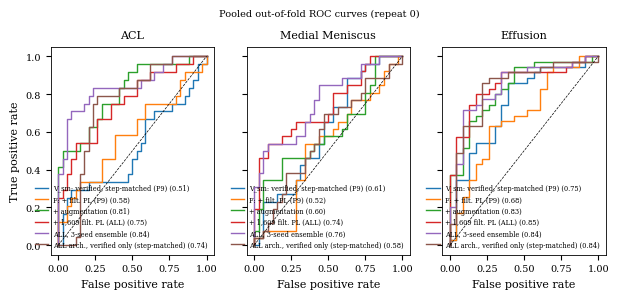

saved: /kaggle/working/knee_phase11_viz/fig11a_roc_repeat0.png


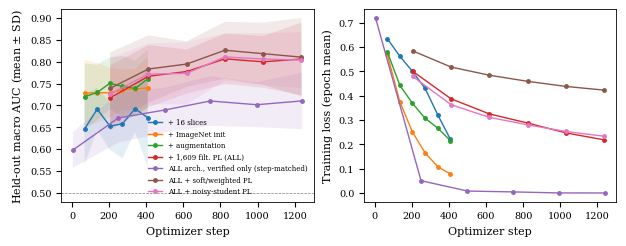

saved: /kaggle/working/knee_phase11_viz/fig11b_training_curves.png


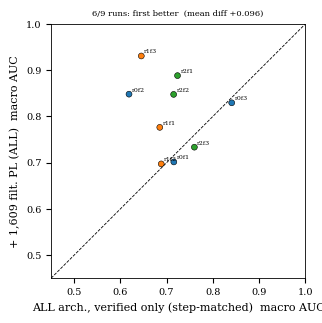

saved: /kaggle/working/knee_phase11_viz/fig11c_paired_ALL_vs_ALL_V.png


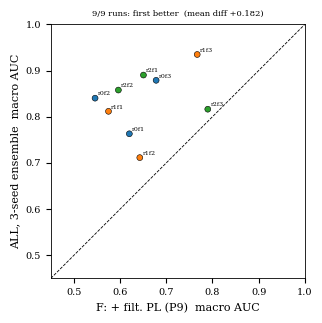

saved: /kaggle/working/knee_phase11_viz/fig11c_paired_ALL_ens_vs_Filtered.png


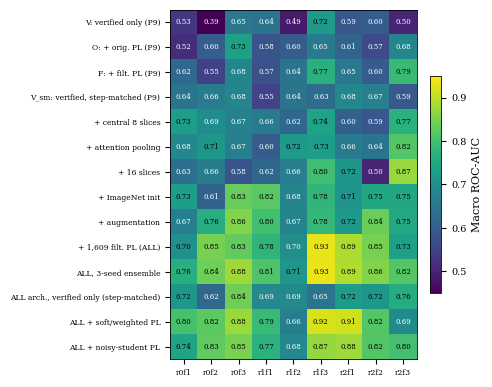

saved: /kaggle/working/knee_phase11_viz/fig11d_per_run_heatmap.png
[sanity] ALL r0 f1: 20 held-out studies, max |reloaded - stored| = 0.0011, mean = 0.0002  (small differences expected: fp16 autocast vs fp32)


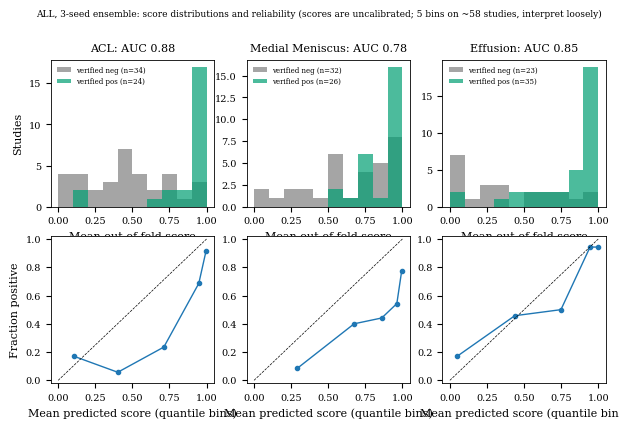

saved: /kaggle/working/knee_phase11_viz/fig11f_errors_ALL_ens.png


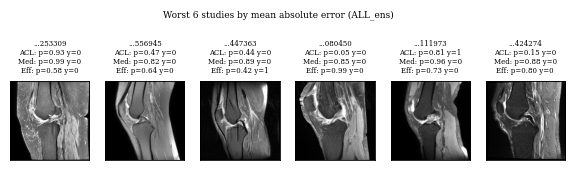

saved: /kaggle/working/knee_phase11_viz/fig11g_worst_studies_ALL_ens.png


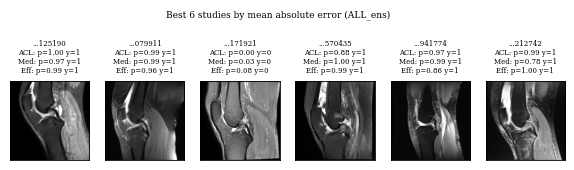

saved: /kaggle/working/knee_phase11_viz/fig11g_best_studies_ALL_ens.png
                                                                  p_ACL  p_Medial Meniscus  p_Effusion  y_ACL  y_Medial Meniscus  y_Effusion  mean_abs_err
StudyInstanceUID                                                                                                                                          
1.2.826.0.1.3680043.8.498.15593638897292057356864060466120253309   0.93               0.99        0.58    0.0                0.0         0.0          0.83
1.2.826.0.1.3680043.8.498.12448079646359892252441208258836556945   0.47               0.82        0.64    0.0                0.0         0.0          0.64
1.2.826.0.1.3680043.8.498.56512564464301544960446419143135447363   0.44               0.89        0.42    0.0                0.0         1.0          0.64
1.2.826.0.1.3680043.8.498.54977581323931277817074741182670080450   0.05               0.85        0.99    0.0                0.0         0.0          0.6

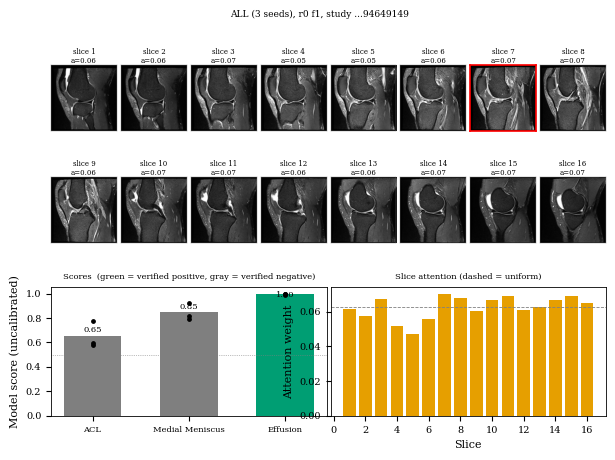

saved: /kaggle/working/knee_phase11_viz/fig11e_study_94649149_ALL.png
verified truth: {'ACL': 0, 'Medial Meniscus': 0, 'Effusion': 1}
scores:         {'ACL': 0.652999997138977, 'Medial Meniscus': 0.8460000157356262, 'Effusion': 0.9959999918937683}
status:         HELD OUT in repeat 0, fold 1 (honest out-of-sample prediction)


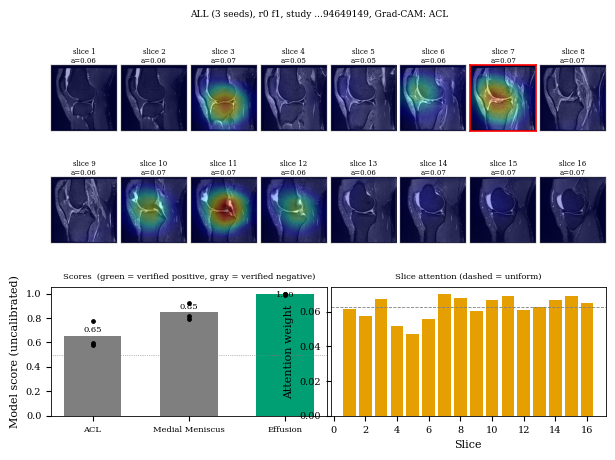

saved: /kaggle/working/knee_phase11_viz/fig11e_study_94649149_ALL_cam_ACL.png

All figures saved in /kaggle/working/knee_phase11_viz


In [29]:
p11_all()

In [30]:
import shutil

In [33]:
shutil.make_archive("/kaggle/working/", "zip", "/kaggle/working/knee_phase11_viz")

'/kaggle/working/.zip'